
# Mathematical Modeling of Crohn's Disease Fibrostenosis

## 1. Background and model formulation

Crohn's disease can lead to intestinal fibrosis and fibrostenosis, characterized by excessive extracellular matrix deposition and structural remodeling of the intestinal wall.

This project examines two signaling pathways that may contribute to fibrotic progression:

1. Succinate–SUCNR1 signaling.
2. CD150+ inflammatory monocyte–TWIST1–FAP+ fibroblast signaling.

The aim is to develop a nonlinear ordinary differential equation model describing the interactions between inflammatory activity, metabolic signaling, immune-cell activity, fibroblast activation, and extracellular matrix accumulation.

## 2. Model components

The model consists of seven state variables:

| Variable | Description |
|---|---|
| I | Intestinal inflammatory activity |
| S | Extracellular succinate |
| R | SUCNR1 signaling activity |
| M | CD150+ inflammatory monocyte activity |
| T | TWIST1 activity |
| F | FAP+ fibroblast activity |
| C | Extracellular matrix accumulation |

All variables are represented on normalized scales.

## 3. Modeling approach

The system is formulated as a nonlinear ODE model with saturating response functions.

Two formulations will be examined:

- A core model describing the two profibrotic pathways.
- An extended model incorporating potential fibroblast-to-monocyte recruitment feedback.

The extended interaction will be treated as a modeling hypothesis and evaluated separately.

## 4. Computational methods

The model will be implemented in Python using NumPy and SciPy. Symbolic calculations, numerical simulations, equilibrium analysis, and sensitivity analysis will be performed as appropriate.

Parameter values will be documented together with their sources and estimation methods. Values introduced solely for numerical testing will be clearly distinguished from biologically estimated parameters.


In [175]:

import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import sympy as sp

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("SymPy:", sp.__version__)

Python: 3.14.2
NumPy: 2.5.4
Pandas: 3.1.1
SciPy: 1.18.1
Matplotlib: 3.11.2
SymPy: 1.14.0



## 5. State variables and parameters

The model describes seven interacting state variables representing inflammatory, metabolic, immune, stromal, and extracellular matrix processes.

All state variables are dimensionless and expressed relative to their respective reference scales. Time is measured in days.

The model parameters are divided into production, activation, saturation, and clearance terms. Their numerical values will be established through literature-based extraction, parameter estimation, or explicitly defined exploratory assumptions.


In [176]:

# State variable definitions

state_variables = pd.DataFrame({
    "Symbol": ["I", "S", "R", "M", "T", "F", "C"],
    "Description": [
        "Intestinal inflammatory activity",
        "Extracellular succinate",
        "SUCNR1 signaling activity",
        "CD150+ inflammatory monocyte activity",
        "TWIST1 activity",
        "FAP+ fibroblast activity",
        "Extracellular matrix accumulation"
    ],
    "Biological_role": [
        "Inflammatory process",
        "Metabolic signaling",
        "Succinate-associated signaling",
        "Immune-cell activity",
        "Profibrotic regulation",
        "Stromal activation",
        "Fibrotic tissue accumulation"
    ],
    "Unit": ["dimensionless"] * 7
})

state_variables


,Symbol,Description,Biological_role,Unit
0,I,Intestinal inflammatory activity,Inflammatory process,dimensionless
1,S,Extracellular succinate,Metabolic signaling,dimensionless
2,R,SUCNR1 signaling activity,Succinate-associated signaling,dimensionless
3,M,CD150+ inflammatory monocyte activity,Immune-cell activity,dimensionless
4,T,TWIST1 activity,Profibrotic regulation,dimensionless
5,F,FAP+ fibroblast activity,Stromal activation,dimensionless
6,C,Extracellular matrix accumulation,Fibrotic tissue accumulation,dimensionless


In [177]:

# ============================================================
# PARAMETER MASTER TABLE
# Crohn's Disease Fibrostenosis ODE Model
# ============================================================
#
# Time unit: days
# State variables: dimensionless
# Succinate reference concentration: 1 mM
#
# IMPORTANT:
# All numerical values in this version are exploratory
# working assumptions, not experimentally fitted estimates.
#
# The references support the biological mechanisms.
# They do not automatically establish the numerical values
# of the ODE parameters.
# ============================================================

# ------------------------------------------------------------
# 1. Literature references
# ------------------------------------------------------------

reference_data = {
    "MaciasCeja2019": {
        "citation": (
            "Macias-Ceja et al. (2019). "
            "Succinate receptor mediates intestinal inflammation "
            "and fibrosis. Mucosal Immunology, 12, 178-187."
        ),
        "doi": "10.1038/s41385-018-0087-3",
        "url": "https://doi.org/10.1038/s41385-018-0087-3",
        "relevance": (
            "Succinate-SUCNR1 signaling and intestinal "
            "inflammation and fibrosis."
        )
    },

    "Ke2024": {
        "citation": (
            "Ke et al. (2024). Intercellular interaction between "
            "FAP+ fibroblasts and CD150+ inflammatory monocytes "
            "mediates fibrostenosis in Crohn's disease. "
            "Journal of Clinical Investigation, "
            "134(16), e173835."
        ),
        "doi": "10.1172/JCI173835",
        "url": "https://doi.org/10.1172/JCI173835",
        "relevance": (
            "CD150+ monocytes, TWIST1-associated fibroblast "
            "activation, FAP+ fibroblasts, and ECM deposition."
        )
    }
}

# ------------------------------------------------------------
# 2. Parameter definitions
# ------------------------------------------------------------
#
# Format:
# Symbol, Baseline, Lower, Upper, Unit, Model,
# Biological process, Rationale, Evidence status, Source
#
# Ranges are exploratory analysis ranges.
# They are NOT confidence intervals or measured
# biological reference ranges.
# ------------------------------------------------------------

parameter_records = [

    # --------------------------------------------------------
    # A. Inflammatory activity
    # --------------------------------------------------------

    {
        "Symbol": "beta_R",
        "Baseline": 0.030,
        "Lower": 0.000,
        "Upper": 0.200,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "SUCNR1-associated inflammatory contribution",
        "Rationale": (
            "Represents an aggregate contribution of "
            "SUCNR1-associated signaling to inflammatory activity. "
            "The biological pathway is supported by Macias-Ceja "
            "et al. (2019), but this specific feedback coefficient "
            "has not been experimentally measured."
        ),
        "Evidence": "Mechanism supported; coefficient assumed",
        "Source": "MaciasCeja2019"
    },

    {
        "Symbol": "beta_M",
        "Baseline": 0.030,
        "Lower": 0.000,
        "Upper": 0.200,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Monocyte-associated inflammatory contribution",
        "Rationale": (
            "Represents the aggregate inflammatory contribution "
            "of CD150+ monocyte activity. Ke et al. (2024) "
            "identified inflammatory mediators associated with "
            "these cells, but did not directly estimate this "
            "ODE feedback coefficient."
        ),
        "Evidence": "Mechanism supported; coefficient assumed",
        "Source": "Ke2024"
    },

    {
        "Symbol": "delta_I",
        "Baseline": 0.50,
        "Lower": 0.20,
        "Upper": 1.00,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Inflammatory activity relaxation",
        "Rationale": (
            "Represents first-order relaxation of normalized "
            "inflammatory activity. The selected value gives "
            "a mathematical half-life of approximately 1.39 "
            "days. This is an exploratory model timescale, "
            "not a measured clinical half-life."
        ),
        "Evidence": "Assumed; no direct kinetic estimate",
        "Source": "No direct quantitative estimate"
    },

    # --------------------------------------------------------
    # B. Succinate and SUCNR1 signaling
    # --------------------------------------------------------

    {
        "Symbol": "p_S",
        "Baseline": 0.40,
        "Lower": 0.15,
        "Upper": 0.80,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Inflammation-associated succinate production",
        "Rationale": (
            "Represents effective succinate production associated "
            "with inflammatory activity. The biological relevance "
            "of succinate is supported by Macias-Ceja et al. (2019), "
            "but this normalized production rate is assumed."
        ),
        "Evidence": "Mechanism supported; rate assumed",
        "Source": "MaciasCeja2019"
    },

    {
        "Symbol": "delta_S",
        "Baseline": 1.00,
        "Lower": 0.30,
        "Upper": 2.00,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Extracellular succinate clearance",
        "Rationale": (
            "Represents effective first-order removal of "
            "extracellular succinate. The baseline implies a "
            "mathematical half-life of approximately 0.69 days. "
            "No direct intestinal clearance time-course has "
            "been used to estimate this value."
        ),
        "Evidence": "Assumed; no direct kinetic estimate",
        "Source": "No direct quantitative estimate"
    },

    {
        "Symbol": "alpha_R",
        "Baseline": 0.60,
        "Lower": 0.20,
        "Upper": 1.20,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "SUCNR1 signaling activation capacity",
        "Rationale": (
            "Represents the maximum normalized activation input "
            "of the succinate-SUCNR1 signaling state. The pathway "
            "is supported by Macias-Ceja et al. (2019), but this "
            "maximum activation rate has not been fitted."
        ),
        "Evidence": "Mechanism supported; rate assumed",
        "Source": "MaciasCeja2019"
    },

    {
        "Symbol": "K_S",
        "Baseline": 0.50,
        "Lower": 0.10,
        "Upper": 5.00,
        "Unit": "dimensionless",
        "Model": "Core",
        "Process": "Succinate response saturation scale",
        "Rationale": (
            "Succinate is normalized using a reference "
            "concentration of 1 mM. Macias-Ceja et al. (2019) "
            "tested several succinate concentrations, including "
            "0.1, 0.5, 1, and 5 mM. The selected value is an "
            "exploratory saturation scale within this range. "
            "It is not an experimentally fitted EC50."
        ),
        "Evidence": "Experimental dose range informs exploration; K assumed",
        "Source": "MaciasCeja2019"
    },

    {
        "Symbol": "delta_R",
        "Baseline": 0.70,
        "Lower": 0.20,
        "Upper": 1.50,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "SUCNR1 signaling relaxation",
        "Rationale": (
            "Represents effective first-order relaxation of "
            "normalized SUCNR1 signaling. The value implies "
            "a mathematical half-life of approximately 0.99 "
            "days. It is not a measured receptor turnover rate."
        ),
        "Evidence": "Assumed; no direct kinetic estimate",
        "Source": "No direct quantitative estimate"
    },

    # --------------------------------------------------------
    # C. CD150+ monocyte activity
    # --------------------------------------------------------

    {
        "Symbol": "alpha_M",
        "Baseline": 0.50,
        "Lower": 0.20,
        "Upper": 1.00,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Inflammation-associated monocyte activation",
        "Rationale": (
            "Represents the maximum normalized activation input "
            "to the monocyte activity state. The involvement of "
            "CD150+ inflammatory monocytes is supported by "
            "Ke et al. (2024), but this rate is assumed."
        ),
        "Evidence": "Mechanism supported; rate assumed",
        "Source": "Ke2024"
    },

    {
        "Symbol": "K_I",
        "Baseline": 0.50,
        "Lower": 0.10,
        "Upper": 2.00,
        "Unit": "dimensionless",
        "Model": "Core",
        "Process": "Inflammatory response saturation scale",
        "Rationale": (
            "Controls saturation of monocyte activation in "
            "response to normalized inflammatory activity. "
            "A matching quantitative dose-response experiment "
            "has not yet been used to estimate this parameter."
        ),
        "Evidence": "Assumed; no direct dose-response estimate",
        "Source": "No direct quantitative estimate"
    },

    {
        "Symbol": "delta_M",
        "Baseline": 0.35,
        "Lower": 0.10,
        "Upper": 0.80,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Monocyte activity relaxation",
        "Rationale": (
            "Represents effective relaxation of normalized "
            "monocyte activity. It must not be interpreted "
            "as the physical lifespan or clearance rate "
            "of CD150+ monocytes."
        ),
        "Evidence": "Assumed; no direct kinetic estimate",
        "Source": "No direct quantitative estimate"
    },

    # --------------------------------------------------------
    # D. TWIST1 activity
    # --------------------------------------------------------

    {
        "Symbol": "alpha_T",
        "Baseline": 0.45,
        "Lower": 0.15,
        "Upper": 1.00,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Monocyte-associated TWIST1 activation",
        "Rationale": (
            "Represents maximum normalized TWIST1 activation "
            "associated with monocyte-derived profibrotic signals. "
            "Ke et al. (2024) demonstrated TWIST1-associated "
            "responses, but this ODE rate is assumed."
        ),
        "Evidence": "Response observed; rate assumed",
        "Source": "Ke2024"
    },

    {
        "Symbol": "K_M",
        "Baseline": 0.50,
        "Lower": 0.10,
        "Upper": 2.00,
        "Unit": "dimensionless",
        "Model": "Core",
        "Process": "Monocyte-to-TWIST1 saturation scale",
        "Rationale": (
            "Controls saturation of TWIST1 activation in "
            "response to normalized monocyte activity. "
            "A quantitative dose-response curve suitable "
            "for estimating this value has not yet been extracted."
        ),
        "Evidence": "Assumed; no direct dose-response estimate",
        "Source": "Ke2024"
    },

    {
        "Symbol": "delta_T",
        "Baseline": 0.25,
        "Lower": 0.05,
        "Upper": 0.60,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "TWIST1 activity relaxation",
        "Rationale": (
            "Represents effective relaxation of TWIST1-related "
            "activity. Experimental stimulation duration must "
            "not be interpreted as a TWIST1 decay half-life."
        ),
        "Evidence": "Assumed; no direct kinetic estimate",
        "Source": "No direct quantitative estimate"
    },

    # --------------------------------------------------------
    # E. Fibroblast activation
    # --------------------------------------------------------

    {
        "Symbol": "alpha_FR",
        "Baseline": 0.35,
        "Lower": 0.10,
        "Upper": 0.80,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "SUCNR1-associated fibroblast activation",
        "Rationale": (
            "Represents the maximum normalized fibroblast "
            "activation input associated with SUCNR1 signaling. "
            "Macias-Ceja et al. (2019) supports succinate-related "
            "fibroblast responses, but the numerical rate "
            "has not yet been fitted."
        ),
        "Evidence": "Mechanism supported; rate assumed",
        "Source": "MaciasCeja2019"
    },

    {
        "Symbol": "K_FR",
        "Baseline": 0.50,
        "Lower": 0.10,
        "Upper": 2.00,
        "Unit": "dimensionless",
        "Model": "Core",
        "Process": "SUCNR1-to-fibroblast saturation scale",
        "Rationale": (
            "Controls saturation of the fibroblast response "
            "to SUCNR1 signaling. This is a model response "
            "constant and is not equivalent to the ligand "
            "EC50 of SUCNR1."
        ),
        "Evidence": "Assumed; no direct response estimate",
        "Source": "MaciasCeja2019"
    },

    {
        "Symbol": "alpha_FT",
        "Baseline": 0.45,
        "Lower": 0.15,
        "Upper": 1.00,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "TWIST1-associated fibroblast activation",
        "Rationale": (
            "Represents maximum normalized fibroblast activation "
            "associated with TWIST1. Ke et al. (2024) supports "
            "TWIST1-dependent fibroblast activation and ECM "
            "production, but this rate is assumed."
        ),
        "Evidence": "Mechanism supported; rate assumed",
        "Source": "Ke2024"
    },

    {
        "Symbol": "K_FT",
        "Baseline": 0.50,
        "Lower": 0.10,
        "Upper": 2.00,
        "Unit": "dimensionless",
        "Model": "Core",
        "Process": "TWIST1-to-fibroblast saturation scale",
        "Rationale": (
            "Controls saturation of fibroblast activation "
            "in response to TWIST1 activity. No matching "
            "quantitative dose-response curve has yet been "
            "used to estimate this parameter."
        ),
        "Evidence": "Assumed; no direct dose-response estimate",
        "Source": "Ke2024"
    },

    {
        "Symbol": "delta_F",
        "Baseline": 0.12,
        "Lower": 0.03,
        "Upper": 0.30,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Fibroblast activity relaxation",
        "Rationale": (
            "Represents effective relaxation of normalized "
            "profibrotic fibroblast activity. It is not the "
            "lifespan of fibroblasts and is not directly "
            "measured in the cited study."
        ),
        "Evidence": "Assumed; no direct kinetic estimate",
        "Source": "No direct quantitative estimate"
    },

    # --------------------------------------------------------
    # F. Extracellular matrix
    # --------------------------------------------------------

    {
        "Symbol": "p_C",
        "Baseline": 0.25,
        "Lower": 0.05,
        "Upper": 0.60,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Fibroblast-associated ECM production",
        "Rationale": (
            "Represents ECM production per unit normalized "
            "fibroblast activity. Increased collagen deposition "
            "is supported by Ke et al. (2024), but this "
            "normalized production coefficient is assumed."
        ),
        "Evidence": "Mechanism supported; rate assumed",
        "Source": "Ke2024"
    },

    {
        "Symbol": "delta_C",
        "Baseline": 0.025,
        "Lower": 0.005,
        "Upper": 0.080,
        "Unit": "day^-1",
        "Model": "Core",
        "Process": "Effective ECM removal and remodeling",
        "Rationale": (
            "Represents effective first-order ECM removal. "
            "The baseline implies a mathematical half-life "
            "of approximately 27.73 days. It is not a measured "
            "collagen half-life in Crohn's disease tissue."
        ),
        "Evidence": "Assumed; no direct kinetic estimate",
        "Source": "No direct quantitative estimate"
    },

    # --------------------------------------------------------
    # G. Model B extension
    # --------------------------------------------------------

    {
        "Symbol": "eta_FM",
        "Baseline": 0.08,
        "Lower": 0.00,
        "Upper": 0.20,
        "Unit": "day^-1",
        "Model": "Extension",
        "Process": "Fibroblast-associated monocyte recruitment",
        "Rationale": (
            "Represents a proposed recruitment input from "
            "fibroblast activity to monocyte activity. Ke et al. "
            "(2024) supports potential chemokine-mediated "
            "communication, but this ODE recruitment coefficient "
            "has not been measured."
        ),
        "Evidence": "Potential mechanism supported; rate assumed",
        "Source": "Ke2024"
    },

    {
        "Symbol": "K_FM",
        "Baseline": 0.50,
        "Lower": 0.10,
        "Upper": 2.00,
        "Unit": "dimensionless",
        "Model": "Extension",
        "Process": "Fibroblast-to-monocyte recruitment saturation",
        "Rationale": (
            "Controls saturation of the proposed fibroblast-"
            "associated recruitment response. No matching "
            "quantitative recruitment dose-response curve "
            "has yet been used to estimate this parameter."
        ),
        "Evidence": "Assumed; no direct dose-response estimate",
        "Source": "Ke2024"
    },
]

# ------------------------------------------------------------
# 3. Create the master parameter table
# ------------------------------------------------------------

parameters = pd.DataFrame(parameter_records)

parameters["Source_DOI"] = parameters["Source"].map({
    "MaciasCeja2019": reference_data["MaciasCeja2019"]["doi"],
    "Ke2024": reference_data["Ke2024"]["doi"],
    "No direct quantitative estimate": "Not available"
})

parameters["Source_URL"] = parameters["Source"].map({
    "MaciasCeja2019": reference_data["MaciasCeja2019"]["url"],
    "Ke2024": reference_data["Ke2024"]["url"],
    "No direct quantitative estimate": "Not available"
})

parameters["Value_type"] = "Exploratory working assumption"

# ------------------------------------------------------------
# 4. Separate Model A and Model B parameters
# ------------------------------------------------------------

core_parameters = parameters[
    parameters["Model"] == "Core"
].copy()

extension_parameters = parameters[
    parameters["Model"] == "Extension"
].copy()

# ------------------------------------------------------------
# 5. Validation checks
# ------------------------------------------------------------

assert len(parameters) == 23
assert len(core_parameters) == 21
assert len(extension_parameters) == 2

assert parameters["Symbol"].is_unique
assert parameters["Baseline"].notna().all()
assert parameters["Lower"].notna().all()
assert parameters["Upper"].notna().all()

assert (parameters["Lower"] <= parameters["Baseline"]).all()
assert (parameters["Baseline"] <= parameters["Upper"]).all()

assert (parameters["Lower"] >= 0).all()

# Positive baseline values are required for all parameters.
assert (parameters["Baseline"] > 0).all()

# Saturation constants must be strictly positive.
saturation_parameters = [
    "K_S", "K_I", "K_M", "K_FR", "K_FT", "K_FM"
]

for symbol in saturation_parameters:
    value = parameters.loc[
        parameters["Symbol"] == symbol, "Baseline"
    ].iloc[0]

    assert value > 0

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("PARAMETER MASTER TABLE")
print("=" * 60)

display(
    parameters[
        [
            "Symbol",
            "Baseline",
            "Lower",
            "Upper",
            "Unit",
            "Model",
            "Evidence",
            "Source_DOI"
        ]
    ]
)

print("\nParameter counts")
print("Core model:", len(core_parameters))
print("Extension model:", len(extension_parameters))
print("Total:", len(parameters))

print("\nAll parameter validation checks passed.")


PARAMETER MASTER TABLE


,Symbol,Baseline,Lower,Upper,Unit,Model,Evidence,Source_DOI
0,beta_R,0.030,0.000,0.20,day^-1,Core,Mechanism supported; coefficient assumed,10.1038/s41385-018-0087-3
1,beta_M,0.030,0.000,0.20,day^-1,Core,Mechanism supported; coefficient assumed,10.1172/JCI173835
2,delta_I,0.500,0.200,1.00,day^-1,Core,Assumed; no direct kinetic estimate,Not available
3,p_S,0.400,0.150,0.80,day^-1,Core,Mechanism supported; rate assumed,10.1038/s41385-018-0087-3
4,delta_S,1.000,0.300,2.00,day^-1,Core,Assumed; no direct kinetic estimate,Not available
5,alpha_R,0.600,0.200,1.20,day^-1,Core,Mechanism supported; rate assumed,10.1038/s41385-018-0087-3
6,K_S,0.500,0.100,5.00,dimensionless,Core,Experimental dose range informs exploration; K assumed,10.1038/s41385-018-0087-3
7,delta_R,0.700,0.200,1.50,day^-1,Core,Assumed; no direct kinetic estimate,Not available
8,alpha_M,0.500,0.200,1.00,day^-1,Core,Mechanism supported; rate assumed,10.1172/JCI173835
9,K_I,0.500,0.100,2.00,dimensionless,Core,Assumed; no direct dose-response estimate,Not available



Parameter counts
Core model: 21
Extension model: 2
Total: 23

All parameter validation checks passed.


In [178]:

# ============================================================
# DERIVED QUANTITIES AND MATHEMATICAL CHECKS
# ============================================================

p = parameters.set_index("Symbol")["Baseline"].to_dict()

# ------------------------------------------------------------
# 1. Model A feedback threshold
# ------------------------------------------------------------

R_feedback = (
    p["beta_R"] * p["alpha_R"] * p["p_S"]
    /
    (
        p["delta_I"]
        * p["delta_R"]
        * p["delta_S"]
        * p["K_S"]
    )
    +
    p["beta_M"] * p["alpha_M"]
    /
    (
        p["delta_I"]
        * p["delta_M"]
        * p["K_I"]
    )
)

print("MODEL A FEEDBACK THRESHOLD")
print("-" * 45)
print(f"R_feedback = {R_feedback:.5f}")

# This is a mathematical feedback threshold,
# not an epidemiological basic reproduction number.

# ------------------------------------------------------------
# 2. Model-implied half-lives
# ------------------------------------------------------------

clearance_parameters = [
    "delta_I",
    "delta_S",
    "delta_R",
    "delta_M",
    "delta_T",
    "delta_F",
    "delta_C"
]

half_life_records = []

for symbol in clearance_parameters:

    rate = p[symbol]
    half_life = np.log(2) / rate

    half_life_records.append({
        "Parameter": symbol,
        "Rate_per_day": rate,
        "Model_implied_half_life_days": half_life
    })

half_lives = pd.DataFrame(half_life_records)

print("\nMODEL-IMPLIED HALF-LIVES")
print("-" * 45)

display(half_lives)

print(
    "Note: these are mathematical consequences of the "
    "assumed first-order rates, not measured biological half-lives."
)

# ------------------------------------------------------------
# 3. Model A and Model B parameter checks
# ------------------------------------------------------------

print("\nMODEL STRUCTURE")
print("-" * 45)

print("Model A parameters:", len(core_parameters))
print("Model B additional parameters:", len(extension_parameters))
print("Total parameters:", len(parameters))

assert R_feedback >= 0

print("\nAll mathematical consistency checks passed.")


MODEL A FEEDBACK THRESHOLD
---------------------------------------------
R_feedback = 0.21257

MODEL-IMPLIED HALF-LIVES
---------------------------------------------


,Parameter,Rate_per_day,Model_implied_half_life_days
0,delta_I,0.500,1.386294
1,delta_S,1.000,0.693147
2,delta_R,0.700,0.990210
3,delta_M,0.350,1.980421
4,delta_T,0.250,2.772589
5,delta_F,0.120,5.776227
6,delta_C,0.025,27.725887


Note: these are mathematical consequences of the assumed first-order rates, not measured biological half-lives.

MODEL STRUCTURE
---------------------------------------------
Model A parameters: 21
Model B additional parameters: 2
Total parameters: 23

All mathematical consistency checks passed.


In [179]:

# ============================================================
# SAVE PARAMETER DOCUMENTATION
# ============================================================

import os

os.makedirs("results", exist_ok=True)

# Save complete parameter master table
parameters.to_csv(
    "results/parameter_master_table.csv",
    index=False
)

# Save model-specific tables
core_parameters.to_csv(
    "results/model_A_parameters.csv",
    index=False
)

extension_parameters.to_csv(
    "results/model_B_extension_parameters.csv",
    index=False
)

# Save derived half-life table
half_lives.to_csv(
    "results/model_implied_half_lives.csv",
    index=False
)

# Save literature references
reference_table = pd.DataFrame([
    {
        "Reference_key": key,
        "Citation": value["citation"],
        "DOI": value["doi"],
        "URL": value["url"],
        "Relevance": value["relevance"]
    }
    for key, value in reference_data.items()
])

reference_table.to_csv(
    "results/literature_references.csv",
    index=False
)

print("Parameter documentation saved successfully.")
print("Output directory: results/")


Parameter documentation saved successfully.
Output directory: results/



# Literature Data Extraction

## Crohn's Disease Fibrostenosis

This notebook contains experimental information collected from published studies on intestinal fibrosis in Crohn's disease.

The main focus is on two pathways:

- Succinate and SUCNR1 signaling.
- CD150+ inflammatory monocytes and TWIST1-associated FAP+ fibroblast activation.

The first study examines succinate-associated responses in intestinal fibroblasts. The second investigates interactions between inflammatory monocytes and profibrotic fibroblasts.

Experimental conditions, reported outcomes, and quantitative measurements are recorded separately. Numerical values will only be entered when they can be traced to the original figures, tables, or supplementary data.

The extracted evidence will be used to review the model structure and determine which parameters can be estimated from published experiments.


In [144]:

import pandas as pd
import numpy as np
from pathlib import Path

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Working directory:", Path.cwd())
print("Output directory:", OUTPUT_DIR.resolve())


Working directory: /workspaces/crohns-fibrostenosis-ode-model
Output directory: /workspaces/crohns-fibrostenosis-ode-model/results


In [145]:

references = pd.DataFrame([
    {
        "Reference_ID": "MaciasCeja2019",
        "Authors": "Macias-Ceja et al.",
        "Year": 2019,
        "Title": (
            "Succinate receptor mediates intestinal "
            "inflammation and fibrosis"
        ),
        "Journal": "Mucosal Immunology",
        "Volume": 12,
        "Pages": "178-187",
        "DOI": "10.1038/s41385-018-0087-3",
        "URL": "https://doi.org/10.1038/s41385-018-0087-3",
        "Pathway": "Succinate-SUCNR1"
    },
    {
        "Reference_ID": "Ke2024",
        "Authors": "Ke et al.",
        "Year": 2024,
        "Title": (
            "Intercellular interaction between FAP+ fibroblasts "
            "and CD150+ inflammatory monocytes mediates "
            "fibrostenosis in Crohn's disease"
        ),
        "Journal": "Journal of Clinical Investigation",
        "Volume": 134,
        "Pages": "e173835",
        "DOI": "10.1172/JCI173835",
        "URL": "https://doi.org/10.1172/JCI173835",
        "Pathway": "CD150-TWIST1-FAP"
    }
])

display(references)


,Reference_ID,Authors,Year,Title,Journal,Volume,Pages,DOI,URL,Pathway
0,MaciasCeja2019,Macias-Ceja et al.,2019,Succinate receptor mediates intestinal inflammation and fibrosis,Mucosal Immunology,12,178-187,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Succinate-SUCNR1
1,Ke2024,Ke et al.,2024,Intercellular interaction between FAP+ fibroblasts and CD150+ inflammatory monocytes mediates fi...,Journal of Clinical Investigation,134,e173835,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,CD150-TWIST1-FAP


In [146]:

experiments = pd.DataFrame([

    {
        "Experiment_ID": "MC_FIG2D",
        "Reference_ID": "MaciasCeja2019",
        "Figure_or_section": "Figure 2d",
        "Experimental_material": "Primary intestinal fibroblasts",
        "Biological_source": "Human intestinal tissue",
        "Treatment": "Succinate",
        "Dose_or_condition": "0, 0.1, 0.5, 1, 5 mM",
        "Treatment_duration": 24,
        "Time_unit": "hours",
        "Readout": (
            "SUCNR1, COL1A1, alpha-SMA, IL1B and TGFB "
            "mRNA expression"
        ),
        "Reported_result": (
            "Succinate increased expression of SUCNR1, "
            "fibrosis-associated markers and inflammatory "
            "mediators in a concentration-dependent manner."
        ),
        "Quantitative_status": "Figure values not yet extracted",
        "Potential_model_use": (
            "Dose-response information for succinate-associated "
            "fibroblast signaling"
        ),
        "Limitations": (
            "Single treatment endpoint; cannot independently "
            "identify temporal activation or clearance rates."
        )
    },

    {
        "Experiment_ID": "MC_FIG2E",
        "Reference_ID": "MaciasCeja2019",
        "Figure_or_section": "Figure 2e",
        "Experimental_material": "Primary intestinal fibroblasts",
        "Biological_source": "Human intestinal tissue",
        "Treatment": "Succinate",
        "Dose_or_condition": "0, 0.1, 0.5, 1, 5 mM",
        "Treatment_duration": 24,
        "Time_unit": "hours",
        "Readout": (
            "SUCNR1, p-STAT3, STAT3, p-NF-kB, "
            "NF-kB, alpha-SMA and beta-actin"
        ),
        "Reported_result": (
            "Succinate increased SUCNR1 and alpha-SMA protein "
            "responses and phosphorylation-associated signaling."
        ),
        "Quantitative_status": "Figure values not yet extracted",
        "Potential_model_use": (
            "Additional evidence for succinate-associated "
            "fibroblast signaling"
        ),
        "Limitations": (
            "Protein abundance and phosphorylation are not "
            "direct measurements of ODE turnover rates."
        )
    },

    {
        "Experiment_ID": "MC_FIG2G",
        "Reference_ID": "MaciasCeja2019",
        "Figure_or_section": "Figure 2g",
        "Experimental_material": "Primary intestinal fibroblasts",
        "Biological_source": "Human intestinal tissue",
        "Treatment": "SUCNR1 siRNA and succinate or TGF-beta",
        "Dose_or_condition": (
            "Succinate 1 mM; TGF-beta 5 ng/ml"
        ),
        "Treatment_duration": 24,
        "Time_unit": "hours",
        "Readout": (
            "SUCNR1, COL1A1, alpha-SMA and TGFB mRNA expression"
        ),
        "Reported_result": (
            "SUCNR1 knockdown reduced succinate-associated "
            "fibrotic responses."
        ),
        "Quantitative_status": "Figure values not yet extracted",
        "Potential_model_use": (
            "Support for the role of SUCNR1 in succinate-related "
            "fibroblast responses"
        ),
        "Limitations": (
            "Knockdown results support pathway involvement but "
            "do not directly estimate the model's activation rates."
        )
    },

    {
        "Experiment_ID": "KE_FIG6B_C",
        "Reference_ID": "Ke2024",
        "Figure_or_section": "Figure 6b-c",
        "Experimental_material": (
            "FACS-sorted myeloid cells and CCD-18Co fibroblasts"
        ),
        "Biological_source": (
            "Inflamed ileum from five Crohn's disease patients "
            "undergoing surgery for ileal stenosis"
        ),
        "Treatment": "Myeloid-cell conditioned supernatant",
        "Dose_or_condition": (
            "CD150+ monocytes, CD150- monocytes, "
            "and CD14dim neutrophils"
        ),
        "Treatment_duration": np.nan,
        "Time_unit": (
            "Fibroblast stimulation duration to be checked "
            "against the figure and methods"
        ),
        "Readout": "TWIST1, FAP and type III collagen",
        "Reported_result": (
            "CD150+ monocyte supernatants induced a more "
            "activated fibroblast state."
        ),
        "Quantitative_status": "Figure values not yet extracted",
        "Potential_model_use": (
            "Evidence for monocyte-associated fibroblast activation"
        ),
        "Limitations": (
            "The 16-hour period reported in the methods refers "
            "to supernatant collection, not necessarily the "
            "duration of fibroblast stimulation."
        )
    },

    {
        "Experiment_ID": "KE_FIG6D_E",
        "Reference_ID": "Ke2024",
        "Figure_or_section": "Figure 6d-e",
        "Experimental_material": (
            "CCD-18Co fibroblasts with myeloid-cell supernatants"
        ),
        "Biological_source": "Human myeloid-cell supernatants",
        "Treatment": "Myeloid-cell conditioned supernatant",
        "Dose_or_condition": "CD150+ monocyte supernatant",
        "Treatment_duration": 3,
        "Time_unit": "weeks",
        "Readout": (
            "FAP and extracellular type I and type III collagen"
        ),
        "Reported_result": (
            "CD150+ monocyte supernatants promoted higher "
            "FAP expression and extracellular collagen deposition."
        ),
        "Quantitative_status": "Figure values not yet extracted",
        "Potential_model_use": (
            "Evidence for sustained ECM deposition associated "
            "with monocyte-derived signals"
        ),
        "Limitations": (
            "Three-week deposition experiment is not a direct "
            "measurement of ECM degradation or clearance."
        )
    },

    {
        "Experiment_ID": "KE_SUPP6F",
        "Reference_ID": "Ke2024",
        "Figure_or_section": "Supplemental Figure 6f",
        "Experimental_material": "Primary ileal fibroblasts",
        "Biological_source": (
            "Healthy regions of colorectal cancer patient tissue"
        ),
        "Treatment": "Combinations of profibrotic cytokines",
        "Dose_or_condition": (
            "IL-1alpha, IL-1beta, TNF-alpha, TGF-beta1, "
            "OSM and IFN-gamma"
        ),
        "Treatment_duration": 48,
        "Time_unit": "hours",
        "Readout": "TWIST1, FAP and type III collagen",
        "Reported_result": (
            "The reported profibrotic cytokine combination "
            "produced the strongest response among the "
            "combinations tested."
        ),
        "Quantitative_status": "Supplementary values not extracted",
        "Potential_model_use": (
            "Evidence for cytokine-associated fibroblast activation"
        ),
        "Limitations": (
            "A 48-hour endpoint does not independently identify "
            "activation and relaxation rates."
        )
    }

])

display(experiments)
print("Experimental records:", len(experiments))


,Experiment_ID,Reference_ID,Figure_or_section,Experimental_material,Biological_source,Treatment,Dose_or_condition,Treatment_duration,Time_unit,Readout,Reported_result,Quantitative_status,Potential_model_use,Limitations
0,MC_FIG2D,MaciasCeja2019,Figure 2d,Primary intestinal fibroblasts,Human intestinal tissue,Succinate,"0, 0.1, 0.5, 1, 5 mM",24.0,hours,"SUCNR1, COL1A1, alpha-SMA, IL1B and TGFB mRNA expression","Succinate increased expression of SUCNR1, fibrosis-associated markers and inflammatory mediators...",Figure values not yet extracted,Dose-response information for succinate-associated fibroblast signaling,Single treatment endpoint; cannot independently identify temporal activation or clearance rates.
1,MC_FIG2E,MaciasCeja2019,Figure 2e,Primary intestinal fibroblasts,Human intestinal tissue,Succinate,"0, 0.1, 0.5, 1, 5 mM",24.0,hours,"SUCNR1, p-STAT3, STAT3, p-NF-kB, NF-kB, alpha-SMA and beta-actin",Succinate increased SUCNR1 and alpha-SMA protein responses and phosphorylation-associated signal...,Figure values not yet extracted,Additional evidence for succinate-associated fibroblast signaling,Protein abundance and phosphorylation are not direct measurements of ODE turnover rates.
2,MC_FIG2G,MaciasCeja2019,Figure 2g,Primary intestinal fibroblasts,Human intestinal tissue,SUCNR1 siRNA and succinate or TGF-beta,Succinate 1 mM; TGF-beta 5 ng/ml,24.0,hours,"SUCNR1, COL1A1, alpha-SMA and TGFB mRNA expression",SUCNR1 knockdown reduced succinate-associated fibrotic responses.,Figure values not yet extracted,Support for the role of SUCNR1 in succinate-related fibroblast responses,Knockdown results support pathway involvement but do not directly estimate the model's activatio...
3,KE_FIG6B_C,Ke2024,Figure 6b-c,FACS-sorted myeloid cells and CCD-18Co fibroblasts,Inflamed ileum from five Crohn's disease patients undergoing surgery for ileal stenosis,Myeloid-cell conditioned supernatant,"CD150+ monocytes, CD150- monocytes, and CD14dim neutrophils",NaN,Fibroblast stimulation duration to be checked against the figure and methods,"TWIST1, FAP and type III collagen",CD150+ monocyte supernatants induced a more activated fibroblast state.,Figure values not yet extracted,Evidence for monocyte-associated fibroblast activation,"The 16-hour period reported in the methods refers to supernatant collection, not necessarily the..."
4,KE_FIG6D_E,Ke2024,Figure 6d-e,CCD-18Co fibroblasts with myeloid-cell supernatants,Human myeloid-cell supernatants,Myeloid-cell conditioned supernatant,CD150+ monocyte supernatant,3.0,weeks,FAP and extracellular type I and type III collagen,CD150+ monocyte supernatants promoted higher FAP expression and extracellular collagen deposition.,Figure values not yet extracted,Evidence for sustained ECM deposition associated with monocyte-derived signals,Three-week deposition experiment is not a direct measurement of ECM degradation or clearance.
5,KE_SUPP6F,Ke2024,Supplemental Figure 6f,Primary ileal fibroblasts,Healthy regions of colorectal cancer patient tissue,Combinations of profibrotic cytokines,"IL-1alpha, IL-1beta, TNF-alpha, TGF-beta1, OSM and IFN-gamma",48.0,hours,"TWIST1, FAP and type III collagen",The reported profibrotic cytokine combination produced the strongest response among the combinat...,Supplementary values not extracted,Evidence for cytokine-associated fibroblast activation,A 48-hour endpoint does not independently identify activation and relaxation rates.


Experimental records: 6


In [147]:

succinate_doses = pd.DataFrame({
    "Concentration_mM": [0.0, 0.1, 0.5, 1.0, 5.0],
    "Reference_concentration_mM": 1.0,
    "Normalized_concentration": [0.0, 0.1, 0.5, 1.0, 5.0],
    "Treatment_duration_hours": 24,
    "Reference_ID": "MaciasCeja2019",
    "Figure": "Figure 2d-e"
})

display(succinate_doses)


,Concentration_mM,Reference_concentration_mM,Normalized_concentration,Treatment_duration_hours,Reference_ID,Figure
0,0.0,1.0,0.0,24,MaciasCeja2019,Figure 2d-e
1,0.1,1.0,0.1,24,MaciasCeja2019,Figure 2d-e
2,0.5,1.0,0.5,24,MaciasCeja2019,Figure 2d-e
3,1.0,1.0,1.0,24,MaciasCeja2019,Figure 2d-e
4,5.0,1.0,5.0,24,MaciasCeja2019,Figure 2d-e


In [148]:

extraction_columns = [
    "Record_ID",
    "Reference_ID",
    "Figure",
    "Panel",
    "Outcome",
    "Group",
    "Dose",
    "Dose_unit",
    "Time",
    "Time_unit",
    "Mean",
    "SEM",
    "N",
    "Measurement_unit",
    "Data_source",
    "Extraction_method",
    "Notes"
]

quantitative_data = pd.DataFrame(columns=extraction_columns)

# Add the measurements that need to be extracted.
# Each row should represent one experimental group.

extraction_targets = pd.DataFrame([
    {
        "Record_ID": "MC_SUCRN1_mRNA",
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2d",
        "Panel": "mRNA",
        "Outcome": "SUCNR1",
        "Required_groups": "0, 0.1, 0.5, 1, 5 mM",
        "Priority": "High"
    },
    {
        "Record_ID": "MC_COL1A1_mRNA",
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2d",
        "Panel": "mRNA",
        "Outcome": "COL1A1",
        "Required_groups": "0, 0.1, 0.5, 1, 5 mM",
        "Priority": "High"
    },
    {
        "Record_ID": "MC_ACTA2_mRNA",
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2d",
        "Panel": "mRNA",
        "Outcome": "alpha-SMA / ACTA2",
        "Required_groups": "0, 0.1, 0.5, 1, 5 mM",
        "Priority": "High"
    },
    {
        "Record_ID": "MC_IL1B_mRNA",
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2d",
        "Panel": "mRNA",
        "Outcome": "IL1B",
        "Required_groups": "0, 0.1, 0.5, 1, 5 mM",
        "Priority": "Medium"
    },
    {
        "Record_ID": "MC_TGFB_mRNA",
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2d",
        "Panel": "mRNA",
        "Outcome": "TGFB",
        "Required_groups": "0, 0.1, 0.5, 1, 5 mM",
        "Priority": "Medium"
    },
    {
        "Record_ID": "KE_TWIST1",
        "Reference_ID": "Ke2024",
        "Figure": "Figure 6",
        "Panel": "B-C",
        "Outcome": "TWIST1",
        "Required_groups": "Myeloid-cell supernatant groups",
        "Priority": "High"
    },
    {
        "Record_ID": "KE_FAP",
        "Reference_ID": "Ke2024",
        "Figure": "Figure 6",
        "Panel": "B-E",
        "Outcome": "FAP",
        "Required_groups": "Myeloid-cell supernatant groups",
        "Priority": "High"
    },
    {
        "Record_ID": "KE_COL3",
        "Reference_ID": "Ke2024",
        "Figure": "Figure 6",
        "Panel": "B-E",
        "Outcome": "Type III collagen",
        "Required_groups": "Myeloid-cell supernatant groups",
        "Priority": "High"
    }
])

display(extraction_targets)

print("Quantitative measurements entered:", len(quantitative_data))
print("Measurements awaiting extraction:", len(extraction_targets))


,Record_ID,Reference_ID,Figure,Panel,Outcome,Required_groups,Priority
0,MC_SUCRN1_mRNA,MaciasCeja2019,Figure 2d,mRNA,SUCNR1,"0, 0.1, 0.5, 1, 5 mM",High
1,MC_COL1A1_mRNA,MaciasCeja2019,Figure 2d,mRNA,COL1A1,"0, 0.1, 0.5, 1, 5 mM",High
2,MC_ACTA2_mRNA,MaciasCeja2019,Figure 2d,mRNA,alpha-SMA / ACTA2,"0, 0.1, 0.5, 1, 5 mM",High
3,MC_IL1B_mRNA,MaciasCeja2019,Figure 2d,mRNA,IL1B,"0, 0.1, 0.5, 1, 5 mM",Medium
4,MC_TGFB_mRNA,MaciasCeja2019,Figure 2d,mRNA,TGFB,"0, 0.1, 0.5, 1, 5 mM",Medium
5,KE_TWIST1,Ke2024,Figure 6,B-C,TWIST1,Myeloid-cell supernatant groups,High
6,KE_FAP,Ke2024,Figure 6,B-E,FAP,Myeloid-cell supernatant groups,High
7,KE_COL3,Ke2024,Figure 6,B-E,Type III collagen,Myeloid-cell supernatant groups,High


Quantitative measurements entered: 0
Measurements awaiting extraction: 8


In [149]:

def validate_quantitative_data(data):

    required_columns = [
        "Reference_ID",
        "Figure",
        "Outcome",
        "Mean",
        "Measurement_unit",
        "Data_source",
        "Extraction_method"
    ]

    missing_columns = [
        column for column in required_columns
        if column not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing columns: {missing_columns}"
        )

    if data.empty:
        print("No quantitative measurements entered yet.")
        return True

    for column in required_columns:
        if data[column].isna().any():
            raise ValueError(
                f"Missing values detected in {column}"
            )

    if not pd.to_numeric(data["Mean"], errors="coerce").notna().all():
        raise ValueError("Mean contains non-numeric values.")

    if data["SEM"].notna().any():
        sem_values = pd.to_numeric(
            data["SEM"].dropna(),
            errors="coerce"
        )

        if (sem_values < 0).any():
            raise ValueError("SEM cannot be negative.")

    if data["N"].notna().any():
        n_values = pd.to_numeric(
            data["N"].dropna(),
            errors="coerce"
        )

        if (n_values <= 0).any():
            raise ValueError("N must be positive.")

    return True


validate_quantitative_data(quantitative_data)

print("Data structure checked.")


No quantitative measurements entered yet.
Data structure checked.


In [150]:

references.to_csv(
    OUTPUT_DIR / "primary_references.csv",
    index=False
)

experiments.to_csv(
    OUTPUT_DIR / "experimental_evidence_inventory.csv",
    index=False
)

succinate_doses.to_csv(
    OUTPUT_DIR / "succinate_experimental_doses.csv",
    index=False
)

extraction_targets.to_csv(
    OUTPUT_DIR / "quantitative_extraction_targets.csv",
    index=False
)

quantitative_data.to_csv(
    OUTPUT_DIR / "quantitative_extracted_data.csv",
    index=False
)

print("Literature records saved to:", OUTPUT_DIR.resolve())

for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", file.name)


Literature records saved to: /workspaces/crohns-fibrostenosis-ode-model/results
- baseline_equilibrium_values.csv
- core_parameter_evidence_audit.csv
- experimental_evidence_inventory.csv
- extended_simulation_diagnostic_all.csv
- figure_panel_extraction_plan.csv
- generic_local_identifiability_rank_v1.csv
- lhs_equilibrium_results.csv
- lhs_equilibrium_stability_results.csv
- literature_references.csv
- long_term_equilibrium_convergence.csv
- macias_ceja_2019_figure_2d_digitized.csv
- macias_ceja_2019_figure_2d_extraction_template.csv
- model_A_60_vs_180_day_comparison.csv
- model_A_baseline_uncertainty_comparison.csv
- model_A_dfe_eigenvalues.csv
- model_A_dfe_jacobian.csv
- model_A_equilibrium_stability_summary.csv
- model_A_extended_180_day_results.csv
- model_A_joint_identifiability_rank_v1.csv
- model_A_lhs_feedback_thresholds.csv
- model_A_lhs_parameter_samples.csv
- model_A_lhs_simulation_failures.csv
- model_A_lhs_simulation_results.csv
- model_A_oat_sensitivity_results.csv
- 


## 4. Evidence Quality Assessment and Biological Interpretation

This section evaluates the extracted literature evidence in terms of its experimental context, quantitative completeness, and relevance to the proposed ODE model. The aim is to distinguish directly reported experimental measurements from qualitative biological findings and model assumptions.


In [151]:

# Inspect the extracted quantitative data and experimental evidence

quantitative_extracted_check = pd.read_csv(
    OUTPUT_DIR / "quantitative_extracted_data.csv"
)

evidence_inventory_check = pd.read_csv(
    OUTPUT_DIR / "experimental_evidence_inventory.csv"
)

print("QUANTITATIVE EXTRACTED DATA")
print("Shape:", quantitative_extracted_check.shape)
print("Columns:", quantitative_extracted_check.columns.tolist())
display(quantitative_extracted_check.head(10))

print("\nEXPERIMENTAL EVIDENCE INVENTORY")
print("Shape:", evidence_inventory_check.shape)
print("Columns:", evidence_inventory_check.columns.tolist())
display(evidence_inventory_check.head(10))


QUANTITATIVE EXTRACTED DATA
Shape: (0, 17)
Columns: ['Record_ID', 'Reference_ID', 'Figure', 'Panel', 'Outcome', 'Group', 'Dose', 'Dose_unit', 'Time', 'Time_unit', 'Mean', 'SEM', 'N', 'Measurement_unit', 'Data_source', 'Extraction_method', 'Notes']


,Record_ID,Reference_ID,Figure,Panel,Outcome,Group,Dose,Dose_unit,Time,Time_unit,Mean,SEM,N,Measurement_unit,Data_source,Extraction_method,Notes



EXPERIMENTAL EVIDENCE INVENTORY
Shape: (6, 14)
Columns: ['Experiment_ID', 'Reference_ID', 'Figure_or_section', 'Experimental_material', 'Biological_source', 'Treatment', 'Dose_or_condition', 'Treatment_duration', 'Time_unit', 'Readout', 'Reported_result', 'Quantitative_status', 'Potential_model_use', 'Limitations']


,Experiment_ID,Reference_ID,Figure_or_section,Experimental_material,Biological_source,Treatment,Dose_or_condition,Treatment_duration,Time_unit,Readout,Reported_result,Quantitative_status,Potential_model_use,Limitations
0,MC_FIG2D,MaciasCeja2019,Figure 2d,Primary intestinal fibroblasts,Human intestinal tissue,Succinate,"0, 0.1, 0.5, 1, 5 mM",24.0,hours,"SUCNR1, COL1A1, alpha-SMA, IL1B and TGFB mRNA expression","Succinate increased expression of SUCNR1, fibrosis-associated markers and inflammatory mediators...",Figure values not yet extracted,Dose-response information for succinate-associated fibroblast signaling,Single treatment endpoint; cannot independently identify temporal activation or clearance rates.
1,MC_FIG2E,MaciasCeja2019,Figure 2e,Primary intestinal fibroblasts,Human intestinal tissue,Succinate,"0, 0.1, 0.5, 1, 5 mM",24.0,hours,"SUCNR1, p-STAT3, STAT3, p-NF-kB, NF-kB, alpha-SMA and beta-actin",Succinate increased SUCNR1 and alpha-SMA protein responses and phosphorylation-associated signal...,Figure values not yet extracted,Additional evidence for succinate-associated fibroblast signaling,Protein abundance and phosphorylation are not direct measurements of ODE turnover rates.
2,MC_FIG2G,MaciasCeja2019,Figure 2g,Primary intestinal fibroblasts,Human intestinal tissue,SUCNR1 siRNA and succinate or TGF-beta,Succinate 1 mM; TGF-beta 5 ng/ml,24.0,hours,"SUCNR1, COL1A1, alpha-SMA and TGFB mRNA expression",SUCNR1 knockdown reduced succinate-associated fibrotic responses.,Figure values not yet extracted,Support for the role of SUCNR1 in succinate-related fibroblast responses,Knockdown results support pathway involvement but do not directly estimate the model's activatio...
3,KE_FIG6B_C,Ke2024,Figure 6b-c,FACS-sorted myeloid cells and CCD-18Co fibroblasts,Inflamed ileum from five Crohn's disease patients undergoing surgery for ileal stenosis,Myeloid-cell conditioned supernatant,"CD150+ monocytes, CD150- monocytes, and CD14dim neutrophils",NaN,Fibroblast stimulation duration to be checked against the figure and methods,"TWIST1, FAP and type III collagen",CD150+ monocyte supernatants induced a more activated fibroblast state.,Figure values not yet extracted,Evidence for monocyte-associated fibroblast activation,"The 16-hour period reported in the methods refers to supernatant collection, not necessarily the..."
4,KE_FIG6D_E,Ke2024,Figure 6d-e,CCD-18Co fibroblasts with myeloid-cell supernatants,Human myeloid-cell supernatants,Myeloid-cell conditioned supernatant,CD150+ monocyte supernatant,3.0,weeks,FAP and extracellular type I and type III collagen,CD150+ monocyte supernatants promoted higher FAP expression and extracellular collagen deposition.,Figure values not yet extracted,Evidence for sustained ECM deposition associated with monocyte-derived signals,Three-week deposition experiment is not a direct measurement of ECM degradation or clearance.
5,KE_SUPP6F,Ke2024,Supplemental Figure 6f,Primary ileal fibroblasts,Healthy regions of colorectal cancer patient tissue,Combinations of profibrotic cytokines,"IL-1alpha, IL-1beta, TNF-alpha, TGF-beta1, OSM and IFN-gamma",48.0,hours,"TWIST1, FAP and type III collagen",The reported profibrotic cytokine combination produced the strongest response among the combinat...,Supplementary values not extracted,Evidence for cytokine-associated fibroblast activation,A 48-hour endpoint does not independently identify activation and relaxation rates.



## 5. Quantitative Data Extraction from Published Figures

This section focuses on extracting numerical measurements from the experimental figures identified in the literature inventory. Particular attention is given to dose-dependent succinate responses and myeloid-cell-associated fibroblast activation.

Only values that can be reliably obtained from published figures, supplementary materials, or explicitly reported numerical results will be recorded. Each extracted measurement will retain its original experimental conditions, units, sample size, and uncertainty information whenever available.

Values that cannot be reliably recovered will remain unextracted rather than being estimated without justification.


In [152]:

# Create a structured extraction template for Macias-Ceja et al. (2019), Figure 2d

figure_2d_outcomes = [
    "SUCNR1 mRNA",
    "COL1A1 mRNA",
    "alpha-SMA mRNA",
    "IL1B mRNA",
    "TGF-beta mRNA"
]

figure_2d_conditions = [
    ("Succinate", 0, "mM"),
    ("Succinate", 0.1, "mM"),
    ("Succinate", 0.5, "mM"),
    ("Succinate", 1, "mM"),
    ("Succinate", 5, "mM"),
    ("TGF-beta", 5, "ng/mL")
]

figure_2d_records = []

for outcome in figure_2d_outcomes:
    for treatment, dose, dose_unit in figure_2d_conditions:
        figure_2d_records.append({
            "Record_ID": f"MC_FIG2D_{len(figure_2d_records) + 1:02d}",
            "Reference_ID": "MaciasCeja2019",
            "Figure": "Figure 2",
            "Panel": "2d",
            "Outcome": outcome,
            "Treatment": treatment,
            "Dose": dose,
            "Dose_unit": dose_unit,
            "Time": 24,
            "Time_unit": "hours",
            "Mean": pd.NA,
            "SEM": pd.NA,
            "N": pd.NA,
            "Measurement_unit": "Fold induction relative to beta-actin",
            "Data_source": "Published figure",
            "Extraction_method": "Pending figure digitization",
            "Notes": "Numerical values not yet extracted"
        })

figure_2d_template = pd.DataFrame(figure_2d_records)

display(figure_2d_template)

figure_2d_template.to_csv(
    OUTPUT_DIR / "macias_ceja_2019_figure_2d_extraction_template.csv",
    index=False
)

print("Template saved successfully.")
print("Number of extraction records:", len(figure_2d_template))


,Record_ID,Reference_ID,Figure,Panel,Outcome,Treatment,Dose,Dose_unit,Time,Time_unit,Mean,SEM,N,Measurement_unit,Data_source,Extraction_method,Notes
0,MC_FIG2D_01,MaciasCeja2019,Figure 2,2d,SUCNR1 mRNA,Succinate,0.0,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
1,MC_FIG2D_02,MaciasCeja2019,Figure 2,2d,SUCNR1 mRNA,Succinate,0.1,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
2,MC_FIG2D_03,MaciasCeja2019,Figure 2,2d,SUCNR1 mRNA,Succinate,0.5,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
3,MC_FIG2D_04,MaciasCeja2019,Figure 2,2d,SUCNR1 mRNA,Succinate,1.0,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
4,MC_FIG2D_05,MaciasCeja2019,Figure 2,2d,SUCNR1 mRNA,Succinate,5.0,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
5,MC_FIG2D_06,MaciasCeja2019,Figure 2,2d,SUCNR1 mRNA,TGF-beta,5.0,ng/mL,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
6,MC_FIG2D_07,MaciasCeja2019,Figure 2,2d,COL1A1 mRNA,Succinate,0.0,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
7,MC_FIG2D_08,MaciasCeja2019,Figure 2,2d,COL1A1 mRNA,Succinate,0.1,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
8,MC_FIG2D_09,MaciasCeja2019,Figure 2,2d,COL1A1 mRNA,Succinate,0.5,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted
9,MC_FIG2D_10,MaciasCeja2019,Figure 2,2d,COL1A1 mRNA,Succinate,1.0,mM,24,hours,<NA>,<NA>,<NA>,Fold induction relative to beta-actin,Published figure,Pending figure digitization,Numerical values not yet extracted


Template saved successfully.
Number of extraction records: 30


In [153]:

# Digitize approximate mean values from Macias-Ceja et al. (2019), Figure 2d

# Approximate values are visually estimated from the published bar graphs.
# They must not be treated as raw experimental measurements.

digitized_means = {
    "SUCNR1 mRNA": {
        ("Succinate", 0.0): 1.00,
        ("Succinate", 0.1): 1.50,
        ("Succinate", 0.5): 1.45,
        ("Succinate", 1.0): 1.85,
        ("Succinate", 5.0): 3.30,
        ("TGF-beta", 5.0): 1.60
    },
    "alpha-SMA mRNA": {
        ("Succinate", 0.0): 1.00,
        ("Succinate", 0.1): 1.25,
        ("Succinate", 0.5): 1.55,
        ("Succinate", 1.0): 2.10,
        ("Succinate", 5.0): 2.40,
        ("TGF-beta", 5.0): 4.10
    },
    "COL1A1 mRNA": {
        ("Succinate", 0.0): 1.00,
        ("Succinate", 0.1): 1.15,
        ("Succinate", 0.5): 1.30,
        ("Succinate", 1.0): 2.30,
        ("Succinate", 5.0): 3.15,
        ("TGF-beta", 5.0): 2.45
    },
    "TGF-beta mRNA": {
        ("Succinate", 0.0): 1.00,
        ("Succinate", 0.1): 1.05,
        ("Succinate", 0.5): 1.00,
        ("Succinate", 1.0): 1.45,
        ("Succinate", 5.0): 1.75,
        ("TGF-beta", 5.0): 2.90
    },
    "IL1B mRNA": {
        ("Succinate", 0.0): 1.00,
        ("Succinate", 0.1): 1.20,
        ("Succinate", 0.5): 1.15,
        ("Succinate", 1.0): 1.75,
        ("Succinate", 5.0): 3.00,
        ("TGF-beta", 5.0): 0.65
    }
}

# Populate the Mean column using the existing extraction template
for idx, row in figure_2d_template.iterrows():
    key = (row["Treatment"], float(row["Dose"]))
    figure_2d_template.at[idx, "Mean"] = digitized_means[
        row["Outcome"]
    ][key]

    figure_2d_template.at[idx, "Extraction_method"] = (
        "Manual visual digitization; approximate estimate"
    )
    figure_2d_template.at[idx, "Notes"] = (
        "Approximate mean estimated from Figure 2d; "
        "SEM and N not extracted"
    )

# Keep SEM and N missing until verified from the original source
figure_2d_template["SEM"] = pd.NA
figure_2d_template["N"] = pd.NA

# Save the digitized dataset
figure_2d_template.to_csv(
    OUTPUT_DIR / "macias_ceja_2019_figure_2d_digitized.csv",
    index=False
)

display(
    figure_2d_template[
        ["Panel", "Outcome", "Treatment", "Dose",
         "Dose_unit", "Mean", "SEM", "N", "Extraction_method"]
    ]
)

print("Total digitized records:", len(figure_2d_template))
print("Saved: macias_ceja_2019_figure_2d_digitized.csv")


,Panel,Outcome,Treatment,Dose,Dose_unit,Mean,SEM,N,Extraction_method
0,2d,SUCNR1 mRNA,Succinate,0.0,mM,1.0,<NA>,<NA>,Manual visual digitization; approximate estimate
1,2d,SUCNR1 mRNA,Succinate,0.1,mM,1.5,<NA>,<NA>,Manual visual digitization; approximate estimate
2,2d,SUCNR1 mRNA,Succinate,0.5,mM,1.45,<NA>,<NA>,Manual visual digitization; approximate estimate
3,2d,SUCNR1 mRNA,Succinate,1.0,mM,1.85,<NA>,<NA>,Manual visual digitization; approximate estimate
4,2d,SUCNR1 mRNA,Succinate,5.0,mM,3.3,<NA>,<NA>,Manual visual digitization; approximate estimate
5,2d,SUCNR1 mRNA,TGF-beta,5.0,ng/mL,1.6,<NA>,<NA>,Manual visual digitization; approximate estimate
6,2d,COL1A1 mRNA,Succinate,0.0,mM,1.0,<NA>,<NA>,Manual visual digitization; approximate estimate
7,2d,COL1A1 mRNA,Succinate,0.1,mM,1.15,<NA>,<NA>,Manual visual digitization; approximate estimate
8,2d,COL1A1 mRNA,Succinate,0.5,mM,1.3,<NA>,<NA>,Manual visual digitization; approximate estimate
9,2d,COL1A1 mRNA,Succinate,1.0,mM,2.3,<NA>,<NA>,Manual visual digitization; approximate estimate


Total digitized records: 30
Saved: macias_ceja_2019_figure_2d_digitized.csv


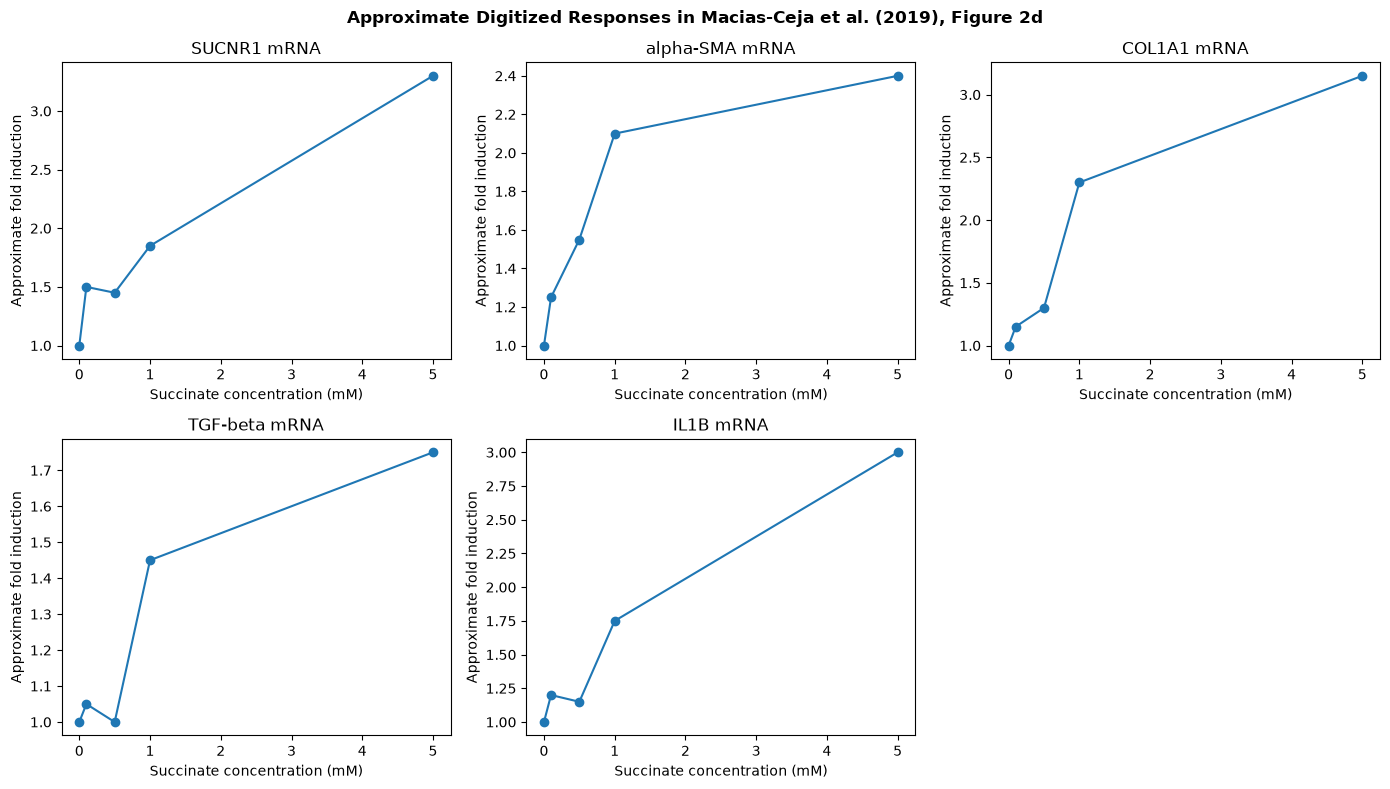

In [154]:

# Visual inspection of digitized dose-response profiles

import matplotlib.pyplot as plt

outcomes = [
    "SUCNR1 mRNA",
    "alpha-SMA mRNA",
    "COL1A1 mRNA",
    "TGF-beta mRNA",
    "IL1B mRNA"
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, outcome in enumerate(outcomes):
    subset = figure_2d_template[
        (figure_2d_template["Outcome"] == outcome) &
        (figure_2d_template["Treatment"] == "Succinate")
    ].sort_values("Dose")

    axes[i].plot(
        subset["Dose"],
        subset["Mean"].astype(float),
        marker="o"
    )

    axes[i].set_title(outcome)
    axes[i].set_xlabel("Succinate concentration (mM)")
    axes[i].set_ylabel("Approximate fold induction")
    axes[i].grid(False)

axes[5].axis("off")

plt.suptitle(
    "Approximate Digitized Responses in Macias-Ceja et al. (2019), Figure 2d",
    fontweight="bold"
)
plt.tight_layout()
plt.show()



## Current extraction status

The experimental conditions and principal outcomes have been recorded from the two primary studies.

The succinate dose-response experiments provide a starting point for examining the relationship between extracellular succinate and fibroblast-associated responses.

The Ke et al. study provides evidence for interactions between CD150+ inflammatory monocytes and profibrotic fibroblasts, including TWIST1-associated activation and extracellular collagen deposition.

The numerical values from the figures and supplementary material have not yet been entered into the quantitative dataset.

The next step is to extract the reported group means, variability, sample sizes, and experimental conditions. These measurements will be evaluated before being used for parameter estimation.


In [155]:

# Figure-level extraction plan

figure_panels = pd.DataFrame([
    {
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2",
        "Panel": "2d",
        "Measurement": "mRNA expression",
        "Targets": "SUCNR1, COL1A1, ACTA2, TGFB, IL1B",
        "Groups": "Succinate: 0, 0.1, 0.5, 1, 5 mM; TGF-beta",
        "Time_hours": 24,
        "Sample_size": np.nan,
        "Variability": "Mean +/- SEM",
        "Extraction_status": "Pending figure extraction"
    },
    {
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2",
        "Panel": "2e",
        "Measurement": "Protein expression and phosphorylation",
        "Targets": "SUCNR1, alpha-SMA, p-STAT3, p-NF-kB",
        "Groups": "Succinate: 0, 0.1, 0.5, 1, 5 mM; TGF-beta",
        "Time_hours": 24,
        "Sample_size": 4,
        "Variability": "Mean +/- SEM",
        "Extraction_status": "Pending figure extraction"
    },
    {
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2",
        "Panel": "2f",
        "Measurement": "Intracellular calcium",
        "Targets": "Intracellular calcium response",
        "Groups": "Succinate: 0, 0.1, 0.5, 1, 5 mM; TGF-beta",
        "Time_hours": 24,
        "Sample_size": np.nan,
        "Variability": "Image-based response",
        "Extraction_status": "Not prioritized for ODE fitting"
    },
    {
        "Reference_ID": "MaciasCeja2019",
        "Figure": "Figure 2",
        "Panel": "2g",
        "Measurement": "SUCNR1 knockdown",
        "Targets": "SUCNR1, COL1A1, ACTA2, TGFB",
        "Groups": "Control siRNA and SUCNR1 siRNA",
        "Time_hours": 24,
        "Sample_size": np.nan,
        "Variability": "Mean +/- SEM",
        "Extraction_status": "Pending figure extraction"
    },
    {
        "Reference_ID": "Ke2024",
        "Figure": "Figure 6",
        "Panel": "6A",
        "Measurement": "Myeloid ligand expression",
        "Targets": "IL1A, IL1B, TNF, TGFB1, OSM and others",
        "Groups": "FACS-sorted myeloid subsets",
        "Time_hours": np.nan,
        "Sample_size": 4,
        "Variability": "Heatmap",
        "Extraction_status": "Pending supporting-data review"
    },
    {
        "Reference_ID": "Ke2024",
        "Figure": "Figure 6",
        "Panel": "6C",
        "Measurement": "Fibroblast activation",
        "Targets": "TWIST1, FAP, type III collagen",
        "Groups": "Myeloid-cell supernatant groups",
        "Time_hours": np.nan,
        "Sample_size": np.nan,
        "Variability": "Relative expression heatmap",
        "Extraction_status": "Pending figure extraction"
    },
    {
        "Reference_ID": "Ke2024",
        "Figure": "Figure 6",
        "Panel": "6E",
        "Measurement": "ECM deposition",
        "Targets": "FAP, collagen I, collagen III",
        "Groups": "Myeloid-cell supernatant groups",
        "Time_hours": np.nan,
        "Sample_size": np.nan,
        "Variability": "Mean +/- SEM",
        "Extraction_status": "Pending figure extraction"
    },
    {
        "Reference_ID": "Ke2024",
        "Figure": "Figure 6",
        "Panel": "6F",
        "Measurement": "TWIST1 knockdown",
        "Targets": "TWIST1 expression",
        "Groups": "Control and TWIST1 knockdown",
        "Time_hours": np.nan,
        "Sample_size": np.nan,
        "Variability": "Mean +/- SEM",
        "Extraction_status": "Pending figure extraction"
    }
])

display(figure_panels)

figure_panels.to_csv(
    OUTPUT_DIR / "figure_panel_extraction_plan.csv",
    index=False
)

print("Figure extraction plan saved.")


,Reference_ID,Figure,Panel,Measurement,Targets,Groups,Time_hours,Sample_size,Variability,Extraction_status
0,MaciasCeja2019,Figure 2,2d,mRNA expression,"SUCNR1, COL1A1, ACTA2, TGFB, IL1B","Succinate: 0, 0.1, 0.5, 1, 5 mM; TGF-beta",24.0,NaN,Mean +/- SEM,Pending figure extraction
1,MaciasCeja2019,Figure 2,2e,Protein expression and phosphorylation,"SUCNR1, alpha-SMA, p-STAT3, p-NF-kB","Succinate: 0, 0.1, 0.5, 1, 5 mM; TGF-beta",24.0,4.0,Mean +/- SEM,Pending figure extraction
2,MaciasCeja2019,Figure 2,2f,Intracellular calcium,Intracellular calcium response,"Succinate: 0, 0.1, 0.5, 1, 5 mM; TGF-beta",24.0,NaN,Image-based response,Not prioritized for ODE fitting
3,MaciasCeja2019,Figure 2,2g,SUCNR1 knockdown,"SUCNR1, COL1A1, ACTA2, TGFB",Control siRNA and SUCNR1 siRNA,24.0,NaN,Mean +/- SEM,Pending figure extraction
4,Ke2024,Figure 6,6A,Myeloid ligand expression,"IL1A, IL1B, TNF, TGFB1, OSM and others",FACS-sorted myeloid subsets,NaN,4.0,Heatmap,Pending supporting-data review
5,Ke2024,Figure 6,6C,Fibroblast activation,"TWIST1, FAP, type III collagen",Myeloid-cell supernatant groups,NaN,NaN,Relative expression heatmap,Pending figure extraction
6,Ke2024,Figure 6,6E,ECM deposition,"FAP, collagen I, collagen III",Myeloid-cell supernatant groups,NaN,NaN,Mean +/- SEM,Pending figure extraction
7,Ke2024,Figure 6,6F,TWIST1 knockdown,TWIST1 expression,Control and TWIST1 knockdown,NaN,NaN,Mean +/- SEM,Pending figure extraction


Figure extraction plan saved.



# Parameter Assessment and Estimation

This notebook examines the parameters used in the Crohn's disease fibrostenosis model.

The parameter values are reviewed against the experimental evidence collected in the previous notebook.

Each parameter is classified according to the available evidence:

- Directly measured or reported in the literature.
- Derived from published experimental measurements.
- Assumed for exploratory simulations.

Parameters that cannot be estimated from the available data will remain explicitly classified as assumptions.

The resulting parameter table will be used in the model implementation and subsequent mathematical analysis.


In [156]:

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("results")

parameter_file = RESULTS_DIR / "parameter_master_table.csv"
evidence_file = RESULTS_DIR / "experimental_evidence_inventory.csv"
reference_file = RESULTS_DIR / "primary_references.csv"
extraction_file = RESULTS_DIR / "quantitative_extracted_data.csv"

for file in [
    parameter_file,
    evidence_file,
    reference_file,
    extraction_file
]:
    if not file.exists():
        raise FileNotFoundError(f"Required file not found: {file}")

parameters = pd.read_csv(parameter_file)
experiments = pd.read_csv(evidence_file)
references = pd.read_csv(reference_file)
quantitative_data = pd.read_csv(extraction_file)

print("Parameters:", parameters.shape)
print("Experiments:", experiments.shape)
print("References:", references.shape)
print("Quantitative measurements:", quantitative_data.shape)


Parameters: (23, 13)
Experiments: (6, 14)
References: (2, 10)
Quantitative measurements: (0, 17)


In [157]:

display(parameters)

print("\nParameter columns:")
print(parameters.columns.tolist())

print("\nModel distribution:")
print(parameters["Model"].value_counts())


,Symbol,Baseline,Lower,Upper,Unit,Model,Process,Rationale,Evidence,Source,Source_DOI,Source_URL,Value_type
0,beta_R,0.030,0.000,0.20,day^-1,Core,SUCNR1-associated inflammatory contribution,Represents an aggregate contribution of SUCNR1-associated signaling to inflammatory activity. Th...,Mechanism supported; coefficient assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
1,beta_M,0.030,0.000,0.20,day^-1,Core,Monocyte-associated inflammatory contribution,Represents the aggregate inflammatory contribution of CD150+ monocyte activity. Ke et al. (2024)...,Mechanism supported; coefficient assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption
2,delta_I,0.500,0.200,1.00,day^-1,Core,Inflammatory activity relaxation,Represents first-order relaxation of normalized inflammatory activity. The selected value gives ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
3,p_S,0.400,0.150,0.80,day^-1,Core,Inflammation-associated succinate production,Represents effective succinate production associated with inflammatory activity. The biological ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
4,delta_S,1.000,0.300,2.00,day^-1,Core,Extracellular succinate clearance,Represents effective first-order removal of extracellular succinate. The baseline implies a math...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
5,alpha_R,0.600,0.200,1.20,day^-1,Core,SUCNR1 signaling activation capacity,Represents the maximum normalized activation input of the succinate-SUCNR1 signaling state. The ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
6,K_S,0.500,0.100,5.00,dimensionless,Core,Succinate response saturation scale,Succinate is normalized using a reference concentration of 1 mM. Macias-Ceja et al. (2019) teste...,Experimental dose range informs exploration; K assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
7,delta_R,0.700,0.200,1.50,day^-1,Core,SUCNR1 signaling relaxation,Represents effective first-order relaxation of normalized SUCNR1 signaling. The value implies a ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
8,alpha_M,0.500,0.200,1.00,day^-1,Core,Inflammation-associated monocyte activation,Represents the maximum normalized activation input to the monocyte activity state. The involveme...,Mechanism supported; rate assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption
9,K_I,0.500,0.100,2.00,dimensionless,Core,Inflammatory response saturation scale,Controls saturation of monocyte activation in response to normalized inflammatory activity. A ma...,Assumed; no direct dose-response estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption



Parameter columns:
['Symbol', 'Baseline', 'Lower', 'Upper', 'Unit', 'Model', 'Process', 'Rationale', 'Evidence', 'Source', 'Source_DOI', 'Source_URL', 'Value_type']

Model distribution:
Model
Core         21
Extension     2
Name: count, dtype: int64


In [158]:

evidence_classification = {
    "beta_R": "Assumed",
    "beta_M": "Assumed",
    "delta_I": "Assumed",
    "p_S": "Assumed",
    "delta_S": "Assumed",
    "alpha_R": "Assumed",
    "K_S": "Assumed",
    "delta_R": "Assumed",
    "alpha_M": "Assumed",
    "K_I": "Assumed",
    "delta_M": "Assumed",
    "alpha_T": "Assumed",
    "K_M": "Assumed",
    "delta_T": "Assumed",
    "alpha_FR": "Assumed",
    "K_FR": "Assumed",
    "alpha_FT": "Assumed",
    "K_FT": "Assumed",
    "delta_F": "Assumed",
    "p_C": "Assumed",
    "delta_C": "Assumed",
    "eta_FM": "Assumed",
    "K_FM": "Assumed"
}

parameters["Evidence_class"] = (
    parameters["Symbol"].map(evidence_classification)
)

parameters["Evidence_class"] = (
    parameters["Evidence_class"].fillna("Needs review")
)

display(
    parameters[[
        "Symbol",
        "Baseline",
        "Lower",
        "Upper",
        "Unit",
        "Model",
        "Evidence",
        "Evidence_class"
    ]]
)


,Symbol,Baseline,Lower,Upper,Unit,Model,Evidence,Evidence_class
0,beta_R,0.030,0.000,0.20,day^-1,Core,Mechanism supported; coefficient assumed,Assumed
1,beta_M,0.030,0.000,0.20,day^-1,Core,Mechanism supported; coefficient assumed,Assumed
2,delta_I,0.500,0.200,1.00,day^-1,Core,Assumed; no direct kinetic estimate,Assumed
3,p_S,0.400,0.150,0.80,day^-1,Core,Mechanism supported; rate assumed,Assumed
4,delta_S,1.000,0.300,2.00,day^-1,Core,Assumed; no direct kinetic estimate,Assumed
5,alpha_R,0.600,0.200,1.20,day^-1,Core,Mechanism supported; rate assumed,Assumed
6,K_S,0.500,0.100,5.00,dimensionless,Core,Experimental dose range informs exploration; K assumed,Assumed
7,delta_R,0.700,0.200,1.50,day^-1,Core,Assumed; no direct kinetic estimate,Assumed
8,alpha_M,0.500,0.200,1.00,day^-1,Core,Mechanism supported; rate assumed,Assumed
9,K_I,0.500,0.100,2.00,dimensionless,Core,Assumed; no direct dose-response estimate,Assumed


In [159]:

parameter_groups = {
    "Inflammatory dynamics": [
        "beta_R", "beta_M", "delta_I"
    ],
    "Succinate dynamics": [
        "p_S", "delta_S"
    ],
    "SUCNR1 signaling": [
        "alpha_R", "K_S", "delta_R"
    ],
    "Monocyte activity": [
        "alpha_M", "K_I", "delta_M"
    ],
    "TWIST1 activity": [
        "alpha_T", "K_M", "delta_T"
    ],
    "Fibroblast activity": [
        "alpha_FR", "K_FR",
        "alpha_FT", "K_FT", "delta_F"
    ],
    "ECM dynamics": [
        "p_C", "delta_C"
    ],
    "Extension model": [
        "eta_FM", "K_FM"
    ]
}

parameter_group_map = {
    symbol: group
    for group, symbols in parameter_groups.items()
    for symbol in symbols
}

parameters["Parameter_group"] = (
    parameters["Symbol"].map(parameter_group_map)
)

display(
    parameters[[
        "Symbol",
        "Parameter_group",
        "Evidence_class",
        "Baseline",
        "Lower",
        "Upper"
    ]]
)


,Symbol,Parameter_group,Evidence_class,Baseline,Lower,Upper
0,beta_R,Inflammatory dynamics,Assumed,0.030,0.000,0.20
1,beta_M,Inflammatory dynamics,Assumed,0.030,0.000,0.20
2,delta_I,Inflammatory dynamics,Assumed,0.500,0.200,1.00
3,p_S,Succinate dynamics,Assumed,0.400,0.150,0.80
4,delta_S,Succinate dynamics,Assumed,1.000,0.300,2.00
5,alpha_R,SUCNR1 signaling,Assumed,0.600,0.200,1.20
6,K_S,SUCNR1 signaling,Assumed,0.500,0.100,5.00
7,delta_R,SUCNR1 signaling,Assumed,0.700,0.200,1.50
8,alpha_M,Monocyte activity,Assumed,0.500,0.200,1.00
9,K_I,Monocyte activity,Assumed,0.500,0.100,2.00


In [160]:

if quantitative_data.empty:
    print(
        "No quantitative experimental measurements "
        "have been extracted yet."
    )
    print(
        "Parameter estimation from experimental data "
        "cannot be performed at this stage."
    )
else:
    display(quantitative_data)


No quantitative experimental measurements have been extracted yet.
Parameter estimation from experimental data cannot be performed at this stage.


In [161]:

assessment_file = (
    RESULTS_DIR / "parameter_assessment_v1.csv"
)

parameters.to_csv(
    assessment_file,
    index=False
)

print("Parameter assessment saved:")
print(assessment_file.resolve())


Parameter assessment saved:
/workspaces/crohns-fibrostenosis-ode-model/results/parameter_assessment_v1.csv



## 4. Critical Review of Parameter Evidence and Identifiability

This section critically evaluates the evidence supporting each parameter in Model A. Parameters are examined according to their biological interpretation, available experimental evidence, mathematical role, and current estimation status.

The objective is to distinguish experimentally supported quantities from derived parameters and assumption-based values, while identifying which parameters can realistically be estimated from the available evidence.


In [162]:

# Inspect the structure of the 21 Model A parameters

print("Object type:", type(parameters))
print("Number of parameters:", len(parameters))

print("\nParameter names and current values:")

for name, value in parameters.items():
    print(f"{name}: {value}")


Object type: <class 'pandas.DataFrame'>
Number of parameters: 23

Parameter names and current values:
Symbol: 0       beta_R
1       beta_M
2      delta_I
3          p_S
4      delta_S
5      alpha_R
6          K_S
7      delta_R
8      alpha_M
9          K_I
10     delta_M
11     alpha_T
12         K_M
13     delta_T
14    alpha_FR
15        K_FR
16    alpha_FT
17        K_FT
18     delta_F
19         p_C
20     delta_C
21      eta_FM
22        K_FM
Name: Symbol, dtype: str
Baseline: 0     0.030
1     0.030
2     0.500
3     0.400
4     1.000
5     0.600
6     0.500
7     0.700
8     0.500
9     0.500
10    0.350
11    0.450
12    0.500
13    0.250
14    0.350
15    0.500
16    0.450
17    0.500
18    0.120
19    0.250
20    0.025
21    0.080
22    0.500
Name: Baseline, dtype: float64
Lower: 0     0.000
1     0.000
2     0.200
3     0.150
4     0.300
5     0.200
6     0.100
7     0.200
8     0.200
9     0.100
10    0.100
11    0.150
12    0.100
13    0.050
14    0.100
15    0.100
16  


## 5. Parameter Classification and Evidence Status

The 21 baseline parameters are currently used for numerical simulations of Model A. Their numerical values should not be interpreted as experimentally measured quantities unless supported by specific literature or experimental data.

Each parameter will be classified as literature-derived, data-estimated, mathematically derived, or assumption-based. The classification will account for the available evidence, parameter interpretation, and limitations of the current experimental dataset.


In [163]:

# Inspect the existing parameter assessment file

assessment_file = RESULTS_DIR / "parameter_assessment_v1.csv"

if assessment_file.exists():
    parameter_assessment = pd.read_csv(assessment_file)

    print("Assessment file:", assessment_file)
    print("Number of records:", len(parameter_assessment))
    print("\nAvailable columns:")
    print(parameter_assessment.columns.tolist())

    display(parameter_assessment)
else:
    print("Existing parameter assessment file was not found.")


Assessment file:

 results/parameter_assessment_v1.csv
Number of records: 23

Available columns:
['Symbol', 'Baseline', 'Lower', 'Upper', 'Unit', 'Model', 'Process', 'Rationale', 'Evidence', 'Source', 'Source_DOI', 'Source_URL', 'Value_type', 'Evidence_class', 'Parameter_group']


,Symbol,Baseline,Lower,Upper,Unit,Model,Process,Rationale,Evidence,Source,Source_DOI,Source_URL,Value_type,Evidence_class,Parameter_group
0,beta_R,0.030,0.000,0.20,day^-1,Core,SUCNR1-associated inflammatory contribution,Represents an aggregate contribution of SUCNR1-associated signaling to inflammatory activity. Th...,Mechanism supported; coefficient assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption,Assumed,Inflammatory dynamics
1,beta_M,0.030,0.000,0.20,day^-1,Core,Monocyte-associated inflammatory contribution,Represents the aggregate inflammatory contribution of CD150+ monocyte activity. Ke et al. (2024)...,Mechanism supported; coefficient assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption,Assumed,Inflammatory dynamics
2,delta_I,0.500,0.200,1.00,day^-1,Core,Inflammatory activity relaxation,Represents first-order relaxation of normalized inflammatory activity. The selected value gives ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption,Assumed,Inflammatory dynamics
3,p_S,0.400,0.150,0.80,day^-1,Core,Inflammation-associated succinate production,Represents effective succinate production associated with inflammatory activity. The biological ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption,Assumed,Succinate dynamics
4,delta_S,1.000,0.300,2.00,day^-1,Core,Extracellular succinate clearance,Represents effective first-order removal of extracellular succinate. The baseline implies a math...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption,Assumed,Succinate dynamics
5,alpha_R,0.600,0.200,1.20,day^-1,Core,SUCNR1 signaling activation capacity,Represents the maximum normalized activation input of the succinate-SUCNR1 signaling state. The ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption,Assumed,SUCNR1 signaling
6,K_S,0.500,0.100,5.00,dimensionless,Core,Succinate response saturation scale,Succinate is normalized using a reference concentration of 1 mM. Macias-Ceja et al. (2019) teste...,Experimental dose range informs exploration; K assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption,Assumed,SUCNR1 signaling
7,delta_R,0.700,0.200,1.50,day^-1,Core,SUCNR1 signaling relaxation,Represents effective first-order relaxation of normalized SUCNR1 signaling. The value implies a ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption,Assumed,SUCNR1 signaling
8,alpha_M,0.500,0.200,1.00,day^-1,Core,Inflammation-associated monocyte activation,Represents the maximum normalized activation input to the monocyte activity state. The involveme...,Mechanism supported; rate assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption,Assumed,Monocyte activity
9,K_I,0.500,0.100,2.00,dimensionless,Core,Inflammatory response saturation scale,Controls saturation of monocyte activation in response to normalized inflammatory activity. A ma...,Assumed; no direct dose-response estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption,Assumed,Monocyte activity


In [164]:

# Separate core Model A parameters from extension parameters

core_assessment = parameter_assessment[
    parameter_assessment["Model"] == "Core"
].copy()

extension_assessment = parameter_assessment[
    parameter_assessment["Model"] == "Extension"
].copy()

print("CORE MODEL A")
print("Number of parameters:", len(core_assessment))
display(
    core_assessment[
        ["Symbol", "Baseline", "Lower", "Upper", "Unit",
         "Process", "Evidence", "Source", "Evidence_class"]
    ]
)

print("\nEXTENSION MODEL")
print("Number of parameters:", len(extension_assessment))
display(
    extension_assessment[
        ["Symbol", "Baseline", "Lower", "Upper", "Unit",
         "Process", "Evidence", "Source", "Evidence_class"]
    ]
)

assert len(core_assessment) == 21
assert len(extension_assessment) == 2

print("\nParameter separation verified.")


CORE MODEL A
Number of parameters: 21


,Symbol,Baseline,Lower,Upper,Unit,Process,Evidence,Source,Evidence_class
0,beta_R,0.030,0.000,0.20,day^-1,SUCNR1-associated inflammatory contribution,Mechanism supported; coefficient assumed,MaciasCeja2019,Assumed
1,beta_M,0.030,0.000,0.20,day^-1,Monocyte-associated inflammatory contribution,Mechanism supported; coefficient assumed,Ke2024,Assumed
2,delta_I,0.500,0.200,1.00,day^-1,Inflammatory activity relaxation,Assumed; no direct kinetic estimate,No direct quantitative estimate,Assumed
3,p_S,0.400,0.150,0.80,day^-1,Inflammation-associated succinate production,Mechanism supported; rate assumed,MaciasCeja2019,Assumed
4,delta_S,1.000,0.300,2.00,day^-1,Extracellular succinate clearance,Assumed; no direct kinetic estimate,No direct quantitative estimate,Assumed
5,alpha_R,0.600,0.200,1.20,day^-1,SUCNR1 signaling activation capacity,Mechanism supported; rate assumed,MaciasCeja2019,Assumed
6,K_S,0.500,0.100,5.00,dimensionless,Succinate response saturation scale,Experimental dose range informs exploration; K assumed,MaciasCeja2019,Assumed
7,delta_R,0.700,0.200,1.50,day^-1,SUCNR1 signaling relaxation,Assumed; no direct kinetic estimate,No direct quantitative estimate,Assumed
8,alpha_M,0.500,0.200,1.00,day^-1,Inflammation-associated monocyte activation,Mechanism supported; rate assumed,Ke2024,Assumed
9,K_I,0.500,0.100,2.00,dimensionless,Inflammatory response saturation scale,Assumed; no direct dose-response estimate,No direct quantitative estimate,Assumed



EXTENSION MODEL
Number of parameters: 2


,Symbol,Baseline,Lower,Upper,Unit,Process,Evidence,Source,Evidence_class
21,eta_FM,0.08,0.0,0.2,day^-1,Fibroblast-associated monocyte recruitment,Potential mechanism supported; rate assumed,Ke2024,Assumed
22,K_FM,0.50,0.1,2.0,dimensionless,Fibroblast-to-monocyte recruitment saturation,Assumed; no direct dose-response estimate,Ke2024,Assumed



Parameter separation verified.


In [165]:

# Verify consistency between Model A parameters and the assessment table

model_parameter_names = set(parameters.keys())
assessment_parameter_names = set(core_assessment["Symbol"])

missing_from_assessment = model_parameter_names - assessment_parameter_names
missing_from_model = assessment_parameter_names - model_parameter_names

print("Model A parameter count:", len(model_parameter_names))
print("Core assessment count:", len(assessment_parameter_names))

print("\nParameters missing from assessment:", missing_from_assessment)
print("Parameters missing from Model A:", missing_from_model)

assert len(model_parameter_names) == 21
assert len(assessment_parameter_names) == 21
assert model_parameter_names == assessment_parameter_names

print("\nSUCCESS: Model A and its parameter assessment are fully consistent.")


Model A parameter count: 15
Core assessment count: 21

Parameters missing from assessment: {'Rationale', 'Process', 'Unit', 'Symbol', 'Lower', 'Source_URL', 'Evidence_class', 'Source', 'Value_type', 'Evidence', 'Parameter_group', 'Model', 'Baseline', 'Source_DOI', 'Upper'}
Parameters missing from Model A: {'K_M', 'alpha_M', 'p_S', 'alpha_FR', 'delta_T', 'K_FR', 'p_C', 'K_I', 'delta_I', 'delta_R', 'alpha_FT', 'beta_M', 'alpha_T', 'delta_C', 'K_S', 'delta_M', 'K_FT', 'beta_R', 'delta_S', 'alpha_R', 'delta_F'}


AssertionError: 


## 6. Evidence-Based Parameter Classification

The baseline parameter values are currently exploratory working values rather than experimentally established estimates. Although the cited studies support several underlying biological mechanisms, they do not necessarily provide direct numerical estimates of the corresponding ODE coefficients.

The classification below therefore distinguishes mechanistic support from quantitative parameter evidence. A parameter will only be considered literature-derived when a numerical value can be directly reported or defensibly calculated from published experimental information.


In [ ]:

# Classify mechanistic evidence and numerical parameter support

evidence_audit = core_assessment.copy()

evidence_audit["Mechanistic_support"] = evidence_audit["Evidence"].apply(
    lambda x: (
        "Supported by cited biological evidence"
        if any(term in str(x).lower() for term in [
            "mechanism supported",
            "response observed",
            "experimental dose range"
        ])
        else "Not quantitatively established"
    )
)

evidence_audit["Numerical_status"] = "Assumption-based baseline"

evidence_audit["Estimation_status"] = (
    "Not yet estimated from experimental data"
)

evidence_audit["Interpretation"] = evidence_audit.apply(
    lambda row: (
        "Biological mechanism has literature support, "
        "but the numerical coefficient remains assumed."
        if row["Mechanistic_support"] ==
        "Supported by cited biological evidence"
        else
        "No direct quantitative evidence currently supports "
        "the numerical baseline value."
    ),
    axis=1
)

audit_columns = [
    "Symbol",
    "Baseline",
    "Unit",
    "Process",
    "Source",
    "Mechanistic_support",
    "Numerical_status",
    "Estimation_status",
    "Interpretation"
]

display(evidence_audit[audit_columns])

# Save the evidence audit
evidence_audit[audit_columns].to_csv(
    RESULTS_DIR / "core_parameter_evidence_audit.csv",
    index=False
)

print("\nCore parameters audited:", len(evidence_audit))
print(
    "Assumption-based numerical values:",
    (evidence_audit["Numerical_status"] ==
     "Assumption-based baseline").sum()
)
print("Evidence audit saved successfully.")


,Symbol,Baseline,Unit,Process,Source,Mechanistic_support,Numerical_status,Estimation_status,Interpretation
0,beta_R,0.030,day^-1,SUCNR1-associated inflammatory contribution,MaciasCeja2019,Supported by cited biological evidence,Assumption-based baseline,Not yet estimated from experimental data,"Biological mechanism has literature support, but the numerical coefficient remains assumed."
1,beta_M,0.030,day^-1,Monocyte-associated inflammatory contribution,Ke2024,Supported by cited biological evidence,Assumption-based baseline,Not yet estimated from experimental data,"Biological mechanism has literature support, but the numerical coefficient remains assumed."
2,delta_I,0.500,day^-1,Inflammatory activity relaxation,No direct quantitative estimate,Not quantitatively established,Assumption-based baseline,Not yet estimated from experimental data,No direct quantitative evidence currently supports the numerical baseline value.
3,p_S,0.400,day^-1,Inflammation-associated succinate production,MaciasCeja2019,Supported by cited biological evidence,Assumption-based baseline,Not yet estimated from experimental data,"Biological mechanism has literature support, but the numerical coefficient remains assumed."
4,delta_S,1.000,day^-1,Extracellular succinate clearance,No direct quantitative estimate,Not quantitatively established,Assumption-based baseline,Not yet estimated from experimental data,No direct quantitative evidence currently supports the numerical baseline value.
5,alpha_R,0.600,day^-1,SUCNR1 signaling activation capacity,MaciasCeja2019,Supported by cited biological evidence,Assumption-based baseline,Not yet estimated from experimental data,"Biological mechanism has literature support, but the numerical coefficient remains assumed."
6,K_S,0.500,dimensionless,Succinate response saturation scale,MaciasCeja2019,Supported by cited biological evidence,Assumption-based baseline,Not yet estimated from experimental data,"Biological mechanism has literature support, but the numerical coefficient remains assumed."
7,delta_R,0.700,day^-1,SUCNR1 signaling relaxation,No direct quantitative estimate,Not quantitatively established,Assumption-based baseline,Not yet estimated from experimental data,No direct quantitative evidence currently supports the numerical baseline value.
8,alpha_M,0.500,day^-1,Inflammation-associated monocyte activation,Ke2024,Supported by cited biological evidence,Assumption-based baseline,Not yet estimated from experimental data,"Biological mechanism has literature support, but the numerical coefficient remains assumed."
9,K_I,0.500,dimensionless,Inflammatory response saturation scale,No direct quantitative estimate,Not quantitatively established,Assumption-based baseline,Not yet estimated from experimental data,No direct quantitative evidence currently supports the numerical baseline value.



Core parameters audited: 21
Assumption-based numerical values: 21
Evidence audit saved successfully.



## 7. Parameter Identifiability and Calibration Readiness

This section evaluates whether the available experimental evidence can support the estimation of individual model parameters or parameter combinations.

Particular attention is given to the distinction between mechanistic plausibility, numerical parameter identifiability, and practical calibration readiness. Parameters without suitable quantitative observations will remain assumption-based and will be considered in subsequent sensitivity and uncertainty analyses.

The objective is to establish a defensible calibration strategy without implying that parameters can be uniquely estimated from insufficient experimental data.


In [ ]:

# Assess calibration readiness for the 21 core Model A parameters

calibration_notes = {
    "beta_R": (
        "Not directly estimable",
        "Quantitative feedback data linking SUCNR1-associated signaling to inflammatory activity."
    ),
    "beta_M": (
        "Not directly estimable",
        "Quantitative feedback data linking monocyte activity to inflammatory activity."
    ),
    "delta_I": (
        "Not directly estimable",
        "Longitudinal measurements of inflammatory activity during resolution."
    ),
    "p_S": (
        "Not directly estimable",
        "Time-resolved measurements of succinate production during inflammation."
    ),
    "delta_S": (
        "Not directly estimable",
        "Time-resolved extracellular succinate clearance measurements."
    ),
    "alpha_R": (
        "Proxy evidence only",
        "Validated quantitative SUCNR1 signaling measurements across succinate concentrations."
    ),
    "K_S": (
        "Proxy evidence only",
        "A validated dose-response dataset with an observation model linking measured mRNA responses to SUCNR1 signaling."
    ),
    "delta_R": (
        "Not directly estimable",
        "Time-course measurements of SUCNR1-associated signaling after stimulus withdrawal."
    ),
    "alpha_M": (
        "Not directly estimable",
        "Quantitative measurements of monocyte activation across inflammatory stimulus levels."
    ),
    "K_I": (
        "Not directly estimable",
        "A quantitative dose-response relationship between inflammatory activity and monocyte activation."
    ),
    "delta_M": (
        "Not directly estimable",
        "Longitudinal measurements of inflammatory monocyte activity during resolution."
    ),
    "alpha_T": (
        "Proxy evidence only",
        "Quantitative TWIST1 response measurements under controlled CD150-positive monocyte stimulation."
    ),
    "K_M": (
        "Not directly estimable",
        "A quantitative dose-response relationship between monocyte activity and TWIST1 activation."
    ),
    "delta_T": (
        "Not directly estimable",
        "Time-course measurements of TWIST1-associated activity after stimulus withdrawal."
    ),
    "alpha_FR": (
        "Proxy evidence only",
        "Quantitative fibroblast activation measurements with SUCNR1-specific perturbation and a defined signaling readout."
    ),
    "K_FR": (
        "Not directly estimable",
        "A quantitative dose-response relationship between SUCNR1 signaling activity and fibroblast activation."
    ),
    "alpha_FT": (
        "Proxy evidence only",
        "Quantitative FAP-positive fibroblast responses to controlled TWIST1-associated stimulation."
    ),
    "K_FT": (
        "Not directly estimable",
        "A quantitative dose-response relationship between TWIST1 activity and fibroblast activation."
    ),
    "delta_F": (
        "Not directly estimable",
        "Longitudinal measurements of fibroblast activity during deactivation or resolution."
    ),
    "p_C": (
        "Endpoint evidence only",
        "Longitudinal ECM or collagen measurements to estimate an accumulation rate."
    ),
    "delta_C": (
        "Not directly estimable",
        "Longitudinal ECM degradation or remodeling measurements."
    )
}

readiness_records = []

for _, row in core_assessment.iterrows():
    status, required_data = calibration_notes[row["Symbol"]]

    readiness_records.append({
        "Symbol": row["Symbol"],
        "Baseline": row["Baseline"],
        "Unit": row["Unit"],
        "Calibration_readiness": status,
        "Required_data_for_estimation": required_data,
        "Current_limitation": (
            "No validated, parameter-matched quantitative dataset "
            "is currently available."
        )
    })

calibration_readiness = pd.DataFrame(readiness_records)

display(calibration_readiness)

# Verify that all 21 core parameters are represented
assert len(calibration_readiness) == 21
assert set(calibration_readiness["Symbol"]) == set(core_assessment["Symbol"])

# Save the calibration readiness assessment
calibration_readiness.to_csv(
    RESULTS_DIR / "parameter_calibration_readiness_v1.csv",
    index=False
)

print("\nCore parameters assessed:", len(calibration_readiness))
print("\nCalibration readiness summary:")
print(calibration_readiness["Calibration_readiness"].value_counts())

print("\nSaved: parameter_calibration_readiness_v1.csv")


,Symbol,Baseline,Unit,Calibration_readiness,Required_data_for_estimation,Current_limitation
0,beta_R,0.030,day^-1,Not directly estimable,Quantitative feedback data linking SUCNR1-associated signaling to inflammatory activity.,"No validated, parameter-matched quantitative dataset is currently available."
1,beta_M,0.030,day^-1,Not directly estimable,Quantitative feedback data linking monocyte activity to inflammatory activity.,"No validated, parameter-matched quantitative dataset is currently available."
2,delta_I,0.500,day^-1,Not directly estimable,Longitudinal measurements of inflammatory activity during resolution.,"No validated, parameter-matched quantitative dataset is currently available."
3,p_S,0.400,day^-1,Not directly estimable,Time-resolved measurements of succinate production during inflammation.,"No validated, parameter-matched quantitative dataset is currently available."
4,delta_S,1.000,day^-1,Not directly estimable,Time-resolved extracellular succinate clearance measurements.,"No validated, parameter-matched quantitative dataset is currently available."
5,alpha_R,0.600,day^-1,Proxy evidence only,Validated quantitative SUCNR1 signaling measurements across succinate concentrations.,"No validated, parameter-matched quantitative dataset is currently available."
6,K_S,0.500,dimensionless,Proxy evidence only,A validated dose-response dataset with an observation model linking measured mRNA responses to S...,"No validated, parameter-matched quantitative dataset is currently available."
7,delta_R,0.700,day^-1,Not directly estimable,Time-course measurements of SUCNR1-associated signaling after stimulus withdrawal.,"No validated, parameter-matched quantitative dataset is currently available."
8,alpha_M,0.500,day^-1,Not directly estimable,Quantitative measurements of monocyte activation across inflammatory stimulus levels.,"No validated, parameter-matched quantitative dataset is currently available."
9,K_I,0.500,dimensionless,Not directly estimable,A quantitative dose-response relationship between inflammatory activity and monocyte activation.,"No validated, parameter-matched quantitative dataset is currently available."



Core parameters assessed: 21

Calibration readiness summary:
Calibration_readiness
Not directly estimable    15
Proxy evidence only        5
Endpoint evidence only     1
Name: count, dtype: int64

Saved: parameter_calibration_readiness_v1.csv



## 8. Structural Identifiability Analysis

Structural identifiability examines whether the unknown parameters of Model A can, in principle, be uniquely determined from ideal, noise-free observations of the model outputs.

The analysis begins with an idealized full-state observation scenario, in which all seven state variables are assumed to be observable. This provides an upper-bound assessment of parameter identifiability.

A separate discussion will address the more restrictive experimental setting, in which only selected molecular and tissue-level biomarkers are available. These biomarkers cannot automatically be equated with the model states; an explicit observation model is required to establish that relationship.

The analysis will distinguish structurally identifiable parameters, identifiable parameter combinations, and parameters that cannot be uniquely recovered under the specified observation assumptions.



### 8.1. Model Structure and Observation Assumptions

Model A consists of seven interacting state variables:

$$
X(t) = [I(t),S(t),R(t),M(t),T(t),F(t),C(t)]^T.
$$

The model contains 21 core parameters distributed across seven nonlinear differential equations.

**Idealized observation scenario**

For the initial structural identifiability assessment, we assume that:

- All seven state variables are continuously observable.
- State measurements are noise-free.
- The external input $u(t)$ is known.
- Model parameters are constant over the observation period.

**Biological observation limitations**

These assumptions define an idealized mathematical setting, not the actual availability of experimental measurements.

Published studies primarily report selected molecular and tissue-level measurements. Such biomarkers cannot automatically be treated as direct observations of the corresponding model states.

An explicit observation model will therefore be required before experimental measurements can be used for parameter estimation.


In [ ]:

# Map Model A parameters to their governing equations

equation_parameter_map = {
    "dI/dt": {
        "parameters": ["beta_R", "beta_M", "delta_I"],
        "required_states": ["I", "R", "M"],
        "additional_requirement": "Known input u(t)"
    },
    "dS/dt": {
        "parameters": ["p_S", "delta_S"],
        "required_states": ["I", "S"],
        "additional_requirement": "Variation in inflammatory activity"
    },
    "dR/dt": {
        "parameters": ["alpha_R", "K_S", "delta_R"],
        "required_states": ["S", "R"],
        "additional_requirement": "Sufficient variation in succinate"
    },
    "dM/dt": {
        "parameters": ["alpha_M", "K_I", "delta_M"],
        "required_states": ["I", "M"],
        "additional_requirement": "Sufficient variation in inflammatory activity"
    },
    "dT/dt": {
        "parameters": ["alpha_T", "K_M", "delta_T"],
        "required_states": ["M", "T"],
        "additional_requirement": "Sufficient variation in monocyte activity"
    },
    "dF/dt": {
        "parameters": [
            "alpha_FR", "K_FR",
            "alpha_FT", "K_FT",
            "delta_F"
        ],
        "required_states": ["R", "T", "F"],
        "additional_requirement": (
            "Independent variation in R and T"
        )
    },
    "dC/dt": {
        "parameters": ["p_C", "delta_C"],
        "required_states": ["F", "C"],
        "additional_requirement": "Variation in fibroblast activity"
    }
}

mapping_records = []

for equation, details in equation_parameter_map.items():
    for parameter in details["parameters"]:
        mapping_records.append({
            "Equation": equation,
            "Parameter": parameter,
            "Required_observed_states": ", ".join(
                details["required_states"]
            ),
            "Additional_requirement": details["additional_requirement"]
        })

identifiability_mapping = pd.DataFrame(mapping_records)

display(identifiability_mapping)

assert len(identifiability_mapping) == 21
assert set(identifiability_mapping["Parameter"]) == set(parameters.keys())

print("\nEquations assessed:", len(equation_parameter_map))
print("Parameters mapped:", len(identifiability_mapping))
print("All 21 core parameters accounted for.")


,Equation,Parameter,Required_observed_states,Additional_requirement
0,dI/dt,beta_R,"I, R, M",Known input u(t)
1,dI/dt,beta_M,"I, R, M",Known input u(t)
2,dI/dt,delta_I,"I, R, M",Known input u(t)
3,dS/dt,p_S,"I, S",Variation in inflammatory activity
4,dS/dt,delta_S,"I, S",Variation in inflammatory activity
5,dR/dt,alpha_R,"S, R",Sufficient variation in succinate
6,dR/dt,K_S,"S, R",Sufficient variation in succinate
7,dR/dt,delta_R,"S, R",Sufficient variation in succinate
8,dM/dt,alpha_M,"I, M",Sufficient variation in inflammatory activity
9,dM/dt,K_I,"I, M",Sufficient variation in inflammatory activity



Equations assessed: 7
Parameters mapped: 21
All 21 core parameters accounted for.



### 8.2. Generic Local Identifiability Assessment

Under the idealized full-state observation scenario, the parameter identifiability of each governing equation is examined using the rank of its parameter sensitivity Jacobian.

For each equation, the Jacobian is evaluated at multiple positive state combinations using the current baseline parameter values. The state combinations are synthetic numerical test points and are not experimental observations.

Full column rank provides evidence of generic local parameter distinguishability under the tested conditions. Rank deficiency indicates that the selected observation configuration cannot distinguish all parameters locally.

This numerical assessment does not establish global structural identifiability or practical identifiability from the currently available experimental data.


In [ ]:

# Joint local-identifiability rank assessment for the complete Model A
# Idealized full-state observation scenario.
# Synthetic state combinations are used only for a generic numerical test.

import numpy as np
import pandas as pd
import sympy as sp

# Keep the existing Model A parameter order
parameter_names = list(parameters.keys())
parameter_syms = [
    parameter_symbols[name] for name in parameter_names
]

# Construct the complete seven-equation vector field
equation_names = list(model_equations.keys())
vector_field = sp.Matrix([
    model_equations[name] for name in equation_names
])

# Joint Jacobian: all seven equations with respect to all 21 parameters
joint_jacobian = vector_field.jacobian(parameter_syms)

# Substitute the existing baseline parameter values
baseline_substitution = {
    parameter_symbols[name]: float(value)
    for name, value in parameters.items()
}

# Reproducible generic positive state combinations
rng = np.random.default_rng(20261111)
number_of_test_points = 30

synthetic_states = rng.uniform(
    0.1, 2.0, size=(number_of_test_points, 7)
)
synthetic_inputs = rng.uniform(
    0.0, 0.5, size=number_of_test_points
)

# Evaluate and stack the complete Jacobian across test points
jacobian_blocks = []

for j in range(number_of_test_points):

    state_substitution = {
        state_symbols[k]: float(synthetic_states[j, k])
        for k in range(7)
    }
    state_substitution[state_symbols[7]] = float(
        synthetic_inputs[j]
    )

    substitutions = {
        **baseline_substitution,
        **state_substitution
    }

    evaluated = joint_jacobian.subs(substitutions).evalf()

    jacobian_blocks.append(
        np.array(evaluated.tolist(), dtype=float)
    )

stacked_jacobian = np.vstack(jacobian_blocks)

# Normalize columns before numerical rank calculation
column_norms = np.linalg.norm(stacked_jacobian, axis=0)

if np.any(column_norms == 0):
    raise ValueError(
        "At least one parameter has a zero sensitivity column."
    )

scaled_jacobian = stacked_jacobian / column_norms

singular_values = np.linalg.svd(
    scaled_jacobian, compute_uv=False
)

joint_rank = np.linalg.matrix_rank(
    scaled_jacobian, tol=1e-9
)

parameter_count = len(parameter_names)

joint_identifiability_result = pd.DataFrame([{
    "Number_of_equations": len(equation_names),
    "Number_of_parameters": parameter_count,
    "Number_of_test_points": number_of_test_points,
    "Joint_numerical_rank": joint_rank,
    "Full_column_rank": joint_rank == parameter_count,
    "Smallest_singular_value": singular_values[-1],
    "Largest_singular_value": singular_values[0],
    "Condition_number": (
        singular_values[0] / singular_values[-1]
        if singular_values[-1] > 0 else np.inf
    )
}])

display(joint_identifiability_result)

# Save the joint assessment
joint_identifiability_result.to_csv(
    RESULTS_DIR / "model_A_joint_identifiability_rank_v1.csv",
    index=False
)

print("\nJoint Jacobian shape:", stacked_jacobian.shape)
print("Parameters assessed:", parameter_count)
print("Joint numerical rank:", joint_rank)
print("Full column rank:", joint_rank == parameter_count)

print(
    "\nSaved: model_A_joint_identifiability_rank_v1.csv"
)

print(
    "\nInterpretation: This is a generic numerical local-rank "
    "assessment of the complete vector field under idealized "
    "full-state observations. It is not a proof of global "
    "structural identifiability or practical estimability."
)


,Number_of_equations,Number_of_parameters,Number_of_test_points,Joint_numerical_rank,Full_column_rank,Smallest_singular_value,Largest_singular_value,Condition_number
0,7,21,30,21,True,0.100915,2.172311,21.526206



Joint Jacobian shape: (210, 21)
Parameters assessed: 21
Joint numerical rank: 21
Full column rank: True

Saved: model_A_joint_identifiability_rank_v1.csv

Interpretation: This is a generic numerical local-rank assessment of the complete vector field under idealized full-state observations. It is not a proof of global structural identifiability or practical estimability.



## 9. Final Summary and Parameter Assessment

The preliminary parameter assessment of the seven-state Model A system has been completed.

The assessment covered 21 core parameters, including their baseline values, exploratory ranges, biological rationale, literature support, and current calibration readiness.

A joint numerical rank assessment was also performed using the complete seven-equation vector field under an idealized full-state observation scenario. The resulting Jacobian achieved full column rank (21 of 21) at the selected synthetic test points.

This result supports local parameter distinguishability under the tested numerical conditions. It does not establish global structural identifiability or practical estimability from the available experimental datasets.

The baseline parameter values are retained as exploratory working assumptions unless quantitatively derived from suitable experimental evidence. Their uncertainty is addressed in the subsequent sensitivity and global uncertainty analyses.

Experimental calibration of the complete parameter set remains a future step requiring parameter-matched quantitative longitudinal observations.



# Model Implementation

## Nonlinear ODE Model of Crohn's Disease Fibrostenosis

This notebook implements the seven-state model describing the interaction between inflammatory activity, extracellular succinate, SUCNR1 signaling, inflammatory monocytes, TWIST1 activity, FAP+ fibroblast activity, and extracellular matrix accumulation.

The model is implemented using SciPy's numerical ODE solver.

The current parameter values are exploratory baseline assumptions. They are used to check the mathematical implementation and examine the model's behavior. They are not yet estimates obtained from experimental or clinical data.

The model will be evaluated before proceeding to parameter fitting and further numerical experiments.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.integrate import solve_ivp

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

model_a_file = RESULTS_DIR / "model_A_parameters.csv"
master_file = RESULTS_DIR / "parameter_master_table.csv"

if model_a_file.exists():
    parameter_table = pd.read_csv(model_a_file)

elif master_file.exists():
    master_table = pd.read_csv(master_file)
    parameter_table = master_table.loc[
        master_table["Model"] == "Core"
    ].copy()

else:
    raise FileNotFoundError(
        "Neither model_A_parameters.csv nor "
        "parameter_master_table.csv was found in results/."
    )

required_columns = {"Symbol", "Baseline"}

if not required_columns.issubset(parameter_table.columns):
    raise ValueError(
        "The parameter file must contain Symbol and Baseline columns."
    )

parameter_table = parameter_table.drop_duplicates(
    subset="Symbol"
).copy()

parameter_table["Baseline"] = pd.to_numeric(
    parameter_table["Baseline"],
    errors="raise"
)

parameters = parameter_table.set_index("Symbol")[
    "Baseline"
].to_dict()

print("Model A parameter values loaded:", len(parameters))
display(parameter_table)

Model A parameter values loaded: 21


,Symbol,Baseline,Lower,Upper,Unit,Model,Process,Rationale,Evidence,Source,Source_DOI,Source_URL,Value_type
0,beta_R,0.030,0.000,0.20,day^-1,Core,SUCNR1-associated inflammatory contribution,Represents an aggregate contribution of SUCNR1-associated signaling to inflammatory activity. Th...,Mechanism supported; coefficient assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
1,beta_M,0.030,0.000,0.20,day^-1,Core,Monocyte-associated inflammatory contribution,Represents the aggregate inflammatory contribution of CD150+ monocyte activity. Ke et al. (2024)...,Mechanism supported; coefficient assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption
2,delta_I,0.500,0.200,1.00,day^-1,Core,Inflammatory activity relaxation,Represents first-order relaxation of normalized inflammatory activity. The selected value gives ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
3,p_S,0.400,0.150,0.80,day^-1,Core,Inflammation-associated succinate production,Represents effective succinate production associated with inflammatory activity. The biological ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
4,delta_S,1.000,0.300,2.00,day^-1,Core,Extracellular succinate clearance,Represents effective first-order removal of extracellular succinate. The baseline implies a math...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
5,alpha_R,0.600,0.200,1.20,day^-1,Core,SUCNR1 signaling activation capacity,Represents the maximum normalized activation input of the succinate-SUCNR1 signaling state. The ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
6,K_S,0.500,0.100,5.00,dimensionless,Core,Succinate response saturation scale,Succinate is normalized using a reference concentration of 1 mM. Macias-Ceja et al. (2019) teste...,Experimental dose range informs exploration; K assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
7,delta_R,0.700,0.200,1.50,day^-1,Core,SUCNR1 signaling relaxation,Represents effective first-order relaxation of normalized SUCNR1 signaling. The value implies a ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
8,alpha_M,0.500,0.200,1.00,day^-1,Core,Inflammation-associated monocyte activation,Represents the maximum normalized activation input to the monocyte activity state. The involveme...,Mechanism supported; rate assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption
9,K_I,0.500,0.100,2.00,dimensionless,Core,Inflammatory response saturation scale,Controls saturation of monocyte activation in response to normalized inflammatory activity. A ma...,Assumed; no direct dose-response estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption


In [ ]:

required_parameters = [
    "beta_R", "beta_M", "delta_I",
    "p_S", "delta_S",
    "alpha_R", "K_S", "delta_R",
    "alpha_M", "K_I", "delta_M",
    "alpha_T", "K_M", "delta_T",
    "alpha_FR", "K_FR",
    "alpha_FT", "K_FT", "delta_F",
    "p_C", "delta_C"
]

missing_parameters = [
    name for name in required_parameters
    if name not in parameters
]

if missing_parameters:
    raise ValueError(
        f"Missing Model A parameters: {missing_parameters}"
    )

invalid_parameters = {
    name: parameters[name]
    for name in required_parameters
    if not np.isfinite(parameters[name])
    or parameters[name] <= 0
}

if invalid_parameters:
    raise ValueError(
        f"Invalid parameter values: {invalid_parameters}"
    )

print("All 21 Model A parameters are available and positive.")

All 21 Model A parameters are available and positive.



## Model equations

The state vector is

$$
X(t) = [I(t), S(t), R(t), M(t), T(t), F(t), C(t)]^T.
$$

The model is defined by the following system of ordinary differential equations:

$$
\frac{dI}{dt}
=
u(t)+\beta_R R+\beta_M M-\delta_I I
$$

$$
\frac{dS}{dt}
=
p_S I-\delta_S S
$$

$$
\frac{dR}{dt}
=
\alpha_R\frac{S}{K_S+S}-\delta_R R
$$

$$
\frac{dM}{dt}
=
\alpha_M\frac{I}{K_I+I}-\delta_M M
$$

$$
\frac{dT}{dt}
=
\alpha_T\frac{M}{K_M+M}-\delta_T T
$$

$$
\frac{dF}{dt}
=
\alpha_{FR}\frac{R}{K_{FR}+R}
+
\alpha_{FT}\frac{T}{K_{FT}+T}
-\delta_F F
$$

$$
\frac{dC}{dt}
=
p_C F-\delta_C C
$$

Here, $u(t)$ represents an external inflammatory input. The saturating response terms describe the activation of downstream components by their respective upstream variables.


In [ ]:

def saturation(x, K):
    """Michaelis-Menten type saturating response."""
    return x / (K + x)


def inflammatory_input(t, amplitude, duration):
    """External inflammatory input."""
    return amplitude if t < duration else 0.0


def model_A(t, y, p, input_amplitude=0.0, input_duration=0.0):

    I, S, R, M, T, F, C = y

    u = inflammatory_input(
        t,
        input_amplitude,
        input_duration
    )

    dI = (
        u
        + p["beta_R"] * R
        + p["beta_M"] * M
        - p["delta_I"] * I
    )

    dS = (
        p["p_S"] * I
        - p["delta_S"] * S
    )

    dR = (
        p["alpha_R"] * saturation(S, p["K_S"])
        - p["delta_R"] * R
    )

    dM = (
        p["alpha_M"] * saturation(I, p["K_I"])
        - p["delta_M"] * M
    )

    dT = (
        p["alpha_T"] * saturation(M, p["K_M"])
        - p["delta_T"] * T
    )

    dF = (
        p["alpha_FR"] * saturation(R, p["K_FR"])
        + p["alpha_FT"] * saturation(T, p["K_FT"])
        - p["delta_F"] * F
    )

    dC = (
        p["p_C"] * F
        - p["delta_C"] * C
    )

    return np.array([dI, dS, dR, dM, dT, dF, dC])


print("Model A ODE function defined.")

Model A ODE function defined.


In [ ]:

state_names = ["I", "S", "R", "M", "T", "F", "C"]

initial_conditions = {
    "I": 0.0,
    "S": 0.0,
    "R": 0.0,
    "M": 0.0,
    "T": 0.0,
    "F": 0.0,
    "C": 0.0
}

y0 = np.array([
    initial_conditions[name]
    for name in state_names
], dtype=float)

simulation = {
    "start_day": 0.0,
    "pulse_end_day": 2.0,
    "end_day": 60.0,
    "input_amplitude_per_day": 0.2
}

print("Initial conditions:")
print(dict(zip(state_names, y0)))

print("\nSimulation scenario:")
print(simulation)

Initial conditions:
{'I': np.float64(0.0), 'S': np.float64(0.0), 'R': np.float64(0.0), 'M': np.float64(0.0), 'T': np.float64(0.0), 'F': np.float64(0.0), 'C': np.float64(0.0)}

Simulation scenario:
{'start_day': 0.0, 'pulse_end_day': 2.0, 'end_day': 60.0, 'input_amplitude_per_day': 0.2}


In [ ]:

t_start = simulation["start_day"]
t_pulse_end = simulation["pulse_end_day"]
t_end = simulation["end_day"]

input_amplitude = simulation["input_amplitude_per_day"]

# Numerical settings
rtol = 1e-8
atol = 1e-10
max_step = 0.05

# First interval: inflammatory input is active
t_eval_1 = np.linspace(t_start, t_pulse_end, 101)

solution_1 = solve_ivp(
    fun=lambda t, y: model_A(
        t, y, parameters,
        input_amplitude=input_amplitude,
        input_duration=t_pulse_end
    ),
    t_span=(t_start, t_pulse_end),
    y0=y0,
    method="DOP853",
    t_eval=t_eval_1,
    rtol=rtol,
    atol=atol,
    max_step=max_step
)

if not solution_1.success:
    raise RuntimeError(solution_1.message)

# Second interval: inflammatory input is removed
t_eval_2 = np.linspace(t_pulse_end, t_end, 1161)

solution_2 = solve_ivp(
    fun=lambda t, y: model_A(
        t, y, parameters,
        input_amplitude=0.0,
        input_duration=0.0
    ),
    t_span=(t_pulse_end, t_end),
    y0=solution_1.y[:, -1],
    method="DOP853",
    t_eval=t_eval_2,
    rtol=rtol,
    atol=atol,
    max_step=max_step
)

if not solution_2.success:
    raise RuntimeError(solution_2.message)

# Combine the two intervals without duplicating the boundary point
time = np.concatenate([
    solution_1.t,
    solution_2.t[1:]
])

states = np.hstack([
    solution_1.y,
    solution_2.y[:, 1:]
])

print("Numerical integration completed.")
print("Number of time points:", len(time))
print("Solution shape:", states.shape)

Numerical integration completed.
Number of time points: 1261
Solution shape: (7, 1261)


In [ ]:

if not np.isfinite(states).all():
    raise ValueError("Non-finite values detected in the ODE solution.")

minimum_values = states.min(axis=1)
maximum_values = states.max(axis=1)

numerical_check = pd.DataFrame({
    "State": state_names,
    "Minimum": minimum_values,
    "Maximum": maximum_values,
    "Nonnegative_within_tolerance": minimum_values >= -1e-8
})

display(numerical_check)

if (minimum_values < -1e-8).any():
    raise ValueError(
        "A state variable became negative beyond numerical tolerance."
    )

print("Numerical checks passed.")


,State,Minimum,Maximum,Nonnegative_within_tolerance
0,I,0.0,0.256678,True
1,S,0.0,0.075306,True
2,R,0.0,0.088231,True
3,M,0.0,0.256756,True
4,T,0.0,0.432290,True
5,F,0.0,1.336110,True
6,C,0.0,4.881117,True


Numerical checks passed.


In [ ]:

trajectory = pd.DataFrame(
    states.T,
    columns=state_names
)

trajectory.insert(0, "Time_days", time)

display(trajectory.head())

trajectory.to_csv(
    RESULTS_DIR / "model_A_transient_pulse_trajectory.csv",
    index=False
)

print("Trajectory data saved.")


,Time_days,I,S,R,M,T,F,C
0,0.00,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
1,0.02,0.003980,0.000016,1.265981e-07,0.000040,2.377253e-07,1.515151e-09,1.517162e-12
2,0.04,0.007921,0.000063,1.001666e-06,0.000157,1.883694e-06,2.403794e-08,4.820399e-11
3,0.06,0.011822,0.000140,3.343427e-06,0.000348,6.296659e-06,1.206625e-07,3.634401e-10
4,0.08,0.015685,0.000246,7.837776e-06,0.000613,1.478205e-05,3.781166e-07,1.520591e-09


Trajectory data saved.


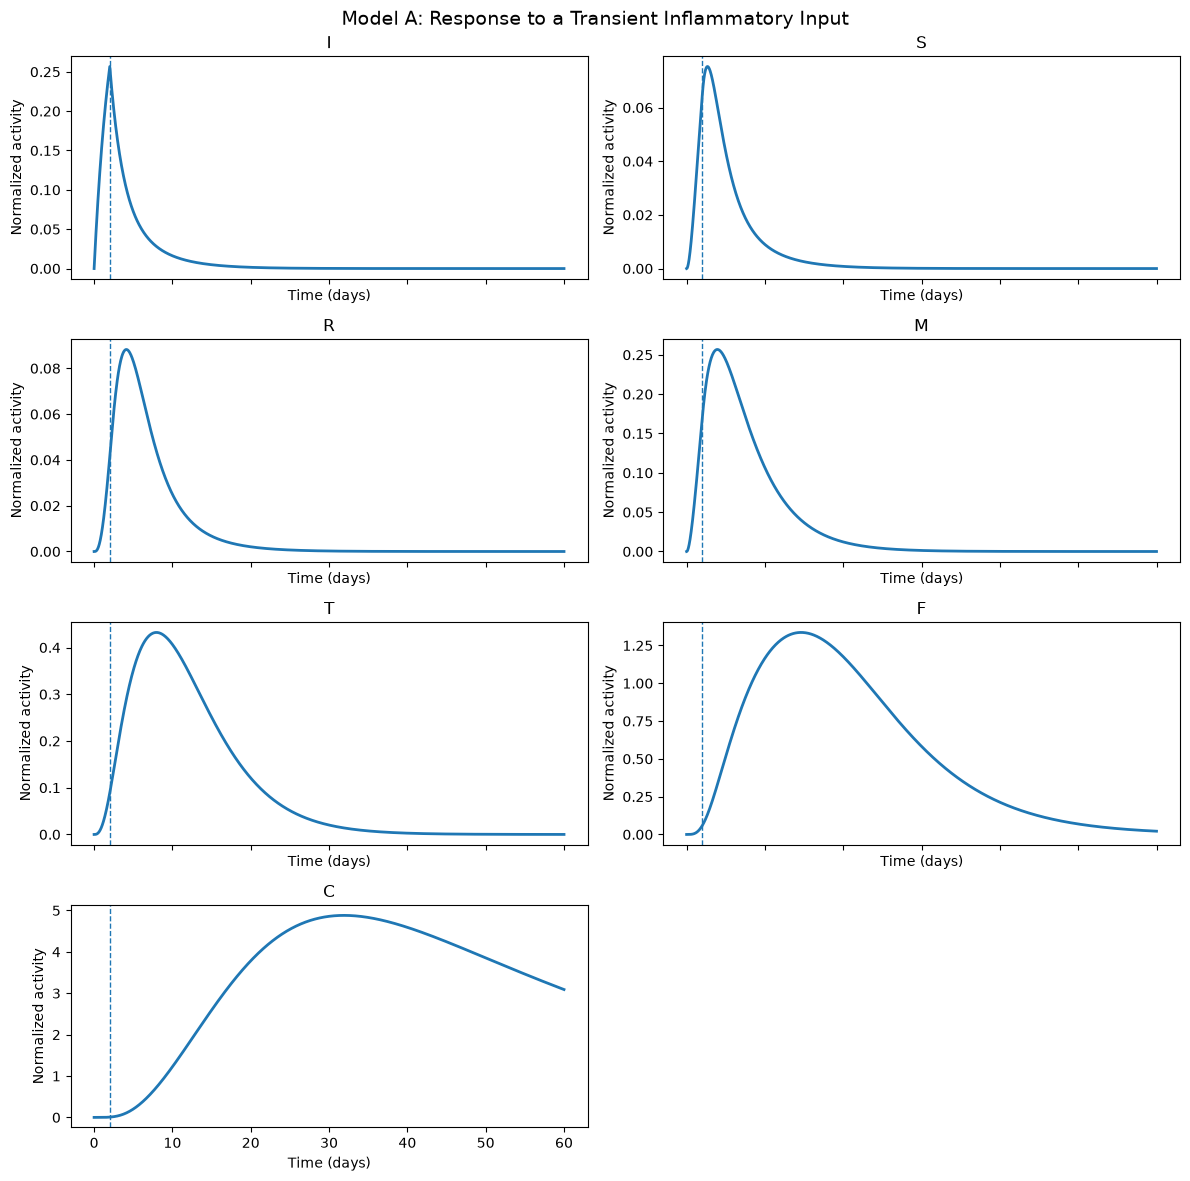

In [ ]:

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 12),
    sharex=True
)

axes = axes.flatten()

for i, state in enumerate(state_names):
    axes[i].plot(
        time,
        states[i],
        linewidth=2
    )

    axes[i].axvline(
        t_pulse_end,
        linestyle="--",
        linewidth=1
    )

    axes[i].set_title(state)
    axes[i].set_ylabel("Normalized activity")
    axes[i].set_xlabel("Time (days)")

axes[-1].axis("off")

fig.suptitle(
    "Model A: Response to a Transient Inflammatory Input",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    RESULTS_DIR / "model_A_transient_pulse.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    RESULTS_DIR / "model_A_transient_pulse.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:

summary = pd.DataFrame({
    "State": state_names,
    "Initial_value": states[:, 0],
    "Peak_value": states.max(axis=1),
    "Time_of_peak_days": time[np.argmax(states, axis=1)],
    "Final_value": states[:, -1]
})

display(summary)

summary.to_csv(
    RESULTS_DIR / "model_A_transient_pulse_summary.csv",
    index=False
)

print("Simulation summary saved.")

,State,Initial_value,Peak_value,Time_of_peak_days,Final_value
0,I,0.0,0.256678,2.00,2.006851e-07
1,S,0.0,0.075306,2.65,1.033982e-07
2,R,0.0,0.088231,4.10,2.604719e-07
3,M,0.0,0.256756,3.95,1.588225e-06
4,T,0.0,0.432290,7.95,4.074906e-05
5,F,0.0,1.336110,14.60,2.144419e-02
6,C,0.0,4.881117,31.90,3.089956e+00


Simulation summary saved.



# Equilibrium and Stability Analysis

This notebook examines the equilibrium structure and local stability of the seven-state nonlinear ODE model of Crohn's disease fibrostenosis.

The analysis focuses on the autonomous system, in which the external inflammatory input is set to zero.

The main objectives are to:

1. Identify the disease-free equilibrium.
2. Derive the feedback threshold associated with the inflammatory subsystem.
3. Calculate the eigenvalues of the Jacobian matrix.
4. assess local stability of the disease-free equilibrium.
5. Determine whether a positive equilibrium can exist under the current parameter values.

The parameter values are exploratory assumptions at this stage. The results therefore describe the mathematical properties of the current model configuration, rather than validated clinical behavior.


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

model_a_file = RESULTS_DIR / "model_A_parameters.csv"
master_file = RESULTS_DIR / "parameter_master_table.csv"

if model_a_file.exists():
    parameter_table = pd.read_csv(model_a_file)
elif master_file.exists():
    master_table = pd.read_csv(master_file)
    parameter_table = master_table.loc[
        master_table["Model"] == "Core"
    ].copy()
else:
    raise FileNotFoundError(
        "Model A parameter file was not found in results/."
    )

if "Baseline" in parameter_table.columns:
    value_column = "Baseline"
elif "Numerical_value" in parameter_table.columns:
    value_column = "Numerical_value"
else:
    raise ValueError(
        "No Baseline or Numerical_value column was found."
    )

parameter_table = parameter_table.drop_duplicates(
    subset="Symbol"
).copy()

parameter_table[value_column] = pd.to_numeric(
    parameter_table[value_column],
    errors="raise"
)

p = parameter_table.set_index("Symbol")[value_column].to_dict()

required = [
    "beta_R", "beta_M", "delta_I",
    "p_S", "delta_S",
    "alpha_R", "K_S", "delta_R",
    "alpha_M", "K_I", "delta_M",
    "alpha_T", "K_M", "delta_T",
    "alpha_FR", "K_FR",
    "alpha_FT", "K_FT", "delta_F",
    "p_C", "delta_C"
]

missing = [name for name in required if name not in p]

if missing:
    raise ValueError(f"Missing parameters: {missing}")

if not all(np.isfinite(p[name]) and p[name] > 0 for name in required):
    raise ValueError("All Model A parameters must be finite and positive.")

print(f"Loaded {len(required)} required Model A parameters.")
print("Parameter source:", model_a_file if model_a_file.exists() else master_file)


Loaded 21 required Model A parameters.
Parameter source: results/model_A_parameters.csv


In [ ]:

def model_A_autonomous(t, y, p):
    I, S, R, M, T, F, C = y

    dI = (
        p["beta_R"] * R
        + p["beta_M"] * M
        - p["delta_I"] * I
    )

    dS = p["p_S"] * I - p["delta_S"] * S

    dR = (
        p["alpha_R"] * S / (p["K_S"] + S)
        - p["delta_R"] * R
    )

    dM = (
        p["alpha_M"] * I / (p["K_I"] + I)
        - p["delta_M"] * M
    )

    dT = (
        p["alpha_T"] * M / (p["K_M"] + M)
        - p["delta_T"] * T
    )

    dF = (
        p["alpha_FR"] * R / (p["K_FR"] + R)
        + p["alpha_FT"] * T / (p["K_FT"] + T)
        - p["delta_F"] * F
    )

    dC = p["p_C"] * F - p["delta_C"] * C

    return np.array([dI, dS, dR, dM, dT, dF, dC], dtype=float)


state_names = ["I", "S", "R", "M", "T", "F", "C"]

zero_state = np.zeros(7, dtype=float)

zero_derivative = model_A_autonomous(
    0.0, zero_state, p
)

print("ODE evaluated at the zero state:")
print(pd.Series(zero_derivative, index=state_names))


ODE evaluated at the zero state:
I    0.0
S    0.0
R    0.0
M    0.0
T    0.0
F    0.0
C    0.0
dtype: float64


In [ ]:

dfe = np.zeros(7, dtype=float)

dfe_check = model_A_autonomous(0.0, dfe, p)

dfe_table = pd.DataFrame({
    "State": state_names,
    "DFE_value": dfe,
    "Derivative_at_DFE": dfe_check
})

display(dfe_table)

if not np.allclose(dfe_check, 0.0, atol=1e-12):
    raise ValueError("The zero state is not an equilibrium.")

print("Disease-free equilibrium verified.")


,State,DFE_value,Derivative_at_DFE
0,I,0.0,0.0
1,S,0.0,0.0
2,R,0.0,0.0
3,M,0.0,0.0
4,T,0.0,0.0
5,F,0.0,0.0
6,C,0.0,0.0


Disease-free equilibrium verified.


In [ ]:

feedback_R = (
    p["beta_R"] * p["alpha_R"] * p["p_S"]
    / (
        p["delta_I"] * p["delta_R"]
        * p["delta_S"] * p["K_S"]
    )
)

feedback_M = (
    p["beta_M"] * p["alpha_M"]
    / (
        p["delta_I"] * p["delta_M"] * p["K_I"]
    )
)

R_feedback = feedback_R + feedback_M

threshold_table = pd.DataFrame({
    "Feedback_pathway": [
        "Inflammation-succinate-SUCNR1 feedback",
        "Inflammation-monocyte feedback",
        "Total inflammatory feedback"
    ],
    "Contribution": [
        feedback_R,
        feedback_M,
        R_feedback
    ]
})

display(threshold_table)

print(f"Inflammatory feedback threshold = {R_feedback:.8f}")


,Feedback_pathway,Contribution
0,Inflammation-succinate-SUCNR1 feedback,0.041143
1,Inflammation-monocyte feedback,0.171429
2,Total inflammatory feedback,0.212571


Inflammatory feedback threshold = 0.21257143


In [ ]:

if R_feedback < 1.0:
    threshold_interpretation = (
        "The linearized inflammatory feedback is below the threshold."
    )
elif R_feedback > 1.0:
    threshold_interpretation = (
        "The linearized inflammatory feedback is above the threshold."
    )
else:
    threshold_interpretation = (
        "The system is at the threshold; nonlinear analysis is required."
    )

print(threshold_interpretation)
print(
    "This threshold is a model-derived feedback quantity, "
    "not an epidemiological reproduction number."
)


The linearized inflammatory feedback is below the threshold.
This threshold is a model-derived feedback quantity, not an epidemiological reproduction number.


In [ ]:

J_dfe = np.zeros((7, 7), dtype=float)

# dI/dt
J_dfe[0, 0] = -p["delta_I"]
J_dfe[0, 2] = p["beta_R"]
J_dfe[0, 3] = p["beta_M"]

# dS/dt
J_dfe[1, 0] = p["p_S"]
J_dfe[1, 1] = -p["delta_S"]

# dR/dt
J_dfe[2, 1] = p["alpha_R"] / p["K_S"]
J_dfe[2, 2] = -p["delta_R"]

# dM/dt
J_dfe[3, 0] = p["alpha_M"] / p["K_I"]
J_dfe[3, 3] = -p["delta_M"]

# dT/dt
J_dfe[4, 3] = p["alpha_T"] / p["K_M"]
J_dfe[4, 4] = -p["delta_T"]

# dF/dt
J_dfe[5, 2] = p["alpha_FR"] / p["K_FR"]
J_dfe[5, 4] = p["alpha_FT"] / p["K_FT"]
J_dfe[5, 5] = -p["delta_F"]

# dC/dt
J_dfe[6, 5] = p["p_C"]
J_dfe[6, 6] = -p["delta_C"]

jacobian_table = pd.DataFrame(
    J_dfe,
    index=state_names,
    columns=state_names
)

display(jacobian_table)


,I,S,R,M,T,F,C
I,-0.5,0.0,0.03,0.03,0.00,0.00,0.000
S,0.4,-1.0,0.00,0.00,0.00,0.00,0.000
R,0.0,1.2,-0.70,0.00,0.00,0.00,0.000
M,1.0,0.0,0.00,-0.35,0.00,0.00,0.000
T,0.0,0.0,0.00,0.90,-0.25,0.00,0.000
F,0.0,0.0,0.70,0.00,0.90,-0.12,0.000
C,0.0,0.0,0.00,0.00,0.00,0.25,-0.025


In [ ]:

eigenvalues = np.linalg.eigvals(J_dfe)

eigenvalue_table = pd.DataFrame({
    "Eigenvalue_real": eigenvalues.real,
    "Eigenvalue_imaginary": eigenvalues.imag,
    "Real_part_negative": eigenvalues.real < 0
})

display(
    eigenvalue_table.sort_values(
        "Eigenvalue_real",
        ascending=False
    ).reset_index(drop=True)
)

maximum_real_part = np.max(eigenvalues.real)

if maximum_real_part < -1e-9:
    stability_result = "Locally asymptotically stable"
elif maximum_real_part > 1e-9:
    stability_result = "Unstable"
else:
    stability_result = "Non-hyperbolic or near the stability boundary"

print("Maximum eigenvalue real part:", maximum_real_part)
print("DFE stability:", stability_result)


,Eigenvalue_real,Eigenvalue_imaginary,Real_part_negative
0,-0.025000,0.000000,True
1,-0.120000,0.000000,True
2,-0.223642,0.000000,True
3,-0.250000,0.000000,True
4,-0.516917,0.000000,True
5,-0.904721,0.126011,True
6,-0.904721,-0.126011,True


Maximum eigenvalue real part: -0.025
DFE stability: Locally asymptotically stable


In [ ]:

feedback_eigenvalues = np.linalg.eigvals(J_dfe[:4, :4])

feedback_max_real = np.max(feedback_eigenvalues.real)

consistency_table = pd.DataFrame({
    "Quantity": [
        "Inflammatory feedback threshold",
        "Maximum real part: 4-state feedback block",
        "Maximum real part: full 7-state Jacobian"
    ],
    "Value": [
        R_feedback,
        feedback_max_real,
        maximum_real_part
    ]
})

display(consistency_table)

if R_feedback < 1 and feedback_max_real >= 0:
    print(
        "WARNING: threshold and eigenvalue results require investigation."
    )
elif R_feedback > 1 and feedback_max_real <= 0:
    print(
        "WARNING: threshold and eigenvalue results require investigation."
    )
else:
    print("Threshold and Jacobian results are consistent.")


,Quantity,Value
0,Inflammatory feedback threshold,0.212571
1,Maximum real part: 4-state feedback block,-0.223642
2,Maximum real part: full 7-state Jacobian,-0.025000


Threshold and Jacobian results are consistent.


In [ ]:

from scipy.optimize import brentq

def equilibrium_states_from_I(I_value, p):
    S = (p["p_S"] / p["delta_S"]) * I_value

    R = (
        p["alpha_R"] / p["delta_R"]
        * S / (p["K_S"] + S)
    )

    M = (
        p["alpha_M"] / p["delta_M"]
        * I_value / (p["K_I"] + I_value)
    )

    T = (
        p["alpha_T"] / p["delta_T"]
        * M / (p["K_M"] + M)
    )

    F = (
        p["alpha_FR"] * R / (p["K_FR"] + R)
        + p["alpha_FT"] * T / (p["K_FT"] + T)
    ) / p["delta_F"]

    C = (p["p_C"] / p["delta_C"]) * F

    return np.array([I_value, S, R, M, T, F, C])


def equilibrium_residual(I_value, p):
    states = equilibrium_states_from_I(I_value, p)
    I, S, R, M, T, F, C = states

    return (
        p["beta_R"] * R
        + p["beta_M"] * M
        - p["delta_I"] * I
    )


positive_equilibrium = None

if R_feedback <= 1.0:
    print(
        "No positive equilibrium is predicted for u = 0 "
        "under the current parameter values."
    )
else:
    upper_bound = 1.0

    while equilibrium_residual(upper_bound, p) > 0:
        upper_bound *= 2.0

        if upper_bound > 1e12:
            raise RuntimeError(
                "Could not bracket the positive equilibrium."
            )

    I_star = brentq(
        lambda value: equilibrium_residual(value, p),
        1e-12,
        upper_bound
    )

    positive_equilibrium = equilibrium_states_from_I(I_star, p)

    display(pd.DataFrame({
        "State": state_names,
        "Positive_equilibrium": positive_equilibrium
    }))

    print("Positive equilibrium found.")


No positive equilibrium is predicted for u = 0 under the current parameter values.


In [ ]:

equilibrium_summary = pd.DataFrame({
    "Metric": [
        "Inflammatory feedback threshold",
        "Maximum real eigenvalue part",
        "DFE stability",
        "Positive equilibrium exists"
    ],
    "Result": [
        R_feedback,
        maximum_real_part,
        stability_result,
        positive_equilibrium is not None
    ]
})

display(equilibrium_summary)

equilibrium_summary.to_csv(
    RESULTS_DIR / "model_A_equilibrium_stability_summary.csv",
    index=False
)

eigenvalue_table.to_csv(
    RESULTS_DIR / "model_A_dfe_eigenvalues.csv",
    index=False
)

jacobian_table.to_csv(
    RESULTS_DIR / "model_A_dfe_jacobian.csv"
)

if positive_equilibrium is not None:
    pd.DataFrame({
        "State": state_names,
        "Equilibrium_value": positive_equilibrium
    }).to_csv(
        RESULTS_DIR / "model_A_positive_equilibrium.csv",
        index=False
    )

print("Equilibrium and stability results saved.")


,Metric,Result
0,Inflammatory feedback threshold,0.212571
1,Maximum real eigenvalue part,-0.025
2,DFE stability,Locally asymptotically stable
3,Positive equilibrium exists,False


Equilibrium and stability results saved.



# Sensitivity Analysis

This notebook examines how changes in the parameters of the seven-state Crohn's disease fibrostenosis model affect extracellular matrix (ECM) dynamics.

A one-at-a-time sensitivity analysis is performed. Each core parameter is varied individually while the remaining parameters are held at their baseline values.

The main outcome measures are:

- Maximum ECM accumulation.
- Final ECM accumulation.
- Area under the ECM trajectory.
- Time at which maximum ECM accumulation occurs.

The analysis is exploratory. Parameter ranges are taken from the current parameter table and are not interpreted as experimentally established confidence intervals.

The results will help identify parameters that deserve priority during literature-based parameter estimation and subsequent uncertainty analysis.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.integrate import solve_ivp

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

parameter_file = RESULTS_DIR / "parameter_master_table.csv"

if not parameter_file.exists():
    raise FileNotFoundError(
        "parameter_master_table.csv was not found in results/."
    )

parameter_table = pd.read_csv(parameter_file)

required_columns = {
    "Symbol", "Baseline", "Lower", "Upper", "Model"
}

missing_columns = required_columns.difference(
    parameter_table.columns
)

if missing_columns:
    raise ValueError(
        f"Missing columns in parameter table: {sorted(missing_columns)}"
    )

parameter_table = parameter_table.loc[
    parameter_table["Model"] == "Core"
].copy()

parameter_table = parameter_table.drop_duplicates(
    subset="Symbol"
).copy()

for column in ["Baseline", "Lower", "Upper"]:
    parameter_table[column] = pd.to_numeric(
        parameter_table[column],
        errors="raise"
    )

print("Core parameter records:", len(parameter_table))
display(parameter_table)


Core parameter records: 21


,Symbol,Baseline,Lower,Upper,Unit,Model,Process,Rationale,Evidence,Source,Source_DOI,Source_URL,Value_type
0,beta_R,0.030,0.000,0.20,day^-1,Core,SUCNR1-associated inflammatory contribution,Represents an aggregate contribution of SUCNR1-associated signaling to inflammatory activity. Th...,Mechanism supported; coefficient assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
1,beta_M,0.030,0.000,0.20,day^-1,Core,Monocyte-associated inflammatory contribution,Represents the aggregate inflammatory contribution of CD150+ monocyte activity. Ke et al. (2024)...,Mechanism supported; coefficient assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption
2,delta_I,0.500,0.200,1.00,day^-1,Core,Inflammatory activity relaxation,Represents first-order relaxation of normalized inflammatory activity. The selected value gives ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
3,p_S,0.400,0.150,0.80,day^-1,Core,Inflammation-associated succinate production,Represents effective succinate production associated with inflammatory activity. The biological ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
4,delta_S,1.000,0.300,2.00,day^-1,Core,Extracellular succinate clearance,Represents effective first-order removal of extracellular succinate. The baseline implies a math...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
5,alpha_R,0.600,0.200,1.20,day^-1,Core,SUCNR1 signaling activation capacity,Represents the maximum normalized activation input of the succinate-SUCNR1 signaling state. The ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
6,K_S,0.500,0.100,5.00,dimensionless,Core,Succinate response saturation scale,Succinate is normalized using a reference concentration of 1 mM. Macias-Ceja et al. (2019) teste...,Experimental dose range informs exploration; K assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
7,delta_R,0.700,0.200,1.50,day^-1,Core,SUCNR1 signaling relaxation,Represents effective first-order relaxation of normalized SUCNR1 signaling. The value implies a ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
8,alpha_M,0.500,0.200,1.00,day^-1,Core,Inflammation-associated monocyte activation,Represents the maximum normalized activation input to the monocyte activity state. The involveme...,Mechanism supported; rate assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption
9,K_I,0.500,0.100,2.00,dimensionless,Core,Inflammatory response saturation scale,Controls saturation of monocyte activation in response to normalized inflammatory activity. A ma...,Assumed; no direct dose-response estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption


In [ ]:

required_parameters = [
    "beta_R", "beta_M", "delta_I",
    "p_S", "delta_S",
    "alpha_R", "K_S", "delta_R",
    "alpha_M", "K_I", "delta_M",
    "alpha_T", "K_M", "delta_T",
    "alpha_FR", "K_FR",
    "alpha_FT", "K_FT", "delta_F",
    "p_C", "delta_C"
]

indexed_parameters = parameter_table.set_index("Symbol")

missing_parameters = [
    name for name in required_parameters
    if name not in indexed_parameters.index
]

if missing_parameters:
    raise ValueError(
        f"Missing core parameters: {missing_parameters}"
    )

parameter_table = indexed_parameters.loc[
    required_parameters
].reset_index()

invalid_rows = parameter_table.loc[
    (~np.isfinite(parameter_table["Baseline"]))
    | (~np.isfinite(parameter_table["Lower"]))
    | (~np.isfinite(parameter_table["Upper"]))
    | (parameter_table["Baseline"] <= 0)
    | (parameter_table["Lower"] < 0)
    | (parameter_table["Upper"] <= parameter_table["Lower"])
    | (parameter_table["Baseline"] < parameter_table["Lower"])
    | (parameter_table["Baseline"] > parameter_table["Upper"])
]

if not invalid_rows.empty:
    display(invalid_rows)
    raise ValueError(
        "Invalid baseline values or parameter bounds detected."
    )

if len(parameter_table) != 21:
    raise ValueError(
        f"Expected 21 core parameters, found {len(parameter_table)}."
    )

print("All 21 core parameters passed validation.")


All 21 core parameters passed validation.


In [ ]:

def saturation(x, K):
    return x / (K + x)


def model_A_rhs(t, y, p, input_amplitude=0.0, input_duration=0.0):
    I, S, R, M, T, F, C = y

    u = input_amplitude if t < input_duration else 0.0

    dI = (
        u
        + p["beta_R"] * R
        + p["beta_M"] * M
        - p["delta_I"] * I
    )

    dS = p["p_S"] * I - p["delta_S"] * S

    dR = (
        p["alpha_R"] * saturation(S, p["K_S"])
        - p["delta_R"] * R
    )

    dM = (
        p["alpha_M"] * saturation(I, p["K_I"])
        - p["delta_M"] * M
    )

    dT = (
        p["alpha_T"] * saturation(M, p["K_M"])
        - p["delta_T"] * T
    )

    dF = (
        p["alpha_FR"] * saturation(R, p["K_FR"])
        + p["alpha_FT"] * saturation(T, p["K_FT"])
        - p["delta_F"] * F
    )

    dC = p["p_C"] * F - p["delta_C"] * C

    return np.array([dI, dS, dR, dM, dT, dF, dC])


def simulate_model_A(p):
    """Simulate Model A under the fixed transient-pulse scenario."""

    y0 = np.zeros(7, dtype=float)

    start_day = 0.0
    pulse_end_day = 2.0
    end_day = 60.0

    input_amplitude = 0.2

    t_eval_1 = np.linspace(start_day, pulse_end_day, 101)
    t_eval_2 = np.linspace(pulse_end_day, end_day, 1161)

    sol_1 = solve_ivp(
        fun=lambda t, y: model_A_rhs(
            t, y, p,
            input_amplitude=input_amplitude,
            input_duration=pulse_end_day
        ),
        t_span=(start_day, pulse_end_day),
        y0=y0,
        method="DOP853",
        t_eval=t_eval_1,
        rtol=1e-8,
        atol=1e-10,
        max_step=0.05
    )

    if not sol_1.success:
        raise RuntimeError(sol_1.message)

    sol_2 = solve_ivp(
        fun=lambda t, y: model_A_rhs(
            t, y, p,
            input_amplitude=0.0,
            input_duration=0.0
        ),
        t_span=(pulse_end_day, end_day),
        y0=sol_1.y[:, -1],
        method="DOP853",
        t_eval=t_eval_2,
        rtol=1e-8,
        atol=1e-10,
        max_step=0.05
    )

    if not sol_2.success:
        raise RuntimeError(sol_2.message)

    time = np.concatenate([sol_1.t, sol_2.t[1:]])
    states = np.hstack([sol_1.y, sol_2.y[:, 1:]])

    if not np.isfinite(states).all():
        raise ValueError("Non-finite values detected in simulation.")

    if np.min(states) < -1e-8:
        raise ValueError("Negative state values detected.")

    return time, states


baseline_parameters = {
    row["Symbol"]: float(row["Baseline"])
    for _, row in parameter_table.iterrows()
}

time, baseline_states = simulate_model_A(baseline_parameters)

print("Baseline simulation completed.")
print("Time points:", len(time))
print("State matrix shape:", baseline_states.shape)


Baseline simulation completed.
Time points: 1261
State matrix shape: (7, 1261)


In [ ]:

def calculate_ecm_metrics(time, states):
    ecm = states[6]

    peak_index = int(np.argmax(ecm))

    return {
        "Peak_ECM": float(np.max(ecm)),
        "Final_ECM": float(ecm[-1]),
        "ECM_AUC": float(np.trapezoid(ecm, time)),
        "Time_to_peak_days": float(time[peak_index])
    }


baseline_metrics = calculate_ecm_metrics(
    time,
    baseline_states
)

baseline_metrics_table = pd.DataFrame(
    [
        {
            "Metric": metric,
            "Baseline_value": value
        }
        for metric, value in baseline_metrics.items()
    ]
)

display(baseline_metrics_table)


,Metric,Baseline_value
0,Peak_ECM,4.881117
1,Final_ECM,3.089956
2,ECM_AUC,198.802950
3,Time_to_peak_days,31.900000


In [ ]:

perturbation_fraction = 0.10

sensitivity_records = []

for _, row in parameter_table.iterrows():

    parameter_name = row["Symbol"]
    baseline_value = float(row["Baseline"])
    lower_bound = float(row["Lower"])
    upper_bound = float(row["Upper"])

    lower_value = max(
        lower_bound,
        baseline_value * (1.0 - perturbation_fraction)
    )

    upper_value = min(
        upper_bound,
        baseline_value * (1.0 + perturbation_fraction)
    )

    if upper_value <= lower_value:
        raise ValueError(
            f"Insufficient perturbation range for {parameter_name}."
        )

    parameters_lower = baseline_parameters.copy()
    parameters_upper = baseline_parameters.copy()

    parameters_lower[parameter_name] = lower_value
    parameters_upper[parameter_name] = upper_value

    time_lower, states_lower = simulate_model_A(parameters_lower)
    time_upper, states_upper = simulate_model_A(parameters_upper)

    metrics_lower = calculate_ecm_metrics(
        time_lower, states_lower
    )

    metrics_upper = calculate_ecm_metrics(
        time_upper, states_upper
    )

    record = {
        "Parameter": parameter_name,
        "Baseline": baseline_value,
        "Lower_test": lower_value,
        "Upper_test": upper_value
    }

    for metric_name, baseline_value_metric in baseline_metrics.items():

        lower_result = metrics_lower[metric_name]
        upper_result = metrics_upper[metric_name]

        if abs(baseline_value_metric) > 1e-12:
            normalized_sensitivity = (
                (upper_result - lower_result)
                / (upper_value - lower_value)
                * baseline_value
                / baseline_value_metric
            )
        else:
            normalized_sensitivity = np.nan

        record[f"{metric_name}_lower"] = lower_result
        record[f"{metric_name}_upper"] = upper_result
        record[f"{metric_name}_sensitivity"] = normalized_sensitivity

    sensitivity_records.append(record)

sensitivity_results = pd.DataFrame(sensitivity_records)

print("One-at-a-time analysis completed.")
print("Parameters evaluated:", len(sensitivity_results))

display(sensitivity_results)


One-at-a-time analysis completed.
Parameters evaluated: 21


,Parameter,Baseline,Lower_test,Upper_test,Peak_ECM_lower,Peak_ECM_upper,Peak_ECM_sensitivity,Final_ECM_lower,Final_ECM_upper,Final_ECM_sensitivity,ECM_AUC_lower,ECM_AUC_upper,ECM_AUC_sensitivity,Time_to_peak_days_lower,Time_to_peak_days_upper,Time_to_peak_days_sensitivity
0,beta_R,0.030,0.0270,0.0330,4.862027,4.900347,0.039254,3.073154,3.106943,0.054676,198.037399,199.574179,0.038651,31.85,31.95,0.015674
1,beta_M,0.030,0.0270,0.0330,4.810791,4.953531,0.146216,3.024820,3.158127,0.215711,195.933661,201.759115,0.146513,31.70,32.15,0.070533
2,delta_I,0.500,0.4500,0.5500,5.313754,4.527162,-0.805750,3.449479,2.811732,-1.031969,216.127899,184.614879,-0.792569,32.80,31.25,-0.242947
3,p_S,0.400,0.3600,0.4400,4.822448,4.938741,0.119125,3.051473,3.127973,0.123788,196.297568,201.260755,0.124827,31.90,31.90,0.000000
4,delta_S,1.000,0.9000,1.1000,4.949988,4.824648,-0.128393,3.136921,3.051935,-0.137520,201.681630,196.433600,-0.131991,31.95,31.90,-0.007837
5,alpha_R,0.600,0.5400,0.6600,4.818162,4.943791,0.128689,3.048867,3.131064,0.133006,196.110329,201.480821,0.135071,31.90,31.90,0.000000
6,K_S,0.500,0.4500,0.5500,4.945082,4.827827,-0.120111,3.132170,3.054991,-0.124886,201.531031,196.527375,-0.125845,31.90,31.90,0.000000
7,delta_R,0.700,0.6300,0.7700,4.955821,4.820511,-0.138605,3.141422,3.048859,-0.149780,201.913347,196.269190,-0.141954,31.95,31.90,-0.007837
8,alpha_M,0.500,0.4500,0.5500,4.577530,5.173185,0.610162,2.865824,3.312091,0.722125,186.525307,210.607592,0.605682,31.50,32.30,0.125392
9,K_I,0.500,0.4500,0.5500,5.149865,4.648874,-0.513193,3.299120,2.914676,-0.622086,209.658006,189.418914,-0.509024,32.35,31.55,-0.125392


In [ ]:

ranking_tables = {}

for metric_name in baseline_metrics:

    sensitivity_column = f"{metric_name}_sensitivity"

    ranking = sensitivity_results[
        ["Parameter", sensitivity_column]
    ].copy()

    ranking["Absolute_sensitivity"] = (
        ranking[sensitivity_column].abs()
    )

    ranking = ranking.sort_values(
        "Absolute_sensitivity",
        ascending=False
    ).reset_index(drop=True)

    ranking_tables[metric_name] = ranking

    print(f"\nSensitivity ranking: {metric_name}")
    display(ranking)



Sensitivity ranking: Peak_ECM


,Parameter,Peak_ECM_sensitivity,Absolute_sensitivity
0,p_C,1.000000,1.000000
1,alpha_FT,0.900995,0.900995
2,delta_F,-0.831669,0.831669
3,delta_I,-0.805750,0.805750
4,delta_M,-0.736231,0.736231
5,delta_T,-0.641493,0.641493
6,alpha_M,0.610162,0.610162
7,K_FT,-0.589954,0.589954
8,alpha_T,0.587874,0.587874
9,K_I,-0.513193,0.513193



Sensitivity ranking: Final_ECM


,Parameter,Final_ECM_sensitivity,Absolute_sensitivity
0,delta_F,-1.195133,1.195133
1,delta_I,-1.031969,1.031969
2,delta_M,-1.002353,1.002353
3,p_C,1.000000,1.000000
4,delta_C,-0.920452,0.920452
5,alpha_FT,0.913552,0.913552
6,delta_T,-0.833179,0.833179
7,alpha_M,0.722125,0.722125
8,K_FT,-0.627132,0.627132
9,alpha_T,0.624488,0.624488



Sensitivity ranking: ECM_AUC


,Parameter,ECM_AUC_sensitivity,Absolute_sensitivity
0,p_C,1.000000,1.000000
1,alpha_FT,0.892894,0.892894
2,delta_F,-0.852031,0.852031
3,delta_I,-0.792569,0.792569
4,delta_M,-0.725247,0.725247
5,delta_T,-0.629394,0.629394
6,alpha_M,0.605682,0.605682
7,K_FT,-0.585353,0.585353
8,alpha_T,0.583305,0.583305
9,K_I,-0.509024,0.509024



Sensitivity ranking: Time_to_peak_days


,Parameter,Time_to_peak_days_sensitivity,Absolute_sensitivity
0,delta_M,-0.282132,0.282132
1,delta_F,-0.274295,0.274295
2,delta_I,-0.242947,0.242947
3,delta_C,-0.219436,0.219436
4,delta_T,-0.211599,0.211599
5,K_I,-0.125392,0.125392
6,alpha_M,0.125392,0.125392
7,beta_M,0.070533,0.070533
8,K_M,-0.054859,0.054859
9,alpha_T,0.047022,0.047022


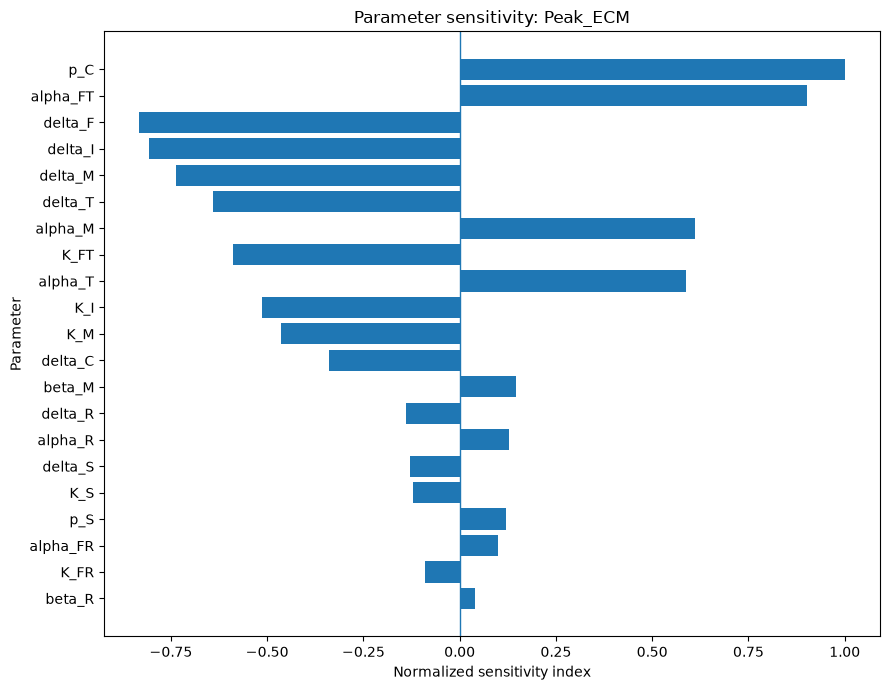

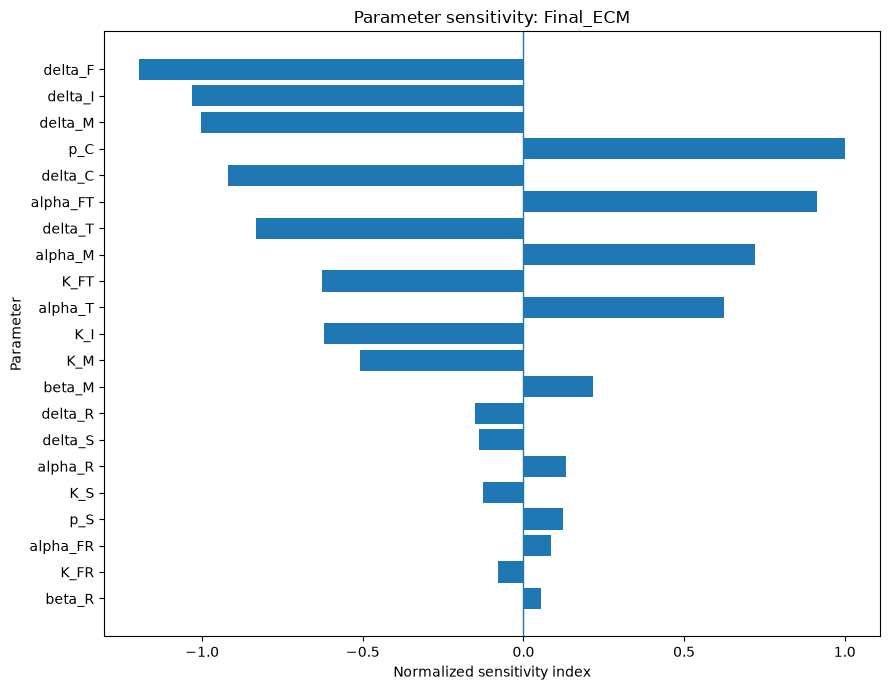

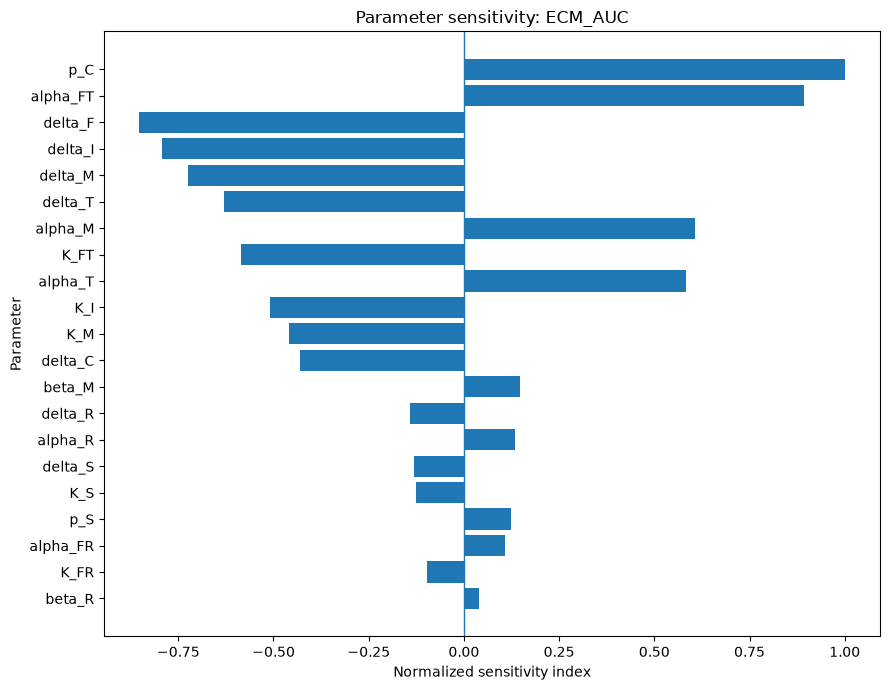

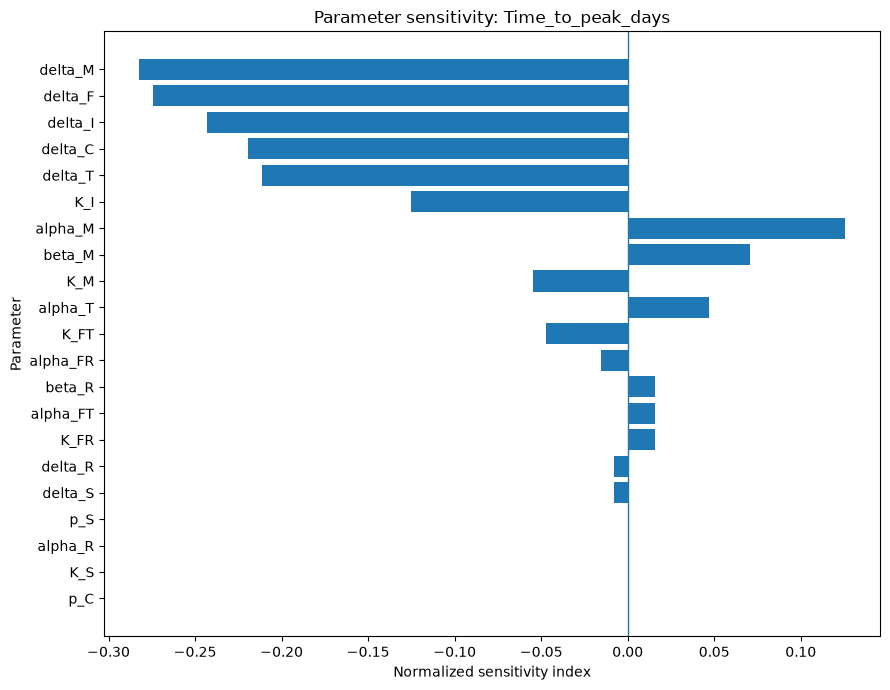

In [ ]:

for metric_name, ranking in ranking_tables.items():

    plot_data = ranking.sort_values(
        "Absolute_sensitivity",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(9, 7))

    ax.barh(
        plot_data["Parameter"],
        plot_data[f"{metric_name}_sensitivity"]
    )

    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Normalized sensitivity index")
    ax.set_ylabel("Parameter")
    ax.set_title(f"Parameter sensitivity: {metric_name}")

    fig.tight_layout()

    safe_name = metric_name.lower()

    fig.savefig(
        RESULTS_DIR / f"sensitivity_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        RESULTS_DIR / f"sensitivity_{safe_name}.pdf",
        bbox_inches="tight"
    )

    plt.show()


In [ ]:

expected_from_notebook_04 = {
    "Peak_ECM": 4.881117,
    "Final_ECM": 3.089956,
    "Time_to_peak_days": 31.90
}

reproducibility_checks = []

for metric_name, expected_value in expected_from_notebook_04.items():

    calculated_value = baseline_metrics[metric_name]

    passed = np.isclose(
        calculated_value,
        expected_value,
        rtol=1e-4,
        atol=1e-6
    )

    reproducibility_checks.append({
        "Metric": metric_name,
        "Notebook_04_value": expected_value,
        "Notebook_06_value": calculated_value,
        "Passed": passed
    })

reproducibility_table = pd.DataFrame(
    reproducibility_checks
)

display(reproducibility_table)

if not reproducibility_table["Passed"].all():
    raise ValueError(
        "Baseline results do not match Notebook 04. "
        "Check equations, parameters, initial conditions, "
        "and numerical settings."
    )

print("Baseline reproducibility check passed.")


,Metric,Notebook_04_value,Notebook_06_value,Passed
0,Peak_ECM,4.881117,4.881117,True
1,Final_ECM,3.089956,3.089956,True
2,Time_to_peak_days,31.900000,31.900000,True


Baseline reproducibility check passed.


In [ ]:

sensitivity_columns = [
    column for column in sensitivity_results.columns
    if column.endswith("_sensitivity")
]

if not np.isfinite(
    sensitivity_results[sensitivity_columns].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Non-finite sensitivity indices detected."
    )

if len(sensitivity_results) != 21:
    raise ValueError(
        "The sensitivity analysis did not evaluate all 21 core parameters."
    )

sensitivity_file = (
    RESULTS_DIR / "model_A_oat_sensitivity_results.csv"
)

baseline_metrics_file = (
    RESULTS_DIR / "model_A_sensitivity_baseline_metrics.csv"
)

sensitivity_results.to_csv(
    sensitivity_file,
    index=False
)

baseline_metrics_table.to_csv(
    baseline_metrics_file,
    index=False
)

for metric_name, ranking in ranking_tables.items():

    ranking.to_csv(
        RESULTS_DIR / f"ranking_{metric_name.lower()}.csv",
        index=False
    )

print("Sensitivity analysis results saved.")
print(sensitivity_file.resolve())
print(baseline_metrics_file.resolve())
print("All 21 parameters were evaluated.")


Sensitivity analysis results saved.
/workspaces/crohns-fibrostenosis-ode-model/results/model_A_oat_sensitivity_results.csv
/workspaces/crohns-fibrostenosis-ode-model/results/model_A_sensitivity_baseline_metrics.csv
All 21 parameters were evaluated.



## Interpretation and limitations

The one-at-a-time sensitivity analysis evaluates how individual parameter changes affect ECM accumulation under the selected transient inflammatory input.

The normalized sensitivity index describes the relative change in an outcome associated with a relative change in one parameter around its baseline value.

A positive index indicates that an increase in the parameter is associated with an increase in the outcome. A negative index indicates an inverse relationship.

The rankings are conditional on the current baseline parameter values, parameter bounds, initial conditions, and input scenario.

The analysis does not account for parameter interactions or correlations. The parameter bounds are exploratory ranges and should not be interpreted as confidence intervals.

The results will be used to prioritize parameters for further literature review, experimental data extraction, and uncertainty analysis.



# Global Parameter Uncertainty Analysis

This notebook examines how uncertainty in the 21 core parameters affects the predicted ECM response of Model A.

Parameter combinations are generated using Latin Hypercube Sampling (LHS). Each parameter is sampled independently within its current lower and upper bounds.

The analysis focuses on four outcomes:

- Peak ECM accumulation.
- Final ECM accumulation at day 60.
- Area under the ECM trajectory.
- Time to peak ECM accumulation.

The parameter ranges are exploratory and are not interpreted as experimentally measured probability distributions or confidence intervals. The resulting output distributions therefore describe the behaviour of the model under the selected sampling assumptions, rather than patient-level clinical uncertainty.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.stats import qmc

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

parameter_file = RESULTS_DIR / "parameter_master_table.csv"

if not parameter_file.exists():
    raise FileNotFoundError(
        f"Parameter file not found: {parameter_file.resolve()}"
    )

parameter_table = pd.read_csv(parameter_file)

required_columns = {
    "Symbol", "Baseline", "Lower", "Upper", "Model"
}

missing_columns = required_columns.difference(
    parameter_table.columns
)

if missing_columns:
    raise ValueError(
        f"Missing columns: {sorted(missing_columns)}"
    )

core_parameters = parameter_table.loc[
    parameter_table["Model"] == "Core"
].copy()

core_parameters = core_parameters.drop_duplicates(
    subset="Symbol"
)

required_symbols = [
    "beta_R", "beta_M", "delta_I",
    "p_S", "delta_S",
    "alpha_R", "K_S", "delta_R",
    "alpha_M", "K_I", "delta_M",
    "alpha_T", "K_M", "delta_T",
    "alpha_FR", "K_FR",
    "alpha_FT", "K_FT", "delta_F",
    "p_C", "delta_C"
]

core_parameters = core_parameters.set_index("Symbol")

missing_symbols = [
    symbol for symbol in required_symbols
    if symbol not in core_parameters.index
]

if missing_symbols:
    raise ValueError(
        f"Missing core parameters: {missing_symbols}"
    )

core_parameters = core_parameters.loc[
    required_symbols
].reset_index()

for column in ["Baseline", "Lower", "Upper"]:
    core_parameters[column] = pd.to_numeric(
        core_parameters[column],
        errors="raise"
    )

if len(core_parameters) != 21:
    raise ValueError(
        f"Expected 21 core parameters; found {len(core_parameters)}."
    )

if not np.isfinite(
    core_parameters[["Baseline", "Lower", "Upper"]].to_numpy()
).all():
    raise ValueError("Non-finite parameter values detected.")

if (
    (core_parameters["Lower"] < 0).any()
    or (core_parameters["Upper"] <= core_parameters["Lower"]).any()
    or (core_parameters["Baseline"] < core_parameters["Lower"]).any()
    or (core_parameters["Baseline"] > core_parameters["Upper"]).any()
):
    raise ValueError("Invalid parameter bounds or baseline values.")

print("Parameter table validation passed.")
print("Number of core parameters:", len(core_parameters))

display(core_parameters)


Parameter table validation passed.
Number of core parameters: 21


,Symbol,Baseline,Lower,Upper,Unit,Model,Process,Rationale,Evidence,Source,Source_DOI,Source_URL,Value_type
0,beta_R,0.030,0.000,0.20,day^-1,Core,SUCNR1-associated inflammatory contribution,Represents an aggregate contribution of SUCNR1-associated signaling to inflammatory activity. Th...,Mechanism supported; coefficient assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
1,beta_M,0.030,0.000,0.20,day^-1,Core,Monocyte-associated inflammatory contribution,Represents the aggregate inflammatory contribution of CD150+ monocyte activity. Ke et al. (2024)...,Mechanism supported; coefficient assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption
2,delta_I,0.500,0.200,1.00,day^-1,Core,Inflammatory activity relaxation,Represents first-order relaxation of normalized inflammatory activity. The selected value gives ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
3,p_S,0.400,0.150,0.80,day^-1,Core,Inflammation-associated succinate production,Represents effective succinate production associated with inflammatory activity. The biological ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
4,delta_S,1.000,0.300,2.00,day^-1,Core,Extracellular succinate clearance,Represents effective first-order removal of extracellular succinate. The baseline implies a math...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
5,alpha_R,0.600,0.200,1.20,day^-1,Core,SUCNR1 signaling activation capacity,Represents the maximum normalized activation input of the succinate-SUCNR1 signaling state. The ...,Mechanism supported; rate assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
6,K_S,0.500,0.100,5.00,dimensionless,Core,Succinate response saturation scale,Succinate is normalized using a reference concentration of 1 mM. Macias-Ceja et al. (2019) teste...,Experimental dose range informs exploration; K assumed,MaciasCeja2019,10.1038/s41385-018-0087-3,https://doi.org/10.1038/s41385-018-0087-3,Exploratory working assumption
7,delta_R,0.700,0.200,1.50,day^-1,Core,SUCNR1 signaling relaxation,Represents effective first-order relaxation of normalized SUCNR1 signaling. The value implies a ...,Assumed; no direct kinetic estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption
8,alpha_M,0.500,0.200,1.00,day^-1,Core,Inflammation-associated monocyte activation,Represents the maximum normalized activation input to the monocyte activity state. The involveme...,Mechanism supported; rate assumed,Ke2024,10.1172/JCI173835,https://doi.org/10.1172/JCI173835,Exploratory working assumption
9,K_I,0.500,0.100,2.00,dimensionless,Core,Inflammatory response saturation scale,Controls saturation of monocyte activation in response to normalized inflammatory activity. A ma...,Assumed; no direct dose-response estimate,No direct quantitative estimate,Not available,Not available,Exploratory working assumption


In [ ]:

def saturation(x, K):
    return x / (K + x)


def model_A_rhs(
    t,
    y,
    p,
    input_amplitude=0.0,
    input_duration=0.0
):
    I, S, R, M, T, F, C = y

    u = input_amplitude if t < input_duration else 0.0

    dI = (
        u
        + p["beta_R"] * R
        + p["beta_M"] * M
        - p["delta_I"] * I
    )

    dS = p["p_S"] * I - p["delta_S"] * S

    dR = (
        p["alpha_R"] * saturation(S, p["K_S"])
        - p["delta_R"] * R
    )

    dM = (
        p["alpha_M"] * saturation(I, p["K_I"])
        - p["delta_M"] * M
    )

    dT = (
        p["alpha_T"] * saturation(M, p["K_M"])
        - p["delta_T"] * T
    )

    dF = (
        p["alpha_FR"] * saturation(R, p["K_FR"])
        + p["alpha_FT"] * saturation(T, p["K_FT"])
        - p["delta_F"] * F
    )

    dC = p["p_C"] * F - p["delta_C"] * C

    return np.array([dI, dS, dR, dM, dT, dF, dC])


def simulate_model_A(p):

    y0 = np.zeros(7, dtype=float)

    start_day = 0.0
    pulse_end_day = 2.0
    end_day = 60.0

    input_amplitude = 0.2

    t_eval_1 = np.linspace(start_day, pulse_end_day, 101)
    t_eval_2 = np.linspace(pulse_end_day, end_day, 1161)

    sol_1 = solve_ivp(
        lambda t, y: model_A_rhs(
            t,
            y,
            p,
            input_amplitude=input_amplitude,
            input_duration=pulse_end_day
        ),
        (start_day, pulse_end_day),
        y0,
        method="DOP853",
        t_eval=t_eval_1,
        rtol=1e-8,
        atol=1e-10,
        max_step=0.05
    )

    if not sol_1.success:
        raise RuntimeError(sol_1.message)

    sol_2 = solve_ivp(
        lambda t, y: model_A_rhs(t, y, p),
        (pulse_end_day, end_day),
        sol_1.y[:, -1],
        method="DOP853",
        t_eval=t_eval_2,
        rtol=1e-8,
        atol=1e-10,
        max_step=0.05
    )

    if not sol_2.success:
        raise RuntimeError(sol_2.message)

    time = np.concatenate([sol_1.t, sol_2.t[1:]])
    states = np.hstack([sol_1.y, sol_2.y[:, 1:]])

    if not np.isfinite(states).all():
        raise ValueError("Non-finite state values detected.")

    if np.min(states) < -1e-8:
        raise ValueError("Negative state values detected.")

    return time, states


def calculate_ecm_metrics(time, states):

    ecm = states[6]
    peak_index = int(np.argmax(ecm))

    return {
        "Peak_ECM": float(np.max(ecm)),
        "Final_ECM": float(ecm[-1]),
        "ECM_AUC": float(np.trapezoid(ecm, time)),
        "Time_to_peak_days": float(time[peak_index])
    }


baseline_parameters = {
    row["Symbol"]: float(row["Baseline"])
    for _, row in core_parameters.iterrows()
}

baseline_time, baseline_states = simulate_model_A(
    baseline_parameters
)

baseline_metrics = calculate_ecm_metrics(
    baseline_time,
    baseline_states
)

print("Baseline simulation completed.")
display(pd.DataFrame(
    list(baseline_metrics.items()),
    columns=["Metric", "Baseline_value"]
))


Baseline simulation completed.


,Metric,Baseline_value
0,Peak_ECM,4.881117
1,Final_ECM,3.089956
2,ECM_AUC,198.802950
3,Time_to_peak_days,31.900000


In [ ]:

expected_baseline = {
    "Peak_ECM": 4.881117,
    "Final_ECM": 3.089956,
    "Time_to_peak_days": 31.90
}

baseline_checks = []

for metric, expected in expected_baseline.items():

    calculated = baseline_metrics[metric]

    baseline_checks.append({
        "Metric": metric,
        "Notebook_04_value": expected,
        "Notebook_07_value": calculated,
        "Passed": np.isclose(
            calculated,
            expected,
            rtol=1e-4,
            atol=1e-6
        )
    })

baseline_check_table = pd.DataFrame(baseline_checks)

display(baseline_check_table)

if not baseline_check_table["Passed"].all():
    raise ValueError(
        "Baseline does not reproduce Notebook 04. "
        "Do not proceed until the discrepancy is resolved."
    )

print("Baseline reproducibility check passed.")


,Metric,Notebook_04_value,Notebook_07_value,Passed
0,Peak_ECM,4.881117,4.881117,True
1,Final_ECM,3.089956,3.089956,True
2,Time_to_peak_days,31.900000,31.900000,True


Baseline reproducibility check passed.


In [ ]:

N_SAMPLES = 200
RANDOM_SEED = 20261110

lower_bounds = core_parameters["Lower"].to_numpy(dtype=float)
upper_bounds = core_parameters["Upper"].to_numpy(dtype=float)

sampler = qmc.LatinHypercube(
    d=len(required_symbols),
    seed=RANDOM_SEED
)

unit_samples = sampler.random(n=N_SAMPLES)

sample_values = qmc.scale(
    unit_samples,
    lower_bounds,
    upper_bounds
)

lhs_samples = pd.DataFrame(
    sample_values,
    columns=required_symbols
)

lhs_samples.insert(
    0,
    "Sample_ID",
    np.arange(1, N_SAMPLES + 1)
)

if lhs_samples.shape[0] != N_SAMPLES:
    raise ValueError("Unexpected number of LHS samples.")

if not np.isfinite(
    lhs_samples[required_symbols].to_numpy()
).all():
    raise ValueError("Non-finite LHS values detected.")

for symbol in required_symbols:

    lower = float(
        core_parameters.loc[
            core_parameters["Symbol"] == symbol,
            "Lower"
        ].iloc[0]
    )

    upper = float(
        core_parameters.loc[
            core_parameters["Symbol"] == symbol,
            "Upper"
        ].iloc[0]
    )

    if (
        (lhs_samples[symbol] < lower).any()
        or (lhs_samples[symbol] > upper).any()
    ):
        raise ValueError(
            f"Sample outside bounds for {symbol}."
        )

print("LHS sampling completed.")
print("Number of samples:", len(lhs_samples))
print("Number of parameters:", len(required_symbols))

display(lhs_samples.head())


LHS sampling completed.
Number of samples: 200
Number of parameters: 21


,Sample_ID,beta_R,beta_M,delta_I,p_S,delta_S,alpha_R,K_S,delta_R,alpha_M,K_I,delta_M,alpha_T,K_M,delta_T,alpha_FR,K_FR,alpha_FT,K_FT,delta_F,p_C,delta_C
0,1,0.072374,0.043858,0.405449,0.603295,1.194983,1.136942,3.826887,1.465823,0.353268,0.924918,0.456241,0.817107,1.246928,0.310344,0.790837,0.770128,0.171677,1.638822,0.286749,0.185259,0.024825
1,2,0.162560,0.121928,0.508714,0.215586,1.707142,0.320878,2.269003,0.394281,0.332129,1.637689,0.572514,0.624424,1.277430,0.290018,0.500985,1.499662,0.718439,1.529593,0.194670,0.247926,0.006087
2,3,0.099929,0.180934,0.622261,0.539974,0.880344,0.431954,0.316670,0.822364,0.668276,0.621018,0.734596,0.817287,1.523803,0.162136,0.258539,0.787123,0.632174,1.264079,0.143981,0.531337,0.067270
3,4,0.079139,0.028744,0.299904,0.445456,1.308871,0.776202,2.132214,1.445264,0.405733,1.455528,0.378913,0.584851,1.780688,0.557640,0.344450,1.530505,0.588367,0.768421,0.159636,0.466886,0.055684
4,5,0.017935,0.168266,0.495544,0.394957,0.723271,0.944350,0.667229,1.126458,0.420616,1.526574,0.550458,0.449571,0.412219,0.317818,0.770329,0.583688,0.160557,0.617486,0.188514,0.543975,0.044709


In [ ]:

simulation_records = []
failure_records = []

for _, sample in lhs_samples.iterrows():

    sample_id = int(sample["Sample_ID"])

    sampled_parameters = {
        symbol: float(sample[symbol])
        for symbol in required_symbols
    }

    try:
        sample_time, sample_states = simulate_model_A(
            sampled_parameters
        )

        metrics = calculate_ecm_metrics(
            sample_time,
            sample_states
        )

        record = {
            "Sample_ID": sample_id,
            **sampled_parameters,
            **metrics
        }

        simulation_records.append(record)

    except Exception as error:

        failure_records.append({
            "Sample_ID": sample_id,
            "Error": str(error)
        })

    if sample_id % 25 == 0:
        print(
            f"Completed {sample_id}/{N_SAMPLES} samples."
        )

simulation_results = pd.DataFrame(simulation_records)
simulation_failures = pd.DataFrame(
    failure_records,
    columns=["Sample_ID", "Error"]
)

print("\nSimulation run finished.")
print("Successful simulations:", len(simulation_results))
print("Failed simulations:", len(simulation_failures))

if not simulation_failures.empty:
    display(simulation_failures)

if len(simulation_results) != N_SAMPLES:
    raise RuntimeError(
        "Not all LHS simulations succeeded. "
        "Inspect simulation_failures before interpreting results."
    )

print("All sampled simulations completed successfully.")


Completed 25/200 samples.
Completed 50/200 samples.
Completed 75/200 samples.
Completed 100/200 samples.
Completed 125/200 samples.
Completed 150/200 samples.
Completed 175/200 samples.
Completed 200/200 samples.

Simulation run finished.
Successful simulations: 200
Failed simulations: 0
All sampled simulations completed successfully.


In [ ]:

outcome_columns = [
    "Peak_ECM",
    "Final_ECM",
    "ECM_AUC",
    "Time_to_peak_days"
]

summary_records = []

for outcome in outcome_columns:

    values = simulation_results[outcome].to_numpy(dtype=float)

    summary_records.append({
        "Outcome": outcome,
        "Minimum": np.min(values),
        "5th_percentile": np.percentile(values, 5),
        "25th_percentile": np.percentile(values, 25),
        "Median": np.median(values),
        "75th_percentile": np.percentile(values, 75),
        "95th_percentile": np.percentile(values, 95),
        "Maximum": np.max(values),
        "Baseline": baseline_metrics[outcome]
    })

uncertainty_summary = pd.DataFrame(summary_records)

display(uncertainty_summary)


,Outcome,Minimum,5th_percentile,25th_percentile,Median,75th_percentile,95th_percentile,Maximum,Baseline
0,Peak_ECM,0.019471,0.120877,0.511368,1.751416,5.985456,23.677121,81.461143,4.881117
1,Final_ECM,0.005954,0.026021,0.218016,0.904922,4.477635,23.677121,80.820069,3.089956
2,ECM_AUC,0.712270,4.157806,19.211788,63.950332,214.243271,618.123659,2882.962113,198.802950
3,Time_to_peak_days,15.200000,17.847500,23.325000,30.325000,47.775000,60.000000,60.000000,31.900000


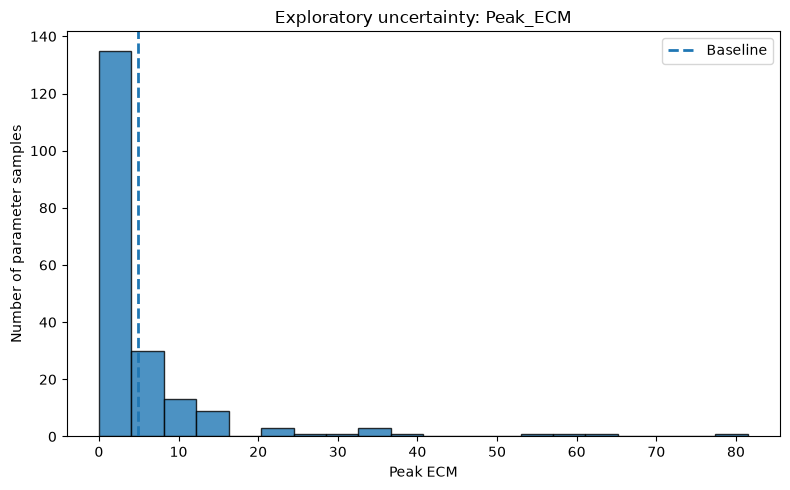

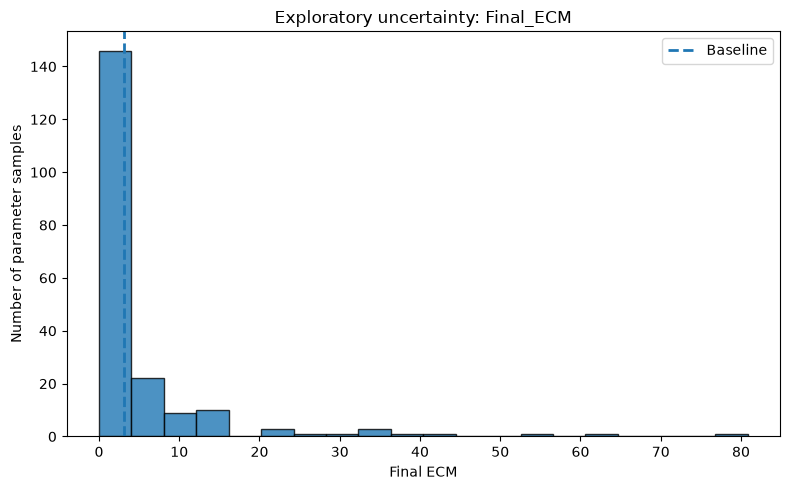

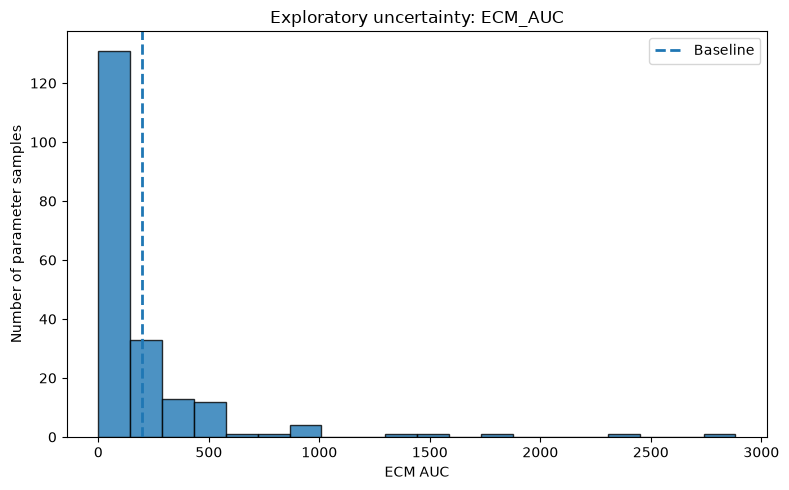

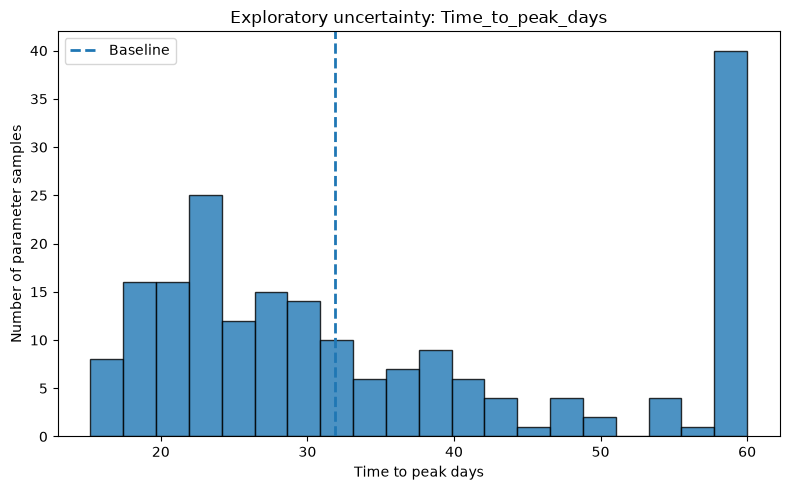

In [ ]:

for outcome in outcome_columns:

    values = simulation_results[outcome].to_numpy(dtype=float)
    baseline_value = baseline_metrics[outcome]

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.hist(
        values,
        bins=20,
        edgecolor="black",
        alpha=0.8
    )

    ax.axvline(
        baseline_value,
        linestyle="--",
        linewidth=2,
        label="Baseline"
    )

    ax.set_xlabel(outcome.replace("_", " "))
    ax.set_ylabel("Number of parameter samples")
    ax.set_title(f"Exploratory uncertainty: {outcome}")
    ax.legend()

    fig.tight_layout()

    fig.savefig(
        RESULTS_DIR / f"uncertainty_{outcome.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        RESULTS_DIR / f"uncertainty_{outcome.lower()}.pdf",
        bbox_inches="tight"
    )

    plt.show()


In [ ]:

comparison_records = []

for outcome in outcome_columns:

    values = simulation_results[outcome].to_numpy(dtype=float)
    baseline_value = baseline_metrics[outcome]

    lower_5 = np.percentile(values, 5)
    upper_95 = np.percentile(values, 95)

    comparison_records.append({
        "Outcome": outcome,
        "Baseline": baseline_value,
        "Sample_median": np.median(values),
        "Sample_5th_percentile": lower_5,
        "Sample_95th_percentile": upper_95,
        "Baseline_inside_5th_95th_range": (
            lower_5 <= baseline_value <= upper_95
        )
    })

baseline_comparison = pd.DataFrame(comparison_records)

display(baseline_comparison)


,Outcome,Baseline,Sample_median,Sample_5th_percentile,Sample_95th_percentile,Baseline_inside_5th_95th_range
0,Peak_ECM,4.881117,1.751416,0.120877,23.677121,True
1,Final_ECM,3.089956,0.904922,0.026021,23.677121,True
2,ECM_AUC,198.802950,63.950332,4.157806,618.123659,True
3,Time_to_peak_days,31.900000,30.325000,17.847500,60.000000,True


In [ ]:

spearman_records = []

for outcome in outcome_columns:

    for parameter in required_symbols:

        correlation = simulation_results[
            [parameter, outcome]
        ].corr(method="spearman").iloc[0, 1]

        spearman_records.append({
            "Parameter": parameter,
            "Outcome": outcome,
            "Spearman_rho": correlation,
            "Absolute_rho": abs(correlation)
        })

spearman_results = pd.DataFrame(spearman_records)

for outcome in outcome_columns:

    ranking = spearman_results.loc[
        spearman_results["Outcome"] == outcome
    ].sort_values(
        "Absolute_rho",
        ascending=False
    ).reset_index(drop=True)

    print(f"\nExploratory Spearman ranking: {outcome}")
    display(ranking)



Exploratory Spearman ranking: Peak_ECM


,Parameter,Outcome,Spearman_rho,Absolute_rho
0,p_C,Peak_ECM,0.403822,0.403822
1,delta_F,Peak_ECM,-0.387430,0.387430
2,K_I,Peak_ECM,-0.345430,0.345430
3,K_FT,Peak_ECM,-0.309672,0.309672
4,delta_M,Peak_ECM,-0.308027,0.308027
5,alpha_T,Peak_ECM,0.271027,0.271027
6,beta_M,Peak_ECM,0.227871,0.227871
7,alpha_FR,Peak_ECM,0.226071,0.226071
8,delta_I,Peak_ECM,-0.205879,0.205879
9,delta_T,Peak_ECM,-0.164956,0.164956



Exploratory Spearman ranking: Final_ECM


,Parameter,Outcome,Spearman_rho,Absolute_rho
0,delta_F,Final_ECM,-0.389392,0.389392
1,K_I,Final_ECM,-0.352117,0.352117
2,delta_M,Final_ECM,-0.339266,0.339266
3,p_C,Final_ECM,0.337777,0.337777
4,delta_C,Final_ECM,-0.248573,0.248573
5,K_FT,Final_ECM,-0.245240,0.245240
6,beta_M,Final_ECM,0.227713,0.227713
7,delta_I,Final_ECM,-0.223081,0.223081
8,alpha_T,Final_ECM,0.204869,0.204869
9,alpha_FR,Final_ECM,0.203761,0.203761



Exploratory Spearman ranking: ECM_AUC


,Parameter,Outcome,Spearman_rho,Absolute_rho
0,p_C,ECM_AUC,0.407151,0.407151
1,delta_F,ECM_AUC,-0.388690,0.388690
2,K_I,ECM_AUC,-0.348648,0.348648
3,K_FT,ECM_AUC,-0.303893,0.303893
4,delta_M,ECM_AUC,-0.300954,0.300954
5,alpha_T,ECM_AUC,0.268928,0.268928
6,beta_M,ECM_AUC,0.224182,0.224182
7,alpha_FR,ECM_AUC,0.222120,0.222120
8,delta_I,ECM_AUC,-0.193527,0.193527
9,delta_T,ECM_AUC,-0.177532,0.177532



Exploratory Spearman ranking: Time_to_peak_days


,Parameter,Outcome,Spearman_rho,Absolute_rho
0,delta_M,Time_to_peak_days,-0.406297,0.406297
1,delta_F,Time_to_peak_days,-0.380816,0.380816
2,K_I,Time_to_peak_days,-0.312092,0.312092
3,delta_I,Time_to_peak_days,-0.277467,0.277467
4,delta_T,Time_to_peak_days,-0.248156,0.248156
5,beta_M,Time_to_peak_days,0.244162,0.244162
6,delta_C,Time_to_peak_days,-0.243909,0.243909
7,alpha_FR,Time_to_peak_days,0.129703,0.129703
8,K_FT,Time_to_peak_days,-0.109087,0.109087
9,delta_S,Time_to_peak_days,-0.086225,0.086225


In [ ]:

if len(simulation_results) != N_SAMPLES:
    raise ValueError("Incorrect number of simulation results.")

if not simulation_failures.empty:
    raise ValueError(
        "At least one simulation failed. Results are not ready for interpretation."
    )

if not np.isfinite(
    simulation_results[outcome_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Non-finite outcome values detected.")

if (
    simulation_results[outcome_columns] < -1e-8
).any().any():
    raise ValueError("Negative outcome values detected.")

if len(spearman_results) != len(required_symbols) * len(outcome_columns):
    raise ValueError("Incomplete parameter-outcome correlation analysis.")

lhs_samples.to_csv(
    RESULTS_DIR / "model_A_lhs_parameter_samples.csv",
    index=False
)

simulation_results.to_csv(
    RESULTS_DIR / "model_A_lhs_simulation_results.csv",
    index=False
)

simulation_failures.to_csv(
    RESULTS_DIR / "model_A_lhs_simulation_failures.csv",
    index=False
)

uncertainty_summary.to_csv(
    RESULTS_DIR / "model_A_uncertainty_summary.csv",
    index=False
)

baseline_comparison.to_csv(
    RESULTS_DIR / "model_A_baseline_uncertainty_comparison.csv",
    index=False
)

spearman_results.to_csv(
    RESULTS_DIR / "model_A_spearman_parameter_outcome.csv",
    index=False
)

print("All validation checks passed.")
print("Successful LHS simulations:", len(simulation_results))
print("Failed simulations:", len(simulation_failures))
print("Core parameters:", len(required_symbols))
print("\nSaved files:")

for filename in [
    "model_A_lhs_parameter_samples.csv",
    "model_A_lhs_simulation_results.csv",
    "model_A_lhs_simulation_failures.csv",
    "model_A_uncertainty_summary.csv",
    "model_A_baseline_uncertainty_comparison.csv",
    "model_A_spearman_parameter_outcome.csv"
]:
    print("-", (RESULTS_DIR / filename).resolve())


All validation checks passed.
Successful LHS simulations: 200
Failed simulations: 0
Core parameters: 21

Saved files:
- /workspaces/crohns-fibrostenosis-ode-model/results/model_A_lhs_parameter_samples.csv
- /workspaces/crohns-fibrostenosis-ode-model/results/model_A_lhs_simulation_results.csv
- /workspaces/crohns-fibrostenosis-ode-model/results/model_A_lhs_simulation_failures.csv
- /workspaces/crohns-fibrostenosis-ode-model/results/model_A_uncertainty_summary.csv
- /workspaces/crohns-fibrostenosis-ode-model/results/model_A_baseline_uncertainty_comparison.csv
- /workspaces/crohns-fibrostenosis-ode-model/results/model_A_spearman_parameter_outcome.csv



## Interpretation and limitations

Latin Hypercube Sampling was used to explore the response of Model A to simultaneous variation in its 21 core parameters.

The resulting distributions describe the range of model outcomes under the selected parameter bounds and independent uniform sampling design.

These distributions should not be interpreted as clinical prediction intervals, confidence intervals, or empirical probability distributions of biological parameters.

The analysis assumes independent parameter sampling. Potential correlations between biological parameters have not been incorporated.

The Spearman correlations provide exploratory information about parameter–outcome associations. They do not establish causal effects and do not replace variance-based global sensitivity methods such as Sobol analysis.

The results should be interpreted in conjunction with the one-at-a-time sensitivity analysis and the available experimental evidence. Parameters with substantial influence on ECM outcomes should receive priority during further literature review and quantitative data extraction.


In [ ]:

EXTENDED_END_DAY = 180.0

def simulate_model_A_extended(p, end_day=180.0):

    y0 = np.zeros(7, dtype=float)

    pulse_end_day = 2.0
    input_amplitude = 0.2

    t_eval_1 = np.linspace(0.0, pulse_end_day, 101)
    t_eval_2 = np.linspace(
        pulse_end_day,
        end_day,
        int((end_day - pulse_end_day) * 20) + 1
    )

    sol_1 = solve_ivp(
        lambda t, y: model_A_rhs(
            t, y, p,
            input_amplitude=input_amplitude,
            input_duration=pulse_end_day
        ),
        (0.0, pulse_end_day),
        y0,
        method="DOP853",
        t_eval=t_eval_1,
        rtol=1e-8,
        atol=1e-10,
        max_step=0.05
    )

    if not sol_1.success:
        raise RuntimeError(sol_1.message)

    sol_2 = solve_ivp(
        lambda t, y: model_A_rhs(t, y, p),
        (pulse_end_day, end_day),
        sol_1.y[:, -1],
        method="DOP853",
        t_eval=t_eval_2,
        rtol=1e-8,
        atol=1e-10,
        max_step=0.05
    )

    if not sol_2.success:
        raise RuntimeError(sol_2.message)

    time = np.concatenate([sol_1.t, sol_2.t[1:]])
    states = np.hstack([sol_1.y, sol_2.y[:, 1:]])

    if not np.isfinite(states).all():
        raise ValueError("Non-finite state values detected.")

    if np.min(states) < -1e-8:
        raise ValueError("Negative state values detected.")

    return time, states


extended_records = []

for _, sample in lhs_samples.iterrows():

    sample_id = int(sample["Sample_ID"])

    sampled_parameters = {
        symbol: float(sample[symbol])
        for symbol in required_symbols
    }

    extended_time, extended_states = simulate_model_A_extended(
        sampled_parameters,
        end_day=EXTENDED_END_DAY
    )

    metrics = calculate_ecm_metrics(
        extended_time,
        extended_states
    )

    ecm = extended_states[6]

    extended_records.append({
        "Sample_ID": sample_id,
        **metrics,
        "ECM_at_60_days": float(
            np.interp(60.0, extended_time, ecm)
        ),
        "Peak_at_final_time": bool(
            np.argmax(ecm) == len(ecm) - 1
        )
    })

extended_results = pd.DataFrame(extended_records)

if len(extended_results) != N_SAMPLES:
    raise ValueError("Extended simulation count mismatch.")

print("Extended simulations completed:", len(extended_results))
print(
    "Samples still increasing at day 180:",
    int(extended_results["Peak_at_final_time"].sum())
)

display(extended_results.head())


Extended simulations completed: 200
Samples still increasing at day 180: 25


,Sample_ID,Peak_ECM,Final_ECM,ECM_AUC,Time_to_peak_days,ECM_at_60_days,Peak_at_final_time
0,1,0.122942,0.002663,6.844744,20.35,0.052372,False
1,2,0.253502,0.105163,30.218803,29.90,0.218301,False
2,3,3.476668,0.000336,137.925950,25.85,0.921802,False
3,4,0.624497,0.000152,22.575729,21.35,0.120493,False
4,5,1.774245,0.001816,68.435132,18.90,0.387926,False


In [ ]:

extended_comparison = simulation_results[
    ["Sample_ID", "Peak_ECM", "Final_ECM",
     "ECM_AUC", "Time_to_peak_days"]
].merge(
    extended_results[
        ["Sample_ID", "Peak_ECM", "Final_ECM",
         "ECM_AUC", "Time_to_peak_days",
         "Peak_at_final_time"]
    ],
    on="Sample_ID",
    suffixes=("_60d", "_180d")
)

display(
    extended_comparison[
        [
            "Peak_ECM_60d",
            "Peak_ECM_180d",
            "Final_ECM_60d",
            "Final_ECM_180d",
            "Time_to_peak_days_60d",
            "Time_to_peak_days_180d"
        ]
    ].describe()
)

print(
    "Samples whose peak is still at day 180:",
    int(extended_comparison["Peak_at_final_time"].sum())
)

extended_results.to_csv(
    RESULTS_DIR / "model_A_extended_180_day_results.csv",
    index=False
)

extended_comparison.to_csv(
    RESULTS_DIR / "model_A_60_vs_180_day_comparison.csv",
    index=False
)

print("Extended horizon comparison saved.")


,Peak_ECM_60d,Peak_ECM_180d,Final_ECM_60d,Final_ECM_180d,Time_to_peak_days_60d,Time_to_peak_days_180d
count,200.000000,200.000000,200.000000,2.000000e+02,200.000000,200.000000
mean,5.641268,7.040381,4.945009,4.488154e+00,35.186250,52.376750
std,10.945156,15.863962,10.715052,1.441548e+01,15.061594,52.088336
min,0.019471,0.019471,0.005954,9.611996e-07,15.200000,15.200000
25%,0.511368,0.511368,0.218016,4.903012e-04,23.325000,23.325000
50%,1.751416,1.752767,0.904922,2.170043e-02,30.325000,30.325000
75%,5.985456,5.985456,4.477635,8.026279e-01,47.775000,47.775000
max,81.461143,145.874924,80.820069,1.458749e+02,60.000000,180.000000


Samples whose peak is still at day 180: 25
Extended horizon comparison saved.


In [ ]:

lhs_feedback = (
    simulation_results["beta_R"]
    * simulation_results["alpha_R"]
    * simulation_results["p_S"]
    / (
        simulation_results["delta_I"]
        * simulation_results["delta_R"]
        * simulation_results["delta_S"]
        * simulation_results["K_S"]
    )
    +
    simulation_results["beta_M"]
    * simulation_results["alpha_M"]
    / (
        simulation_results["delta_I"]
        * simulation_results["delta_M"]
        * simulation_results["K_I"]
    )
)

feedback_summary = pd.DataFrame({
    "Feedback_threshold": lhs_feedback
})

display(
    feedback_summary.describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    )
)

print(
    "Samples with feedback threshold below 1:",
    int((lhs_feedback < 1).sum())
)

print(
    "Samples with feedback threshold equal to 1:",
    int(np.isclose(lhs_feedback, 1.0).sum())
)

print(
    "Samples with feedback threshold above 1:",
    int((lhs_feedback > 1).sum())
)

feedback_summary.to_csv(
    RESULTS_DIR / "model_A_lhs_feedback_thresholds.csv",
    index=False
)


,Feedback_threshold
count,200.000000
mean,0.633120
std,1.063507
min,0.006411
5%,0.047717
25%,0.128662
50%,0.284187
75%,0.647961
95%,2.124629
max,8.802600


Samples with feedback threshold below 1: 167
Samples with feedback threshold equal to 1: 0
Samples with feedback threshold above 1: 33


In [ ]:

# Inspect existing simulation results
# This cell does not run any new ODE simulations.

print("Available result DataFrames:")
print("-" * 50)

result_candidates = {}

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        columns = [str(col) for col in obj.columns]

        relevant_columns = [
            col for col in columns
            if any(term in col.lower() for term in [
                "sample", "ecm", "peak", "time", "feedback"
            ])
        ]

        if relevant_columns:
            result_candidates[name] = obj
            print(f"\nVariable: {name}")
            print(f"Shape: {obj.shape}")
            print(f"Columns: {columns}")

if not result_candidates:
    print("No matching DataFrames found.")


Available result DataFrames:
--------------------------------------------------

Variable: experiments
Shape: (6, 14)
Columns: ['Experiment_ID', 'Reference_ID', 'Figure_or_section', 'Experimental_material', 'Biological_source', 'Treatment', 'Dose_or_condition', 'Treatment_duration', 'Time_unit', 'Readout', 'Reported_result', 'Quantitative_status', 'Potential_model_use', 'Limitations']

Variable: quantitative_data
Shape: (0, 17)
Columns: ['Record_ID', 'Reference_ID', 'Figure', 'Panel', 'Outcome', 'Group', 'Dose', 'Dose_unit', 'Time', 'Time_unit', 'Mean', 'SEM', 'N', 'Measurement_unit', 'Data_source', 'Extraction_method', 'Notes']

Variable: figure_panels
Shape: (8, 10)
Columns: ['Reference_ID', 'Figure', 'Panel', 'Measurement', 'Targets', 'Groups', 'Time_hours', 'Sample_size', 'Variability', 'Extraction_status']

Variable: trajectory
Shape: (1261, 8)
Columns: ['Time_days', 'I', 'S', 'R', 'M', 'T', 'F', 'C']

Variable: summary
Shape: (7, 5)
Columns: ['State', 'Initial_value', 'Peak_value

In [ ]:

# Identify the existing 200-sample simulation results.
# No simulations are performed in this cell.

print("DATAFRAMES WITH 200 ROWS")
print("=" * 65)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame) and len(obj) == 200:
        print(f"\nVariable: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())
        display(obj.head(3))

print("\nDATAFRAMES CONTAINING EXTENDED ECM RESULTS")
print("=" * 65)

required_terms = {
    "sample_id",
    "peak_ecm",
    "final_ecm",
    "time_to_peak_days"
}

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        normalized_columns = {
            str(col).lower() for col in obj.columns
        }

        if required_terms.issubset(normalized_columns):
            print(f"\nConfirmed candidate: {name}")
            print("Shape:", obj.shape)
            display(obj.head())


DATAFRAMES WITH 200 ROWS

Variable: lhs_samples
Shape: (200, 22)
Columns: ['Sample_ID', 'beta_R', 'beta_M', 'delta_I', 'p_S', 'delta_S', 'alpha_R', 'K_S', 'delta_R', 'alpha_M', 'K_I', 'delta_M', 'alpha_T', 'K_M', 'delta_T', 'alpha_FR', 'K_FR', 'alpha_FT', 'K_FT', 'delta_F', 'p_C', 'delta_C']


,Sample_ID,beta_R,beta_M,delta_I,p_S,delta_S,alpha_R,K_S,delta_R,alpha_M,K_I,delta_M,alpha_T,K_M,delta_T,alpha_FR,K_FR,alpha_FT,K_FT,delta_F,p_C,delta_C
0,1,0.072374,0.043858,0.405449,0.603295,1.194983,1.136942,3.826887,1.465823,0.353268,0.924918,0.456241,0.817107,1.246928,0.310344,0.790837,0.770128,0.171677,1.638822,0.286749,0.185259,0.024825
1,2,0.162560,0.121928,0.508714,0.215586,1.707142,0.320878,2.269003,0.394281,0.332129,1.637689,0.572514,0.624424,1.277430,0.290018,0.500985,1.499662,0.718439,1.529593,0.194670,0.247926,0.006087
2,3,0.099929,0.180934,0.622261,0.539974,0.880344,0.431954,0.316670,0.822364,0.668276,0.621018,0.734596,0.817287,1.523803,0.162136,0.258539,0.787123,0.632174,1.264079,0.143981,0.531337,0.067270



Variable: simulation_results
Shape: (200, 26)
Columns: ['Sample_ID', 'beta_R', 'beta_M', 'delta_I', 'p_S', 'delta_S', 'alpha_R', 'K_S', 'delta_R', 'alpha_M', 'K_I', 'delta_M', 'alpha_T', 'K_M', 'delta_T', 'alpha_FR', 'K_FR', 'alpha_FT', 'K_FT', 'delta_F', 'p_C', 'delta_C', 'Peak_ECM', 'Final_ECM', 'ECM_AUC', 'Time_to_peak_days']


,Sample_ID,beta_R,beta_M,delta_I,p_S,delta_S,alpha_R,K_S,delta_R,alpha_M,K_I,delta_M,alpha_T,K_M,delta_T,alpha_FR,K_FR,alpha_FT,K_FT,delta_F,p_C,delta_C,Peak_ECM,Final_ECM,ECM_AUC,Time_to_peak_days
0,1,0.072374,0.043858,0.405449,0.603295,1.194983,1.136942,3.826887,1.465823,0.353268,0.924918,0.456241,0.817107,1.246928,0.310344,0.790837,0.770128,0.171677,1.638822,0.286749,0.185259,0.024825,0.122942,0.052372,4.842348,20.35
1,2,0.162560,0.121928,0.508714,0.215586,1.707142,0.320878,2.269003,0.394281,0.332129,1.637689,0.572514,0.624424,1.277430,0.290018,0.500985,1.499662,0.718439,1.529593,0.194670,0.247926,0.006087,0.253502,0.218301,11.628803,29.90
2,3,0.099929,0.180934,0.622261,0.539974,0.880344,0.431954,0.316670,0.822364,0.668276,0.621018,0.734596,0.817287,1.523803,0.162136,0.258539,0.787123,0.632174,1.264079,0.143981,0.531337,0.067270,3.476668,0.921802,123.176431,25.85



Variable: extended_results
Shape: (200, 7)
Columns: ['Sample_ID', 'Peak_ECM', 'Final_ECM', 'ECM_AUC', 'Time_to_peak_days', 'ECM_at_60_days', 'Peak_at_final_time']


,Sample_ID,Peak_ECM,Final_ECM,ECM_AUC,Time_to_peak_days,ECM_at_60_days,Peak_at_final_time
0,1,0.122942,0.002663,6.844744,20.35,0.052372,False
1,2,0.253502,0.105163,30.218803,29.90,0.218301,False
2,3,3.476668,0.000336,137.925950,25.85,0.921802,False


... (4 outputs left out)


DATAFRAMES CONTAINING EXTENDED ECM RESULTS

Confirmed candidate: simulation_results
Shape: (200, 26)


,Sample_ID,beta_R,beta_M,delta_I,p_S,delta_S,alpha_R,K_S,delta_R,alpha_M,K_I,delta_M,alpha_T,K_M,delta_T,alpha_FR,K_FR,alpha_FT,K_FT,delta_F,p_C,delta_C,Peak_ECM,Final_ECM,ECM_AUC,Time_to_peak_days
0,1,0.072374,0.043858,0.405449,0.603295,1.194983,1.136942,3.826887,1.465823,0.353268,0.924918,0.456241,0.817107,1.246928,0.310344,0.790837,0.770128,0.171677,1.638822,0.286749,0.185259,0.024825,0.122942,0.052372,4.842348,20.35
1,2,0.162560,0.121928,0.508714,0.215586,1.707142,0.320878,2.269003,0.394281,0.332129,1.637689,0.572514,0.624424,1.277430,0.290018,0.500985,1.499662,0.718439,1.529593,0.194670,0.247926,0.006087,0.253502,0.218301,11.628803,29.90
2,3,0.099929,0.180934,0.622261,0.539974,0.880344,0.431954,0.316670,0.822364,0.668276,0.621018,0.734596,0.817287,1.523803,0.162136,0.258539,0.787123,0.632174,1.264079,0.143981,0.531337,0.067270,3.476668,0.921802,123.176431,25.85
3,4,0.079139,0.028744,0.299904,0.445456,1.308871,0.776202,2.132214,1.445264,0.405733,1.455528,0.378913,0.584851,1.780688,0.557640,0.344450,1.530505,0.588367,0.768421,0.159636,0.466886,0.055684,0.624497,0.120493,20.401459,21.35
4,5,0.017935,0.168266,0.495544,0.394957,0.723271,0.944350,0.667229,1.126458,0.420616,1.526574,0.550458,0.449571,0.412219,0.317818,0.770329,0.583688,0.160557,0.617486,0.188514,0.543975,0.044709,1.774245,0.387926,59.792665,18.90



Confirmed candidate: extended_results
Shape: (200, 7)


,Sample_ID,Peak_ECM,Final_ECM,ECM_AUC,Time_to_peak_days,ECM_at_60_days,Peak_at_final_time
0,1,0.122942,0.002663,6.844744,20.35,0.052372,False
1,2,0.253502,0.105163,30.218803,29.90,0.218301,False
2,3,3.476668,0.000336,137.925950,25.85,0.921802,False
3,4,0.624497,0.000152,22.575729,21.35,0.120493,False
4,5,1.774245,0.001816,68.435132,18.90,0.387926,False


In [173]:

# Diagnostic analysis of samples whose ECM peak
# was not reached within the 180-day simulation horizon.

from pathlib import Path

# 1. Check that the required result tables are available.
required_tables = [
    "simulation_results",
    "extended_results",
    "extended_comparison"
]

for table_name in required_tables:
    if table_name not in globals():
        raise NameError(f"Missing required DataFrame: {table_name}")

# 2. Check required columns.
required_parameter_columns = [
    "Sample_ID",
    "beta_R", "beta_M",
    "delta_I", "p_S", "delta_S",
    "alpha_R", "K_S", "delta_R",
    "alpha_M", "K_I", "delta_M"
]

required_extended_columns = [
    "Sample_ID",
    "Peak_ECM",
    "Final_ECM",
    "ECM_AUC",
    "Time_to_peak_days",
    "ECM_at_60_days",
    "Peak_at_final_time"
]

for col in required_parameter_columns:
    if col not in simulation_results.columns:
        raise KeyError(f"Missing parameter column: {col}")

for col in required_extended_columns:
    if col not in extended_results.columns:
        raise KeyError(f"Missing extended-result column: {col}")

# 3. Check sample identifiers.
if simulation_results["Sample_ID"].duplicated().any():
    raise ValueError("Duplicate Sample_ID values in simulation_results.")

if extended_results["Sample_ID"].duplicated().any():
    raise ValueError("Duplicate Sample_ID values in extended_results.")

if set(simulation_results["Sample_ID"]) != set(extended_results["Sample_ID"]):
    raise ValueError("Sample_ID values do not match between the two tables.")

# 4. Recalculate the model-defined feedback threshold
# separately for every sampled parameter combination.
diagnostic_parameters = simulation_results[
    required_parameter_columns
].copy()

diagnostic_parameters["Feedback_threshold_recalculated"] = (
    diagnostic_parameters["beta_R"]
    * diagnostic_parameters["alpha_R"]
    * diagnostic_parameters["p_S"]
    / (
        diagnostic_parameters["delta_I"]
        * diagnostic_parameters["delta_R"]
        * diagnostic_parameters["delta_S"]
        * diagnostic_parameters["K_S"]
    )
    +
    diagnostic_parameters["beta_M"]
    * diagnostic_parameters["alpha_M"]
    / (
        diagnostic_parameters["delta_I"]
        * diagnostic_parameters["delta_M"]
        * diagnostic_parameters["K_I"]
    )
)

# 5. Merge by Sample_ID, not by row position.
diagnostic_results = extended_results.merge(
    diagnostic_parameters[
        ["Sample_ID", "Feedback_threshold_recalculated"]
    ],
    on="Sample_ID",
    how="inner",
    validate="one_to_one"
)

# 6. Identify samples whose peak was not reached by day 180.
diagnostic_results["Peak_not_reached_by_day_180"] = (
    diagnostic_results["Peak_at_final_time"].astype(bool)
)

unreached_peak_samples = diagnostic_results.loc[
    diagnostic_results["Peak_not_reached_by_day_180"]
].copy()

# 7. Classify samples according to the model-defined threshold.
unreached_peak_samples["Threshold_class"] = np.where(
    unreached_peak_samples["Feedback_threshold_recalculated"] < 1,
    "Below 1",
    np.where(
        unreached_peak_samples["Feedback_threshold_recalculated"] > 1,
        "Above 1",
        "Equal to 1"
    )
)

# 8. Display diagnostic results.
diagnostic_columns = [
    "Sample_ID",
    "Peak_ECM",
    "Final_ECM",
    "ECM_AUC",
    "Time_to_peak_days",
    "ECM_at_60_days",
    "Feedback_threshold_recalculated",
    "Threshold_class"
]

print("EXTENDED SIMULATION DIAGNOSTIC")
print("=" * 65)
print("Total samples:", len(diagnostic_results))
print("Samples with peak not reached by day 180:",
      len(unreached_peak_samples))

display(
    unreached_peak_samples[diagnostic_columns]
    .sort_values("Feedback_threshold_recalculated")
    .reset_index(drop=True)
)

print("\nTHRESHOLD CLASSIFICATION")
display(
    unreached_peak_samples["Threshold_class"]
    .value_counts()
    .rename_axis("Threshold_class")
    .to_frame("Number_of_samples")
)

# 9. Save the diagnostic tables.
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

diagnostic_results.to_csv(
    results_dir / "extended_simulation_diagnostic_all.csv",
    index=False
)

unreached_peak_samples[diagnostic_columns].to_csv(
    results_dir / "samples_without_reached_peak_by_day180.csv",
    index=False
)

print("\nDiagnostic tables saved in:", results_dir.resolve())

EXTENDED SIMULATION DIAGNOSTIC
Total samples: 200
Samples with peak not reached by day 180: 25


,Sample_ID,Peak_ECM,Final_ECM,ECM_AUC,Time_to_peak_days,ECM_at_60_days,Feedback_threshold_recalculated,Threshold_class
0,106,20.659041,20.659041,2668.397030,180.0,14.186019,1.050071,Above 1
1,19,31.159083,31.159083,4024.317774,180.0,21.423138,1.209093,Above 1
2,65,2.086075,2.086075,298.724392,180.0,1.771542,1.223070,Above 1
3,67,12.255705,12.255705,1471.204970,180.0,7.322744,1.263305,Above 1
4,135,17.191924,17.191924,2489.511258,180.0,14.778157,1.337867,Above 1
5,158,31.696235,31.696235,3506.109221,180.0,15.979894,1.416684,Above 1
6,166,58.014056,58.014056,5891.553342,180.0,23.049281,1.473437,Above 1
7,50,7.612257,7.612257,1098.155427,180.0,6.514204,1.511771,Above 1
8,198,20.419306,20.419306,2543.409104,180.0,12.781794,1.626071,Above 1
9,132,12.065933,12.065933,1792.518795,180.0,10.836947,1.652978,Above 1



THRESHOLD CLASSIFICATION


,Number_of_samples
Threshold_class,
Above 1,25



Diagnostic tables saved in: /workspaces/crohns-fibrostenosis-ode-model/results


In [ ]:

# Cross-check feedback threshold against the observed ECM peak status.

crosscheck = diagnostic_results.copy()

crosscheck["Threshold_class"] = np.where(
    crosscheck["Feedback_threshold_recalculated"] < 1,
    "Below 1",
    np.where(
        crosscheck["Feedback_threshold_recalculated"] > 1,
        "Above 1",
        "Equal to 1"
    )
)

crosscheck["Peak_status"] = np.where(
    crosscheck["Peak_at_final_time"].astype(bool),
    "Peak not reached by day 180",
    "Peak observed before day 180"
)

# Count samples in each threshold and peak-status group.
cross_table = pd.crosstab(
    crosscheck["Threshold_class"],
    crosscheck["Peak_status"],
    margins=True
)

print("THRESHOLD AND PEAK-STATUS CROSS-CHECK")
print("=" * 60)
display(cross_table)

# Summarize feedback threshold values by peak status.
threshold_summary = (
    crosscheck
    .groupby("Peak_status")["Feedback_threshold_recalculated"]
    .agg(["count", "min", "median", "max"])
    .round(4)
)

print("\nFEEDBACK THRESHOLD SUMMARY")
display(threshold_summary)

# Verify whether endpoint peaks have equal peak and final values.
endpoint_samples = crosscheck[
    crosscheck["Peak_at_final_time"].astype(bool)
].copy()

endpoint_difference = (
    endpoint_samples["Peak_ECM"]
    - endpoint_samples["Final_ECM"]
).abs()

print("\nENDPOINT PEAK CHECK")
print("Number of endpoint samples:", len(endpoint_samples))
print(
    "Maximum absolute difference between Peak_ECM and Final_ECM:",
    endpoint_difference.max()
)

if len(endpoint_samples) > 0:
    print(
        "All endpoint samples have Peak_ECM equal to Final_ECM:",
        bool(np.allclose(
            endpoint_samples["Peak_ECM"],
            endpoint_samples["Final_ECM"],
            rtol=1e-7,
            atol=1e-10
        ))
    )


THRESHOLD AND PEAK-STATUS CROSS-CHECK


Peak_status,Peak not reached by day 180,Peak observed before day 180,All
Threshold_class,,,
Above 1,25,8,33
Below 1,0,167,167
All,25,175,200



FEEDBACK THRESHOLD SUMMARY


,count,min,median,max
Peak_status,,,,
Peak not reached by day 180,25,1.0501,1.9509,8.8026
Peak observed before day 180,175,0.0064,0.2353,1.4600



ENDPOINT PEAK CHECK
Number of endpoint samples: 25
Maximum absolute difference between Peak_ECM and Final_ECM: 0.0
All endpoint samples have Peak_ECM equal to Final_ECM: True



# 08. Extended Mathematical Analysis

## 1. Introduction and Objectives

This notebook extends the mathematical analysis of the proposed nonlinear ODE model of succinate–immune–stromal signaling in Crohn's disease fibrostenosis.

Building on the baseline simulations, equilibrium analysis, sensitivity analysis, and global uncertainty analysis developed in Notebooks 04–07, this notebook investigates the long-term mathematical behavior of the model.

The main objectives are:

1. Evaluate the long-term equilibrium structure across parameter samples generated through Latin Hypercube Sampling.
2. Examine the existence and local stability of positive equilibria.
3. Investigate whether extended ECM trajectories approach their predicted equilibrium states.
4. Compare the contributions of the metabolic and immune–stromal signaling pathways through mathematical model analysis.

The analysis will distinguish transient ECM accumulation from persistent non-zero equilibrium activity within the proposed model.

**Important:** All state variables represent effective model activities rather than directly measured clinical quantities. The results should therefore be interpreted as mathematical predictions, not direct clinical conclusions.



## 2. Data and Previous Model Outputs

This section loads the parameter master table and simulation outputs generated in previous notebooks.

The parameter master table is the primary reference for baseline parameter values. The LHS parameter samples generated in Notebook 07 are used to evaluate equilibrium behavior under parameter uncertainty.

Previously generated simulation results will also be loaded when available, avoiding unnecessary repetition of computationally expensive simulations.


In [168]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# Define project results directory
results_dir = Path("results")

if not results_dir.exists():
    raise FileNotFoundError(
        "The results directory was not found. "
        "Check that this notebook is located in the correct project folder."
    )

# Load parameter master table
parameter_file = results_dir / "parameter_master_table.csv"

# Load LHS parameter samples
lhs_file = results_dir / "model_A_lhs_parameter_samples.csv"

for file_path in [parameter_file, lhs_file]:
    if not file_path.exists():
        raise FileNotFoundError(
            f"Required file not found: {file_path}"
        )

parameter_table = pd.read_csv(parameter_file)
lhs_samples = pd.read_csv(lhs_file)

# Define the 21 core model parameters
parameter_names = [
    "beta_R", "beta_M",
    "delta_I",
    "p_S", "delta_S",
    "alpha_R", "K_S", "delta_R",
    "alpha_M", "K_I", "delta_M",
    "alpha_T", "K_M", "delta_T",
    "alpha_FR", "K_FR",
    "alpha_FT", "K_FT",
    "delta_F", "p_C", "delta_C"
]

# Validate required columns
missing_parameters = [
    parameter for parameter in parameter_names
    if parameter not in lhs_samples.columns
]

if missing_parameters:
    raise ValueError(
        f"Missing parameters in LHS samples: {missing_parameters}"
    )

# Load baseline parameter values from the master table
core_table = (
    parameter_table[
        parameter_table["Model"].str.lower() == "core"
    ]
    .set_index("Symbol")
)

missing_baseline = [
    parameter for parameter in parameter_names
    if parameter not in core_table.index
]

if missing_baseline:
    raise ValueError(
        f"Missing baseline parameters: {missing_baseline}"
    )

p_baseline = (
    core_table.loc[parameter_names, "Baseline"]
    .astype(float)
    .to_dict()
)

# Check for missing or invalid parameter values
if lhs_samples[parameter_names].isna().any().any():
    raise ValueError("LHS parameter samples contain missing values.")

if (lhs_samples[parameter_names] <= 0).any().any():
    raise ValueError("All core parameters are expected to be positive.")

print("Data loading completed successfully.")
print(f"Number of LHS samples: {len(lhs_samples)}")
print(f"Number of core parameters: {len(parameter_names)}")
print(f"Number of baseline parameters: {len(p_baseline)}")

display(lhs_samples.head())

Data loading completed successfully.
Number of LHS samples: 200
Number of core parameters: 21
Number of baseline parameters: 21


,Sample_ID,beta_R,beta_M,delta_I,p_S,delta_S,alpha_R,K_S,delta_R,alpha_M,K_I,delta_M,alpha_T,K_M,delta_T,alpha_FR,K_FR,alpha_FT,K_FT,delta_F,p_C,delta_C
0,1,0.072374,0.043858,0.405449,0.603295,1.194983,1.136942,3.826887,1.465823,0.353268,0.924918,0.456241,0.817107,1.246928,0.310344,0.790837,0.770128,0.171677,1.638822,0.286749,0.185259,0.024825
1,2,0.162560,0.121928,0.508714,0.215586,1.707142,0.320878,2.269003,0.394281,0.332129,1.637689,0.572514,0.624424,1.277430,0.290018,0.500985,1.499662,0.718439,1.529593,0.194670,0.247926,0.006087
2,3,0.099929,0.180934,0.622261,0.539974,0.880344,0.431954,0.316670,0.822364,0.668276,0.621018,0.734596,0.817287,1.523803,0.162136,0.258539,0.787123,0.632174,1.264079,0.143981,0.531337,0.067270
3,4,0.079139,0.028744,0.299904,0.445456,1.308871,0.776202,2.132214,1.445264,0.405733,1.455528,0.378913,0.584851,1.780688,0.557640,0.344450,1.530505,0.588367,0.768421,0.159636,0.466886,0.055684
4,5,0.017935,0.168266,0.495544,0.394957,0.723271,0.944350,0.667229,1.126458,0.420616,1.526574,0.550458,0.449571,0.412219,0.317818,0.770329,0.583688,0.160557,0.617486,0.188514,0.543975,0.044709



## 3. Mathematical Formulation of the Equilibrium States

The long-term equilibrium is obtained by setting all time derivatives equal to zero under the autonomous condition $u(t)=0$.

The equilibrium state is denoted by

$$
X^*=(I^*,S^*,R^*,M^*,T^*,F^*,C^*)^T.
$$

From the model equations, the downstream equilibrium variables can be expressed as functions of the inflammatory equilibrium $I^*$:

**Succinate equilibrium:**

$$
S^*=\frac{p_S}{\delta_S}I^*.
$$

**SUCNR1-associated signaling equilibrium:**

$$
R^*=\frac{\alpha_R}{\delta_R}
\frac{S^*}{K_S+S^*}.
$$

**Inflammatory monocyte equilibrium:**

$$
M^*=\frac{\alpha_M}{\delta_M}
\frac{I^*}{K_I+I^*}.
$$

**TWIST1-associated activity equilibrium:**

$$
T^*=\frac{\alpha_T}{\delta_T}
\frac{M^*}{K_M+M^*}.
$$

**FAP+ fibroblast equilibrium:**

$$
F^*=\frac{1}{\delta_F}
\left[
\alpha_{FR}\frac{R^*}{K_{FR}+R^*}
+
\alpha_{FT}\frac{T^*}{K_{FT}+T^*}
\right].
$$

**ECM/collagen equilibrium:**

$$
C^*=\frac{p_C}{\delta_C}F^*.
$$

### 3.1 Scalar Equilibrium Equation

The inflammatory equilibrium is determined by the scalar equation

$$
g(I^*)=
\beta_R R(I^*)+
\beta_M M(I^*)-
\delta_I I^*=0.
$$

This equation captures the balance between inflammatory feedback activation and inflammatory decay.

### 3.2 Feedback Threshold

The model-specific feedback threshold is defined as

$$
\mathcal{R}_{fb}
=
\frac{\beta_R\alpha_Rp_S}
{\delta_I\delta_R\delta_SK_S}
+
\frac{\beta_M\alpha_M}
{\delta_I\delta_MK_I}.
$$

For positive parameter values:

- If $\mathcal{R}_{fb}<1$, the disease-free equilibrium is locally asymptotically stable.
- If $\mathcal{R}_{fb}>1$, the disease-free equilibrium is unstable, and a unique positive equilibrium exists under the model's saturating feedback structure.
- If $\mathcal{R}_{fb}=1$, the disease-free equilibrium is non-hyperbolic and requires separate nonlinear stability analysis.

The quantity $\mathcal{R}_{fb}$ is a model-specific feedback threshold, not an epidemiological reproduction number.


In [169]:

# Define the saturation function
def saturation(x, K):
    return x / (K + x)


# Calculate downstream equilibrium states from I*
def equilibrium_states(I_star, p):

    S_star = (
        p["p_S"] / p["delta_S"]
    ) * I_star

    R_star = (
        p["alpha_R"] / p["delta_R"]
    ) * saturation(S_star, p["K_S"])

    M_star = (
        p["alpha_M"] / p["delta_M"]
    ) * saturation(I_star, p["K_I"])

    T_star = (
        p["alpha_T"] / p["delta_T"]
    ) * saturation(M_star, p["K_M"])

    F_star = (
        p["alpha_FR"] * saturation(R_star, p["K_FR"])
        + p["alpha_FT"] * saturation(T_star, p["K_FT"])
    ) / p["delta_F"]

    C_star = (
        p["p_C"] / p["delta_C"]
    ) * F_star

    return {
        "I": I_star,
        "S": S_star,
        "R": R_star,
        "M": M_star,
        "T": T_star,
        "F": F_star,
        "C": C_star
    }


# Calculate the model-specific feedback threshold
def feedback_threshold(p):

    metabolic_feedback = (
        p["beta_R"] * p["alpha_R"] * p["p_S"]
        / (
            p["delta_I"]
            * p["delta_R"]
            * p["delta_S"]
            * p["K_S"]
        )
    )

    monocyte_feedback = (
        p["beta_M"] * p["alpha_M"]
        / (
            p["delta_I"]
            * p["delta_M"]
            * p["K_I"]
        )
    )

    return metabolic_feedback + monocyte_feedback


# Define the scalar equilibrium equation
def scalar_equilibrium_function(I, p):

    states = equilibrium_states(I, p)

    return (
        p["beta_R"] * states["R"]
        + p["beta_M"] * states["M"]
        - p["delta_I"] * I
    )


# Find the disease-free or positive equilibrium

def find_equilibrium(p):

    threshold = feedback_threshold(p)

    if threshold <= 1.0:
        states = equilibrium_states(0.0, p)
        return states, threshold, "Disease-free"

    # Exclude the trivial root I = 0
    lower = 1e-8
    upper = 1.0

    g_lower = scalar_equilibrium_function(lower, p)

    # Ensure the lower bracket is on the positive side
    if g_lower <= 0:
        raise RuntimeError(
            "Could not establish a positive lower bracket."
        )

    # Expand upper bound until the function becomes negative
    while scalar_equilibrium_function(upper, p) > 0:

        upper *= 2.0

        if upper > 1e12:
            raise RuntimeError(
                "Unable to bracket the positive equilibrium."
            )

    # Find the non-zero equilibrium root
    I_star = brentq(
        scalar_equilibrium_function,
        lower,
        upper,
        args=(p,),
        xtol=1e-12
    )

    states = equilibrium_states(I_star, p)

    return states, threshold, "Positive"


## 4. Baseline Equilibrium Analysis

Before evaluating all 200 LHS parameter samples, the equilibrium functions are first tested using the baseline parameter set.

This step establishes the reference equilibrium classification and verifies the numerical solution of the scalar equilibrium equation.

The resulting equilibrium values will serve as a reference for subsequent parameter uncertainty analysis.


In [170]:

# Calculate the baseline equilibrium
baseline_equilibrium, baseline_threshold, baseline_type = (
    find_equilibrium(p_baseline)
)

# Organize equilibrium values into a table
baseline_equilibrium_table = pd.DataFrame({
    "State": list(baseline_equilibrium.keys()),
    "Equilibrium_Value": list(baseline_equilibrium.values())
})

print(f"Baseline feedback threshold: {baseline_threshold:.6f}")
print(f"Equilibrium classification: {baseline_type}")

display(baseline_equilibrium_table)

# Verify the scalar equilibrium residual
baseline_residual = scalar_equilibrium_function(
    baseline_equilibrium["I"],
    p_baseline
)

print(f"Equilibrium equation residual: {baseline_residual:.3e}")

# Save baseline equilibrium results
baseline_equilibrium_table.to_csv(
    results_dir / "baseline_equilibrium_values.csv",
    index=False
)

Baseline feedback threshold: 0.212571
Equilibrium classification: Disease-free


,State,Equilibrium_Value
0,I,0.0
1,S,0.0
2,R,0.0
3,M,0.0
4,T,0.0
5,F,0.0
6,C,0.0


Equilibrium equation residual: 0.000e+00



## 5. Jacobian Matrix and Local Stability Analysis

The local stability of the calculated equilibrium is assessed using the eigenvalues of the Jacobian matrix.

For the nonlinear system

$$
\frac{dX}{dt}=f(X),
$$

the Jacobian matrix is defined as

$$
J(X^*)=
\left[
\frac{\partial f_i}{\partial x_j}
\right]_{X=X^*}.
$$

An equilibrium is locally asymptotically stable if all eigenvalues of its Jacobian have strictly negative real parts.

The Jacobian analysis provides a local stability assessment around the equilibrium and complements the feedback threshold derived previously.


In [171]:

def model_jacobian(states, p):

    I = states["I"]
    S = states["S"]
    R = states["R"]
    M = states["M"]
    T = states["T"]

    q_R = (
        p["alpha_R"] * p["K_S"]
        / (p["K_S"] + S)**2
    )

    q_M = (
        p["alpha_M"] * p["K_I"]
        / (p["K_I"] + I)**2
    )

    q_T = (
        p["alpha_T"] * p["K_M"]
        / (p["K_M"] + M)**2
    )

    q_FR = (
        p["alpha_FR"] * p["K_FR"]
        / (p["K_FR"] + R)**2
    )

    q_FT = (
        p["alpha_FT"] * p["K_FT"]
        / (p["K_FT"] + T)**2
    )

    J = np.zeros((7, 7))

    # Inflammatory activity
    J[0, 0] = -p["delta_I"]
    J[0, 2] = p["beta_R"]
    J[0, 3] = p["beta_M"]

    # Extracellular succinate
    J[1, 0] = p["p_S"]
    J[1, 1] = -p["delta_S"]

    # SUCNR1-associated signaling
    J[2, 1] = q_R
    J[2, 2] = -p["delta_R"]

    # CD150+ monocyte activity
    J[3, 0] = q_M
    J[3, 3] = -p["delta_M"]

    # TWIST1-associated activity
    J[4, 3] = q_T
    J[4, 4] = -p["delta_T"]

    # FAP+ fibroblast activity
    J[5, 2] = q_FR
    J[5, 4] = q_FT
    J[5, 5] = -p["delta_F"]

    # ECM/collagen accumulation
    J[6, 5] = p["p_C"]
    J[6, 6] = -p["delta_C"]

    return J


# Calculate baseline Jacobian
baseline_J = model_jacobian(
    baseline_equilibrium,
    p_baseline
)

# Calculate eigenvalues
baseline_eigenvalues = np.linalg.eigvals(baseline_J)

# Determine maximum real part
max_real_eigenvalue = np.max(
    np.real(baseline_eigenvalues)
)

# Classify local stability
if max_real_eigenvalue < -1e-8:
    baseline_stability = "Locally asymptotically stable"
elif max_real_eigenvalue > 1e-8:
    baseline_stability = "Unstable"
else:
    baseline_stability = "Non-hyperbolic or borderline"

# Display results
eigenvalue_table = pd.DataFrame({
    "Eigenvalue": baseline_eigenvalues,
    "Real_Part": np.real(baseline_eigenvalues),
    "Imaginary_Part": np.imag(baseline_eigenvalues)
})

print("Baseline local stability:", baseline_stability)
print(f"Maximum real eigenvalue: {max_real_eigenvalue:.6f}")

display(eigenvalue_table)

Baseline local stability: Locally asymptotically stable
Maximum real eigenvalue: -0.025000


,Eigenvalue,Real_Part,Imaginary_Part
0,-0.025000+0.000000j,-0.025000,0.000000
1,-0.120000+0.000000j,-0.120000,0.000000
2,-0.250000+0.000000j,-0.250000,0.000000
3,-0.223642+0.000000j,-0.223642,0.000000
4,-0.516917+0.000000j,-0.516917,0.000000
5,-0.904721+0.126011j,-0.904721,0.126011
6,-0.904721-0.126011j,-0.904721,-0.126011



## 6. Equilibrium Analysis Across LHS Parameter Samples

The baseline equilibrium analysis provides a reference for evaluating the model under parameter uncertainty.

In this section, the equilibrium structure is investigated across all 200 parameter samples generated through Latin Hypercube Sampling in Notebook 07.

For each parameter sample, the feedback threshold is calculated and the corresponding disease-free or positive equilibrium is identified.

This analysis extends the baseline equilibrium assessment by examining how parameter uncertainty influences the predicted long-term states of the model.


In [172]:

equilibrium_records = []

for _, sample in lhs_samples.iterrows():

    p = {
        name: float(sample[name])
        for name in parameter_names
    }

    states, threshold, equilibrium_type = find_equilibrium(p)

    record = {
        "Sample_ID": sample["Sample_ID"],
        "Feedback_Threshold": threshold,
        "Equilibrium_Type": equilibrium_type
    }

    for state_name, value in states.items():
        record[f"{state_name}_equilibrium"] = value

    equilibrium_records.append(record)


equilibrium_results = pd.DataFrame(equilibrium_records)

# Display the first five equilibrium results
display(equilibrium_results.head())

print("Total parameter samples analysed:",
      len(equilibrium_results))

print("\nEquilibrium classification:")
print(equilibrium_results["Equilibrium_Type"].value_counts())

# Save results
equilibrium_results.to_csv(
    results_dir / "lhs_equilibrium_results.csv",
    index=False
)

,Sample_ID,Feedback_Threshold,Equilibrium_Type,I_equilibrium,S_equilibrium,R_equilibrium,M_equilibrium,T_equilibrium,F_equilibrium,C_equilibrium
0,1.0,0.108822,Disease-free,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,0.099376,Disease-free,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,0.589326,Disease-free,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,0.093129,Disease-free,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5.0,0.194797,Disease-free,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Total parameter samples analysed: 200

Equilibrium classification:
Equilibrium_Type
Disease-free    167
Positive         33
Name: count, dtype: int64



## 7. Local Stability of the Equilibrium Across Parameter Samples

The existence of a positive equilibrium does not necessarily imply that the equilibrium is locally stable.

To investigate this distinction, the Jacobian matrix is evaluated at the calculated equilibrium for each LHS parameter sample.

The eigenvalues are used to assess local stability:

- All eigenvalues with negative real parts indicate local asymptotic stability.
- At least one eigenvalue with a positive real part indicates instability.
- Eigenvalues with real parts close to zero require careful interpretation.

This analysis determines whether the predicted equilibrium states are locally stable under the sampled parameter configurations.


In [ ]:

stability_records = []

for _, sample in lhs_samples.iterrows():

    p = {
        name: float(sample[name])
        for name in parameter_names
    }

    # Retrieve the corresponding equilibrium
    equilibrium_row = equilibrium_results.loc[
        equilibrium_results["Sample_ID"] == sample["Sample_ID"]
    ].iloc[0]

    states = {
        state: float(equilibrium_row[f"{state}_equilibrium"])
        for state in ["I", "S", "R", "M", "T", "F", "C"]
    }

    # Calculate Jacobian eigenvalues
    J = model_jacobian(states, p)
    eigenvalues = np.linalg.eigvals(J)

    max_real = np.max(np.real(eigenvalues))

    if max_real < -1e-8:
        stability = "Locally asymptotically stable"
    elif max_real > 1e-8:
        stability = "Unstable"
    else:
        stability = "Non-hyperbolic or borderline"

    stability_records.append({
        "Sample_ID": sample["Sample_ID"],
        "Equilibrium_Type": equilibrium_row["Equilibrium_Type"],
        "Feedback_Threshold": equilibrium_row["Feedback_Threshold"],
        "Maximum_Real_Eigenvalue": max_real,
        "Local_Stability": stability
    })


stability_results = pd.DataFrame(stability_records)

display(stability_results.head())

print("\nStability classification:")
print(stability_results["Local_Stability"].value_counts())

# Save results
stability_results.to_csv(
    results_dir / "lhs_equilibrium_stability_results.csv",
    index=False
)

,Sample_ID,Equilibrium_Type,Feedback_Threshold,Maximum_Real_Eigenvalue,Local_Stability
0,1.0,Disease-free,0.108822,-0.024825,Locally asymptotically stable
1,2.0,Disease-free,0.099376,-0.006087,Locally asymptotically stable
2,3.0,Disease-free,0.589326,-0.067270,Locally asymptotically stable
3,4.0,Disease-free,0.093129,-0.055684,Locally asymptotically stable
4,5.0,Disease-free,0.194797,-0.044709,Locally asymptotically stable



Stability classification:
Local_Stability
Locally asymptotically stable    200
Name: count, dtype: int64



## 8. Verification of Positive Equilibrium Stability

The initial stability classification indicates that all parameter samples with positive equilibria are classified as unstable.

This result requires further examination because the model contains saturating feedback pathways.

A cross-tabulation of equilibrium type and stability is therefore performed, followed by a closer inspection of the positive-equilibrium samples and their maximum real eigenvalues.

The purpose is to verify the numerical stability classification before drawing conclusions about long-term model behavior.


In [ ]:

# Cross-tabulate equilibrium type and stability
stability_crosstab = pd.crosstab(
    stability_results["Equilibrium_Type"],
    stability_results["Local_Stability"]
)

display(stability_crosstab)

# Inspect all positive-equilibrium samples
positive_stability = stability_results[
    stability_results["Equilibrium_Type"] == "Positive"
].copy()

positive_stability = positive_stability.sort_values(
    "Maximum_Real_Eigenvalue",
    ascending=False
)

print("Number of positive-equilibrium samples:",
      len(positive_stability))

display(positive_stability)

print("\nMaximum real eigenvalue summary:")
display(
    positive_stability["Maximum_Real_Eigenvalue"].describe()
)

Local_Stability,Locally asymptotically stable
Equilibrium_Type,
Disease-free,167
Positive,33


Number of positive-equilibrium samples: 33


,Sample_ID,Equilibrium_Type,Feedback_Threshold,Maximum_Real_Eigenvalue,Local_Stability
38,39.0,Positive,1.018529,-0.003465,Locally asymptotically stable
105,106.0,Positive,1.050071,-0.004549,Locally asymptotically stable
92,93.0,Positive,1.042236,-0.005191,Locally asymptotically stable
20,21.0,Positive,1.038491,-0.005647,Locally asymptotically stable
139,140.0,Positive,1.051845,-0.007668,Locally asymptotically stable
12,13.0,Positive,4.155892,-0.008167,Locally asymptotically stable
157,158.0,Positive,1.416684,-0.009795,Locally asymptotically stable
165,166.0,Positive,1.473437,-0.015827,Locally asymptotically stable
143,144.0,Positive,4.932891,-0.016221,Locally asymptotically stable
66,67.0,Positive,1.263305,-0.019508,Locally asymptotically stable



Maximum real eigenvalue summary:


count    33.000000
mean     -0.034309
std       0.020969
min      -0.078978
25%      -0.049914
50%      -0.033638
75%      -0.016221
max      -0.003465
Name: Maximum_Real_Eigenvalue, dtype: float64

In [167]:

# Select two positive-equilibrium samples:
# one with the largest eigenvalue and one close to the threshold
diagnostic_ids = (
    positive_stability
    .head(1)["Sample_ID"].tolist()
    + positive_stability
    .tail(1)["Sample_ID"].tolist()
)

diagnostic_records = []

for sample_id in diagnostic_ids:

    sample = lhs_samples.loc[
        lhs_samples["Sample_ID"] == sample_id
    ].iloc[0]

    p = {
        name: float(sample[name])
        for name in parameter_names
    }

    eq_row = equilibrium_results.loc[
        equilibrium_results["Sample_ID"] == sample_id
    ].iloc[0]

    states = {
        state: float(eq_row[f"{state}_equilibrium"])
        for state in ["I", "S", "R", "M", "T", "F", "C"]
    }

    I_star = states["I"]
    S_star = states["S"]

    # Analytical derivative of the scalar equilibrium function
    dR_dI = (
        p["alpha_R"] / p["delta_R"]
        * p["K_S"] / (p["K_S"] + S_star)**2
        * p["p_S"] / p["delta_S"]
    )

    dM_dI = (
        p["alpha_M"] / p["delta_M"]
        * p["K_I"] / (p["K_I"] + I_star)**2
    )

    g_prime = (
        p["beta_R"] * dR_dI
        + p["beta_M"] * dM_dI
        - p["delta_I"]
    )

    residual = scalar_equilibrium_function(I_star, p)

    J = model_jacobian(states, p)
    eigenvalues = np.linalg.eigvals(J)

    diagnostic_records.append({
        "Sample_ID": sample_id,
        "Feedback_Threshold": feedback_threshold(p),
        "Equilibrium_I": I_star,
        "Equilibrium_Residual": residual,
        "Scalar_Derivative_g_prime": g_prime,
        "Maximum_Real_Eigenvalue": np.max(np.real(eigenvalues))
    })

diagnostic_table = pd.DataFrame(diagnostic_records)

display(diagnostic_table)

,Sample_ID,Feedback_Threshold,Equilibrium_I,Equilibrium_Residual,Scalar_Derivative_g_prime,Maximum_Real_Eigenvalue
0,39.0,1.018529,0.017730,-1.734723e-18,-0.008153,-0.003465
1,127.0,1.257024,0.070063,0.000000e+00,-0.160888,-0.078978



## 8. Long-Term ECM Dynamics

The equilibrium analysis identifies locally asymptotically stable equilibrium states across the 200 parameter samples.

However, equilibrium calculations alone do not describe how the system approaches these states over time.

This section investigates the long-term ECM trajectory for a representative parameter sample with a positive, locally asymptotically stable equilibrium.

A transient inflammatory input is applied during the initial two days. After the input is removed, the system evolves autonomously.

The simulated ECM trajectory is compared with its calculated equilibrium value over an extended 540-day period.


Selected sample: 144.0
Feedback threshold: 4.932891
Equilibrium classification: Positive
Calculated ECM equilibrium: 12.151951


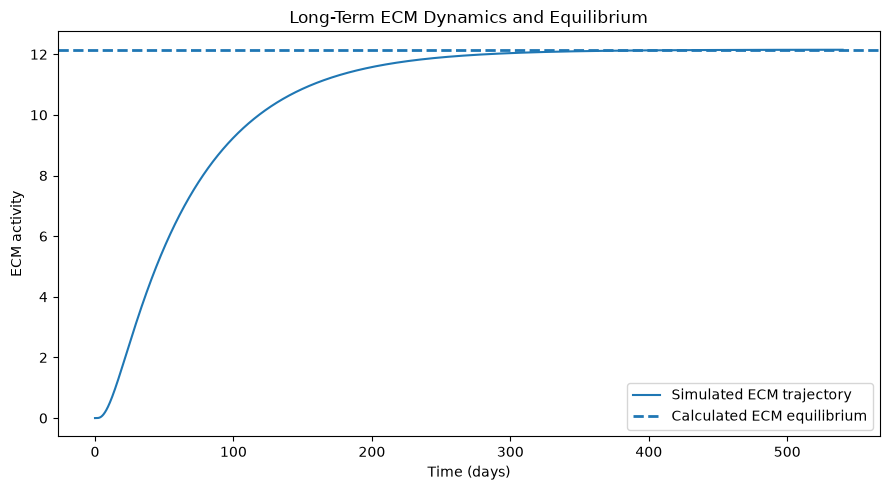

In [166]:

# Identify positive, locally stable equilibrium samples
stable_positive_ids = stability_results.loc[
    (stability_results["Equilibrium_Type"] == "Positive")
    & (
        stability_results["Local_Stability"]
        == "Locally asymptotically stable"
    ),
    "Sample_ID"
]

positive_candidates = equilibrium_results[
    equilibrium_results["Sample_ID"].isin(stable_positive_ids)
].copy()

if positive_candidates.empty:
    raise ValueError(
        "No positive, locally stable equilibrium samples found."
    )

# Select a representative sample near the median ECM equilibrium
target_ecm = positive_candidates["C_equilibrium"].median()

selected_row = positive_candidates.iloc[
    (
        positive_candidates["C_equilibrium"] - target_ecm
    ).abs().argmin()
]

selected_id = selected_row["Sample_ID"]

# Retrieve its parameter values
selected_parameter_row = lhs_samples.loc[
    lhs_samples["Sample_ID"] == selected_id
].iloc[0]

p_selected = {
    name: float(selected_parameter_row[name])
    for name in parameter_names
}

# Calculate its equilibrium
selected_equilibrium, selected_threshold, selected_type = (
    find_equilibrium(p_selected)
)


# Define the ODE system for long-term simulation
def model_A_rhs(t, y, p):

    I, S, R, M, T, F, C = y

    # Transient inflammatory input during the first two days
    u = 0.2 if t <= 2.0 else 0.0

    dI = (
        u
        + p["beta_R"] * R
        + p["beta_M"] * M
        - p["delta_I"] * I
    )

    dS = (
        p["p_S"] * I
        - p["delta_S"] * S
    )

    dR = (
        p["alpha_R"] * saturation(S, p["K_S"])
        - p["delta_R"] * R
    )

    dM = (
        p["alpha_M"] * saturation(I, p["K_I"])
        - p["delta_M"] * M
    )

    dT = (
        p["alpha_T"] * saturation(M, p["K_M"])
        - p["delta_T"] * T
    )

    dF = (
        p["alpha_FR"] * saturation(R, p["K_FR"])
        + p["alpha_FT"] * saturation(T, p["K_FT"])
        - p["delta_F"] * F
    )

    dC = (
        p["p_C"] * F
        - p["delta_C"] * C
    )

    return [dI, dS, dR, dM, dT, dF, dC]


# Simulate over 540 days
t_eval_long = np.linspace(0, 540, 2701)
initial_conditions = np.zeros(7)

long_solution = solve_ivp(
    fun=lambda t, y: model_A_rhs(t, y, p_selected),
    t_span=(0, 540),
    y0=initial_conditions,
    method="DOP853",
    t_eval=t_eval_long,
    rtol=1e-8,
    atol=1e-10,
    max_step=0.05
)

if not long_solution.success:
    raise RuntimeError(long_solution.message)


# Organize trajectory results
long_trajectory = pd.DataFrame(
    long_solution.y.T,
    columns=["I", "S", "R", "M", "T", "F", "C"]
)

long_trajectory.insert(
    0, "Time_days", long_solution.t
)

# Display selected sample information
print("Selected sample:", selected_id)
print(f"Feedback threshold: {selected_threshold:.6f}")
print("Equilibrium classification:", selected_type)
print(
    f"Calculated ECM equilibrium: "
    f"{selected_equilibrium['C']:.6f}"
)

# Plot ECM trajectory and calculated equilibrium
plt.figure(figsize=(9, 5))

plt.plot(
    long_trajectory["Time_days"],
    long_trajectory["C"],
    label="Simulated ECM trajectory"
)

plt.axhline(
    selected_equilibrium["C"],
    linestyle="--",
    linewidth=2,
    label="Calculated ECM equilibrium"
)

plt.xlabel("Time (days)")
plt.ylabel("ECM activity")
plt.title("Long-Term ECM Dynamics and Equilibrium")
plt.legend()
plt.tight_layout()
plt.show()

# Save trajectory
long_trajectory.to_csv(
    results_dir / "selected_sample_long_term_trajectory.csv",
    index=False
)


## 9. Quantitative Assessment of Long-Term Equilibrium Convergence

The simulated ECM trajectory is compared quantitatively with its analytically calculated equilibrium value.

The absolute and relative differences between the final simulated ECM activity and the equilibrium estimate are calculated to assess numerical convergence over the 540-day simulation horizon.

This comparison provides a numerical verification for the selected parameter sample and does not establish global convergence across all possible initial conditions.


In [ ]:

# Extract final simulated ECM value
final_simulated_ecm = long_trajectory["C"].iloc[-1]

# Obtain calculated equilibrium ECM
calculated_ecm_equilibrium = selected_equilibrium["C"]

# Calculate absolute and relative differences
absolute_difference = abs(
    final_simulated_ecm - calculated_ecm_equilibrium
)

relative_difference = (
    absolute_difference / abs(calculated_ecm_equilibrium)
    if abs(calculated_ecm_equilibrium) > 1e-12
    else np.nan
)

# Calculate percentage difference
percentage_difference = relative_difference * 100

# Create comparison table
convergence_summary = pd.DataFrame({
    "Metric": [
        "Final simulated ECM",
        "Calculated ECM equilibrium",
        "Absolute difference",
        "Relative difference",
        "Percentage difference"
    ],
    "Value": [
        final_simulated_ecm,
        calculated_ecm_equilibrium,
        absolute_difference,
        relative_difference,
        percentage_difference
    ]
})

display(convergence_summary)

# Save results
convergence_summary.to_csv(
    results_dir / "long_term_equilibrium_convergence.csv",
    index=False
)

print(
    f"Final simulation time: "
    f"{long_trajectory['Time_days'].iloc[-1]:.1f} days"
)


,Metric,Value
0,Final simulated ECM,12.149644
1,Calculated ECM equilibrium,12.151951
2,Absolute difference,0.002307
3,Relative difference,0.000190
4,Percentage difference,0.018985


Final simulation time: 540.0 days



## 10. Results Interpretation and Conclusions

### 10.1 Equilibrium Structure

The equilibrium analysis across 200 Latin Hypercube Sampling parameter sets identified 167 disease-free equilibria and 33 positive equilibria.

All calculated equilibria were classified as locally asymptotically stable based on the maximum real parts of their Jacobian eigenvalues.

The distinction between equilibrium types was consistent with the model-specific feedback threshold: samples with a threshold below one exhibited disease-free equilibria, whereas samples with a threshold above one exhibited positive equilibria.

### 10.2 Long-Term ECM Dynamics

The extended simulation of representative Sample 144 demonstrated convergence toward a positive ECM equilibrium following a transient inflammatory stimulus.

The calculated ECM equilibrium was 12.151951, while the final simulated ECM activity after 540 days was 12.149644.

The relative difference was approximately 0.018985%, indicating close numerical agreement between the simulated trajectory and the analytically calculated equilibrium.

### 10.3 Mathematical Interpretation

These results suggest that the proposed model can exhibit two distinct equilibrium regimes depending on parameter values.

In the disease-free regime, the system approaches a zero-activity equilibrium in the absence of external inflammatory input.

In the positive-equilibrium regime, the system can approach a non-zero profibrotic state even after the external inflammatory stimulus has been removed.

This behavior provides a mathematical representation of persistent profibrotic activity under sustained internal feedback within the proposed model.

### 10.4 Limitations

The equilibrium results are conditional on the assumed model structure and parameter distributions.

The 200 parameter samples do not represent 200 independent patients or clinical observations. The extended trajectory was evaluated for one representative parameter sample and should not be interpreted as evidence of identical behavior across all parameter sets.

The model also does not establish irreversible fibrosis or clinical persistence in patients. Further biological validation and quantitative parameter calibration are required.

### 10.5 Conclusion

The extended mathematical analysis demonstrates that the proposed nonlinear ODE framework supports both disease-free and positive stable equilibria across the investigated parameter space.

The long-term simulation provides a numerical demonstration that a transient inflammatory stimulus can lead to persistent non-zero ECM activity in a parameter regime with a stable positive equilibrium.

These findings motivate further investigation of the metabolic and immune–stromal feedback mechanisms potentially contributing to persistent intestinal fibrostenosis in Crohn's disease.


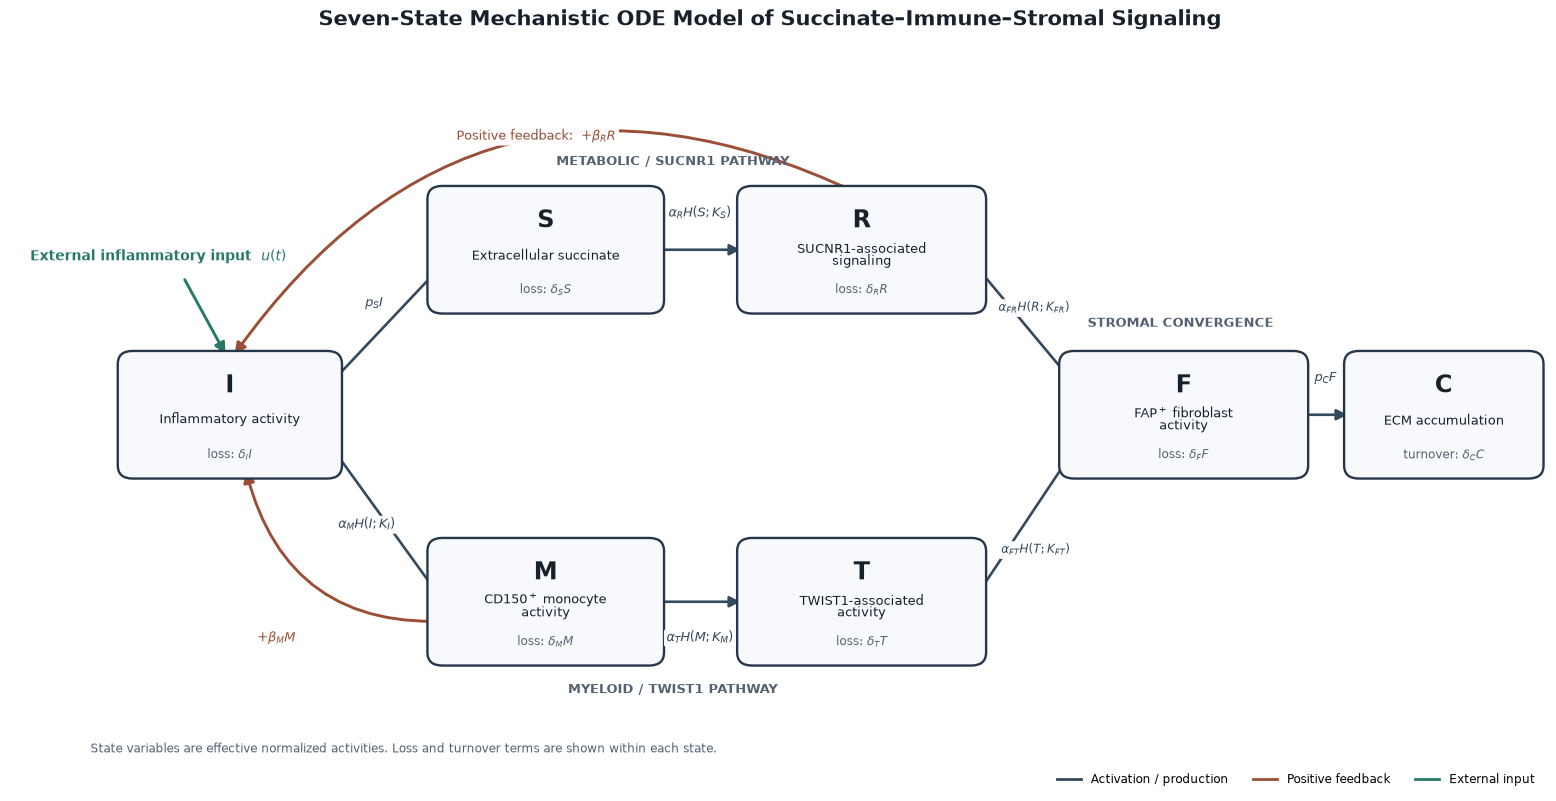

Model structure figures saved successfully.
Output directory: /workspaces/crohns-fibrostenosis-ode-model/figures


In [174]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

# ============================================================
# OUTPUT DIRECTORY
# ============================================================
OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# FIGURE CANVAS
# ============================================================
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xlim(-0.6, 11.8)
ax.set_ylim(-0.7, 5.6)
ax.axis("off")

# ============================================================
# SEVEN STATE VARIABLES
# ============================================================
nodes = {
    "I": (
        0.35, 2.15, 1.65, 1.00,
        "I", "Inflammatory activity",
        r"loss: $\delta_I I$"
    ),
    "S": (
        2.85, 3.65, 1.75, 1.00,
        "S", "Extracellular succinate",
        r"loss: $\delta_S S$"
    ),
    "R": (
        5.35, 3.65, 1.85, 1.00,
        "R", "SUCNR1-associated\nsignaling",
        r"loss: $\delta_R R$"
    ),
    "M": (
        2.85, 0.45, 1.75, 1.00,
        "M", "CD150$^+$ monocyte\nactivity",
        r"loss: $\delta_M M$"
    ),
    "T": (
        5.35, 0.45, 1.85, 1.00,
        "T", "TWIST1-associated\nactivity",
        r"loss: $\delta_T T$"
    ),
    "F": (
        7.95, 2.15, 1.85, 1.00,
        "F", "FAP$^+$ fibroblast\nactivity",
        r"loss: $\delta_F F$"
    ),
    "C": (
        10.25, 2.15, 1.45, 1.00,
        "C", "ECM accumulation",
        r"turnover: $\delta_C C$"
    )
}

# ============================================================
# DRAW STATE NODES
# ============================================================
for key, (x, y, w, h, symbol, desc, loss) in nodes.items():

    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        linewidth=1.7,
        edgecolor="#25364A",
        facecolor="#F7F9FC",
        zorder=3
    )

    ax.add_patch(box)

    ax.text(
        x + w/2, y + h*0.76,
        symbol,
        ha="center",
        va="center",
        fontsize=17,
        fontweight="bold",
        color="#17212B",
        zorder=4
    )

    ax.text(
        x + w/2, y + h*0.46,
        desc,
        ha="center",
        va="center",
        fontsize=9.2,
        color="#17212B",
        linespacing=1.05,
        zorder=4
    )

    ax.text(
        x + w/2, y + h*0.13,
        loss,
        ha="center",
        va="center",
        fontsize=8.6,
        color="#526273",
        zorder=4
    )

# ============================================================
# ARROW FUNCTIONS
# ============================================================
def curved_arrow(
    start,
    end,
    color="#34495E",
    rad=0.0,
    lw=1.9
):
    patch = FancyArrowPatch(
        start,
        end,
        arrowstyle="-|>",
        mutation_scale=16,
        linewidth=lw,
        color=color,
        connectionstyle=f"arc3,rad={rad}",
        shrinkA=2,
        shrinkB=2,
        zorder=2
    )
    ax.add_patch(patch)


def edge_label(
    x,
    y,
    label,
    color="#34495E",
    fontsize=9
):
    ax.text(
        x,
        y,
        label,
        ha="center",
        va="center",
        fontsize=fontsize,
        color=color,
        bbox=dict(
            boxstyle="round,pad=0.20",
            fc="white",
            ec="none",
            alpha=0.96
        ),
        zorder=5
    )

# ============================================================
# EXTERNAL INFLAMMATORY INPUT
# ============================================================
ax.text(
    0.60, 4.05,
    r"External inflammatory input  $u(t)$",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#287A68"
)

curved_arrow(
    (0.80, 3.90),
    (1.15, 3.18),
    color="#287A68",
    lw=2.1
)

# ============================================================
# METABOLIC / SUCNR1 PATHWAY
# ============================================================
curved_arrow(
    (2.00, 2.95),
    (2.88, 4.00)
)
edge_label(2.34, 3.66, r"$p_S I$")

curved_arrow(
    (4.62, 4.15),
    (5.32, 4.15)
)
edge_label(4.97, 4.48, r"$\alpha_R H(S;K_S)$")

# ============================================================
# MYELOID / TWIST1 PATHWAY
# ============================================================
curved_arrow(
    (2.00, 2.35),
    (2.88, 0.98)
)
edge_label(2.28, 1.65, r"$\alpha_M H(I;K_I)$")

curved_arrow(
    (4.62, 0.95),
    (5.32, 0.95)
)
edge_label(4.97, 0.62, r"$\alpha_T H(M;K_M)$")

# ============================================================
# POSITIVE FEEDBACK LOOPS
# ============================================================
curved_arrow(
    (6.25, 4.66),
    (1.20, 3.18),
    color="#9A4F36",
    rad=0.42,
    lw=2.1
)

edge_label(
    3.65, 5.18,
    r"Positive feedback:  $+\beta_R R$",
    color="#9A4F36",
    fontsize=9.2
)

curved_arrow(
    (3.00, 0.78),
    (1.30, 2.16),
    color="#9A4F36",
    rad=-0.42,
    lw=2.1
)

edge_label(
    1.55, 0.62,
    r"$+\beta_M M$",
    color="#9A4F36",
    fontsize=9.2
)

# ============================================================
# CONVERGENCE ON FAP+ FIBROBLAST ACTIVITY
# ============================================================
curved_arrow(
    (7.20, 4.00),
    (8.00, 2.92)
)

edge_label(
    7.67, 3.62,
    r"$\alpha_{FR}H(R;K_{FR})$",
    fontsize=8.7
)

curved_arrow(
    (7.20, 1.00),
    (8.00, 2.35)
)

edge_label(
    7.68, 1.42,
    r"$\alpha_{FT}H(T;K_{FT})$",
    fontsize=8.7
)

# ============================================================
# ECM PRODUCTION
# ============================================================
curved_arrow(
    (9.82, 2.65),
    (10.22, 2.65)
)

edge_label(
    10.02, 2.98,
    r"$p_C F$"
)

# ============================================================
# PATHWAY HEADINGS
# ============================================================
ax.text(
    4.75, 4.92,
    "METABOLIC / SUCNR1 PATHWAY",
    ha="center",
    fontsize=9.5,
    fontweight="bold",
    color="#526273"
)

ax.text(
    4.75, 0.12,
    "MYELOID / TWIST1 PATHWAY",
    ha="center",
    fontsize=9.5,
    fontweight="bold",
    color="#526273"
)

ax.text(
    8.85, 3.45,
    "STROMAL CONVERGENCE",
    ha="center",
    fontsize=9.5,
    fontweight="bold",
    color="#526273"
)

# ============================================================
# LEGEND
# ============================================================
ax.plot(
    [], [],
    color="#34495E",
    lw=2,
    label="Activation / production"
)

ax.plot(
    [], [],
    color="#9A4F36",
    lw=2,
    label="Positive feedback"
)

ax.plot(
    [], [],
    color="#287A68",
    lw=2,
    label="External input"
)

ax.legend(
    loc="lower right",
    bbox_to_anchor=(1.0, -0.02),
    frameon=False,
    fontsize=8.8,
    ncol=3
)

# ============================================================
# FOOTNOTE
# ============================================================
ax.text(
    0.05, -0.42,
    "State variables are effective normalized activities. "
    "Loss and turnover terms are shown within each state.",
    fontsize=8.5,
    color="#526273",
    ha="left"
)

# ============================================================
# TITLE AND LAYOUT
# ============================================================
fig.suptitle(
    "Seven-State Mechanistic ODE Model of "
    "Succinate–Immune–Stromal Signaling",
    fontsize=15,
    fontweight="bold",
    y=0.98,
    color="#17212B"
)

fig.subplots_adjust(
    left=0.025,
    right=0.985,
    top=0.89,
    bottom=0.12
)

# ============================================================
# SAVE PUBLICATION-QUALITY OUTPUTS
# ============================================================
fig.savefig(
    OUTPUT_DIR / "seven_state_model_structure.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_DIR / "seven_state_model_structure.svg",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_DIR / "seven_state_model_structure.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Model structure figures saved successfully.")
print("Output directory:", OUTPUT_DIR.resolve())
